# MEA — аналитическая платформа биржевых событий: отчёт EDA

**Витрина результатов.** Этот ноутбук ничего не считает по озеру данных: каждая таблица и каждый
рисунок читаются из готовых артефактов, которые экспортирует конвейер (`mea export-report`), и под
каждым рисунком стоит подпись — файл-источник, число строк, дата и commit. Те же артефакты лежат в
основе текстового отчёта `MEA_RESULTS.md`; расхождений между ними быть не может по построению.

Период разработки (dev) — до **30.06.2025** включительно; холдаут за этой границей не открывался.
Каждое число — с 95 % интервалом: доли — Уилсон; ряды — блочный бутстрэп; величины по бумагам —
бутстрэп по бумагам; событийные величины — бутстрэп **по датам**. Выводы ведутся по размеру эффекта,
p-значения идут справкой.

**Содержание**

1. [Что построено: слои данных](#1) — конвейер, дедуп, привязка, правило дня события, ценовой слой
2. [Описательная часть](#2) — корпус новостей, тональность, хвосты, автокорреляция, объём/волатильность, внутридневная сезонность, календарь
3. [Новости и рынок вместе](#3) — четыре контроля, доза, реакция против ассоциации
4. [Гипотезы](#4) — аппарат BMP/KP, H1/H1b, знаковая реакция, H15, H16, H19, раунд 2
5. [ML-зонды](#5) — карта сюжетов на эмбеддингах, вклад новостей сверх цен, типы по слабым меткам, **одна бумага крупным планом**
6. [Контроль против самообмана](#6)
7. [Чего не измерено](#7)
8. [Что получилось: семь утверждений](#8)

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore", category=FutureWarning)
sys.path.insert(0, os.path.abspath("notebooks") if os.path.isdir("notebooks") else os.path.abspath("."))
from mea_report_nb import (Store, style, COLORS, SEQ_BLUE, CATEGORICAL, market_color, fmt, fmt_int, fmt_ci, pct,
                           ru_axis, despine_all, zero_line, ci_dots, note, label_bars, df_html, stat_tiles, md,
                           display, HTML, Markdown)
from contract import CONTRACT

style()
S = Store.auto()
S.banner()

бэкенд,local — /root/mea/data/cache/report
снимок артефактов,2026-11-10T00:55:27
commit конвейера,a99acb9-dirty
период разработки,до 2025-06-30 включительно; холдаут не открывался


### Карта артефактов

Что откуда берётся. «НЕТ» означает, что экспорт ещё не отдал файл — соответствующий рисунок ниже
показан заглушкой, а не ошибкой. Приоритет P1 — без этого витрина для защиты неполна.

In [2]:
_status = S.status_table(CONTRACT)
_miss = _status[_status["статус"] == "НЕТ"]
md(f"Артефактов в контракте: **{len(_status)}**, найдено **{(_status['статус']=='есть').sum()}**, "
   f"отсутствует **{len(_miss)}**" + (" — " + ", ".join(f"`{n}`" for n in _miss["артефакт"]) if len(_miss) else "."))

раздел,артефакт,приоритет,назначение,статус,строк,обновлён
0,manifest,P1,"generated_at, git_commit, dev_end, demo(bool), artifacts{name:{file,rows,mtime,producer}}",есть,,2026-11-10 00:55
1.1,layers,P1,"слой конвейера: layer, rows, period_from, period_to, note (порядок = порядок конвейера)",есть,9,2026-11-10T00:55:09
1.1,docs_monthly,P1,"month(YYYY-MM), market(RU/US), source_class(пресса/раскрытия/агрегаторы/прочее), docs",есть,459,2026-11-10T00:55:20
1.1,docs_by_source,P2,"market, source, docs, share, first_date, last_date — топ-20 источников на рынок",есть,4,2026-11-10T00:55:22
1.2,dedup,P2,"docs_total, after_exact, after_near, clusters, mega_cluster_empty_sha, minhash{perm,shingle,jaccard,window_days}",есть,,2026-11-10T00:55:22
1.3,attribution_funnel,P1,"{RU:{stages:[{name,error}], holdout:{id,n,error,lo,hi,strict_precision,loss_true}}, EN:{…}} — ошибки в долях",есть,,2026-11-10T00:55:09
1.4,time_precision,P1,"market, source_class, precision(минута/только дата), events",есть,14,2026-11-10T00:55:09
1.5,seam_returns,P2,"basis(close/adj_close), where(внутри источника/шов), median_abs_r, p99, share_gt_25",есть,4,2026-11-10T00:55:09
1.5,price_layer,P1,"excluded_tapes, excluded_tickers, cut_tapes, dropped_days, event_days_total, event_days_no_window, unexplained_total, unexplained_share, unexplained_in_window, detector('|log r|>2')",есть,,2026-11-10T00:55:09
1.5,price_jumps_by_year,P2,"tape, year, jumps, explained",есть,74,2026-11-10T00:55:22


Артефактов в контракте: **69**, найдено **64**, отсутствует **5** — `doc_length`, `kurtosis_sensitivity`, `gainloss_asym`, `exdate_dist`, `c1_cluster_types`

<a id="1"></a>
## 1. Что построено: слои данных и как они собраны

```
docs (сырые документы)
  → clusters      дедупликация: точное совпадение + MinHash/LSH
  → doc_flags     бойлерплейт, язык, подозрительная дата, price-recap
  → mentions      привязка документа к эмитенту (алиасы + роли + ярус)
  → events        событие = (документ × бумага) с ярусом ≥ порога
  → features      признаки по (бумага, день)
quotes (бары)
  → adj_prices    цена, скорректированная на корпоративные действия
  → targets       цели: аномальная доходность, объём, окна
```

### 1.1 Конвейер и объём слоёв

слой,строк,с,по,что это
docs,60 514 056,—,—,документы
clusters,9 840 199,—,—,сюжеты (дедуп)
doc_extra,42 405 648,—,—,бойлерплейт и словарная тональность
mentions,28 949 505,—,—,упоминания эмитентов
events_v2,13 799 861,—,—,события (документ x бумага)
features_v2,9 239 314,—,—,"признаки (бумага, день)"
edgar_filings,2 498 992,—,—,подачи SEC
quotes,819 591 071,—,—,бары котировок
adj_prices,31 404 275,—,—,слой скорректированных цен


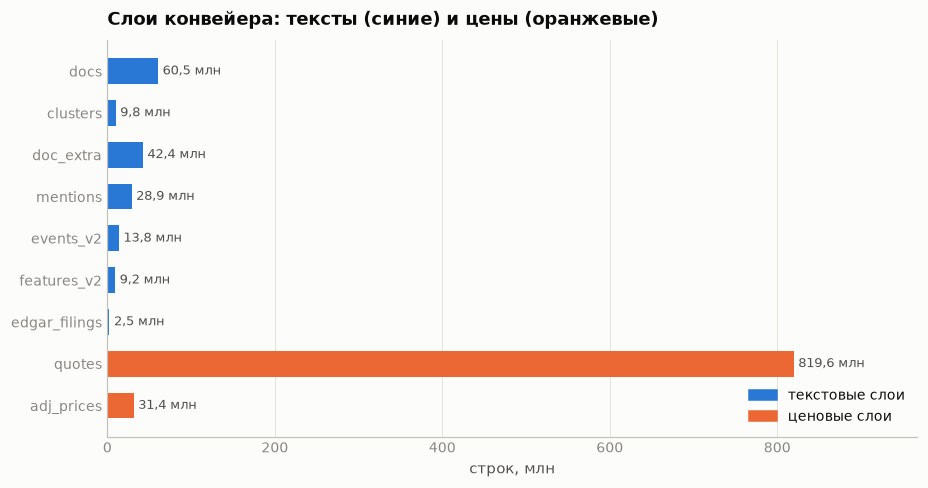

In [3]:
S.show_table("layers", title="Слои данных",
             columns={"layer": "слой", "rows": "строк", "period_from": "с", "period_to": "по", "note": "что это"},
             formats={"rows": fmt_int})

@S.show("layers", title="Объём слоёв")
def _(layers):
    d = layers.copy()
    d["rows_m"] = d["rows"] / 1e6
    fig, ax = plt.subplots(figsize=(9.5, 0.42 * len(d) + 0.9))
    cols = [COLORS["RU"] if l in ("docs", "clusters", "doc_extra", "doc_sent_v2", "mentions", "events_v2", "features_v2", "edgar_filings")
            else COLORS["US"] for l in d["layer"]]
    bars = ax.barh(d["layer"][::-1], d["rows_m"][::-1], color=cols[::-1], height=0.62)
    label_bars(ax, bars, fmt_fn=lambda v: fmt(v, 1) + " млн", horizontal=True)
    ax.set_xlabel("строк, млн"); ax.grid(axis="x"); ax.grid(False, axis="y")
    ax.set_xlim(0, d["rows_m"].max() * 1.18)
    ax.set_title("Слои конвейера: тексты (синие) и цены (оранжевые)")
    ax.legend(handles=[Patch(color=COLORS["RU"], label="текстовые слои"), Patch(color=COLORS["US"], label="ценовые слои")], loc="lower right")
    return fig

### 1.2 Корпус новостей во времени и по источникам

Ступень 2020 года у США — это не рынок, а **состав корпуса**: с 2020 к потоку подключаются новые
ленты. Поэтому ни в одной главе подпериоды не сравниваются между собой напрямую — сопоставление
всегда идёт внутри месяца.

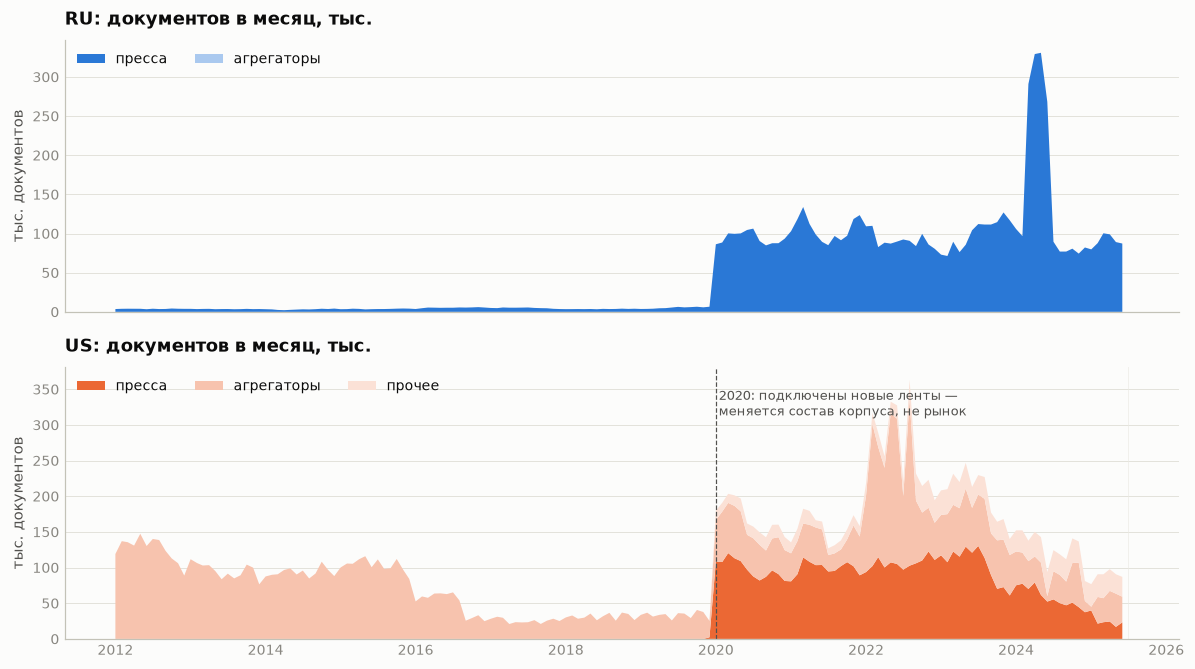

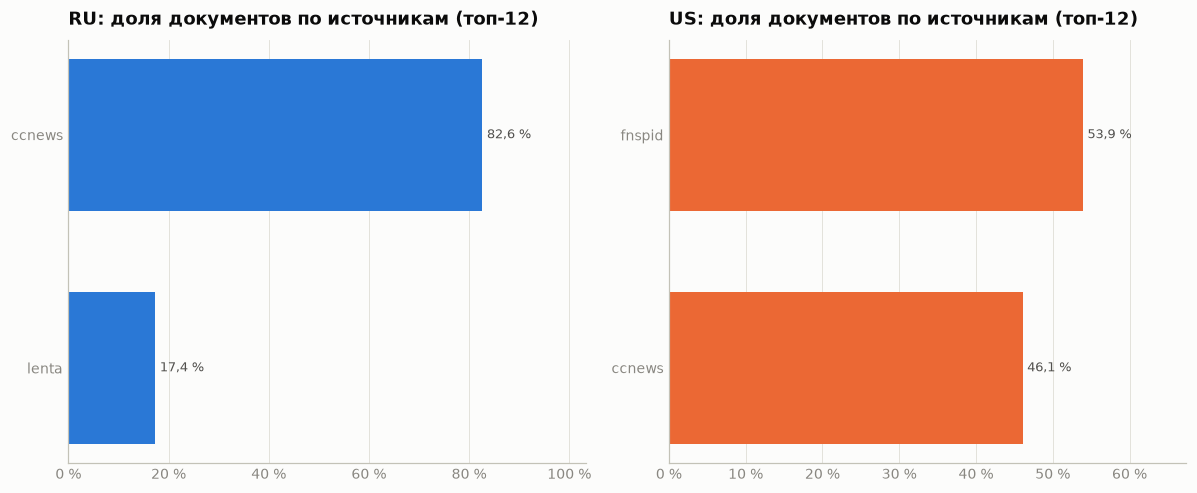

In [4]:
@S.show("docs_monthly", title="Документов в месяц по рынкам и классам источников")
def _(dm):
    dm["month"] = pd.PeriodIndex(dm["month"], freq="M").to_timestamp()
    order = ["пресса", "раскрытия", "агрегаторы", "прочее"]
    shades = {"пресса": 0.0, "раскрытия": 0.35, "агрегаторы": 0.6, "прочее": 0.8}
    fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)
    for ax, mk in zip(axes, ["RU", "US"]):
        p = dm[dm.market == mk].pivot_table(index="month", columns="source_class", values="docs", aggfunc="sum").fillna(0)
        p = p[[c for c in order if c in p.columns]] / 1e3
        base = market_color(mk)
        colors = [mpl.colors.to_hex(np.array(mpl.colors.to_rgb(base)) * (1 - shades[c]) + np.array([1, 1, 1]) * shades[c]) for c in p.columns]
        ax.stackplot(p.index, p.T.values, labels=p.columns, colors=colors, lw=0)
        ax.set_title(f"{mk}: документов в месяц, тыс."); ax.set_ylabel("тыс. документов")
        ax.legend(loc="upper left", ncol=4)
        ru_axis(ax, "y", 0)
        if mk == "US":
            ax.axvline(pd.Timestamp("2020-01-01"), color=COLORS["ink2"], lw=0.8, ls="--")
            ax.annotate("2020: подключены новые ленты —\nменяется состав корпуса, не рынок", (pd.Timestamp("2020-01-15"), ax.get_ylim()[1] * 0.92),
                        fontsize=8.5, color=COLORS["ink2"], va="top")
    axes[1].axvspan(pd.Timestamp("2025-07-01"), dm["month"].max() + pd.Timedelta(days=31), color=COLORS["band"], alpha=0.6, lw=0)
    fig.tight_layout()
    return fig

@S.show("docs_by_source", title="Крупнейшие источники")
def _(ds):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, mk in zip(axes, ["RU", "US"]):
        d = ds[ds.market == mk].sort_values("docs", ascending=True).tail(12)
        bars = ax.barh(d["source"], d["share"], color=market_color(mk), height=0.65)
        label_bars(ax, bars, fmt_fn=lambda v: pct(v, 1), horizontal=True)
        ax.set_title(f"{mk}: доля документов по источникам (топ-12)"); ax.grid(axis="x"); ax.grid(False, axis="y")
        ru_axis(ax, "x", 0, pct_axis=True); ax.set_xlim(0, d["share"].max() * 1.25)
    fig.tight_layout()
    return fig

### 1.3 Дедупликация

Точное совпадение по хэшу текста, затем near-duplicate: MinHash (128 перестановок, шинглы по 5 слов,
порог Жаккара 0,9), скользящее окно ±3 дня, склейка компонент связности. На этом этапе был пойман
мега-кластер из 10,3 млн документов с SHA-1 **пустой строки** — у них нет текста; ключ дедупа после
этого стал многоуровневым: текст → заголовок → `doc_id`.

In [5]:
@S.show("dedup", title="Дедупликация")
def _(d):
    display(stat_tiles([
        (fmt(d["docs_total"] / 1e6, 1) + " млн", "документов всего", "слой docs"),
        (fmt(d["after_exact"] / 1e6, 1) + " млн", "после точных дублей", "хэш текста"),
        (fmt(d["after_near"] / 1e6, 1) + " млн", "после near-dup", f"MinHash {d['minhash']['perm']} перест., Жаккар {fmt(d['minhash']['jaccard'],1)}"),
        (fmt(d["mega_cluster_empty_sha"] / 1e6, 1) + " млн", "мега-кластер пустого текста", "пойман и разобран по заголовку/doc_id"),
    ]))
    return None

### 1.4 Привязка документа к эмитенту

Словарь алиасов + Ахо-Корасик с границами слова, 21 русское падежное окончание, роли упоминаний
(`subject`, `context`, `source`, `analyst`, `reference`) и ярус релевантности 10…100. Ярус —
единственные ворота событий; основной анализ идёт по `score = 100`. Качество измерено на
размеченных холдаутах по 400 документов на язык.

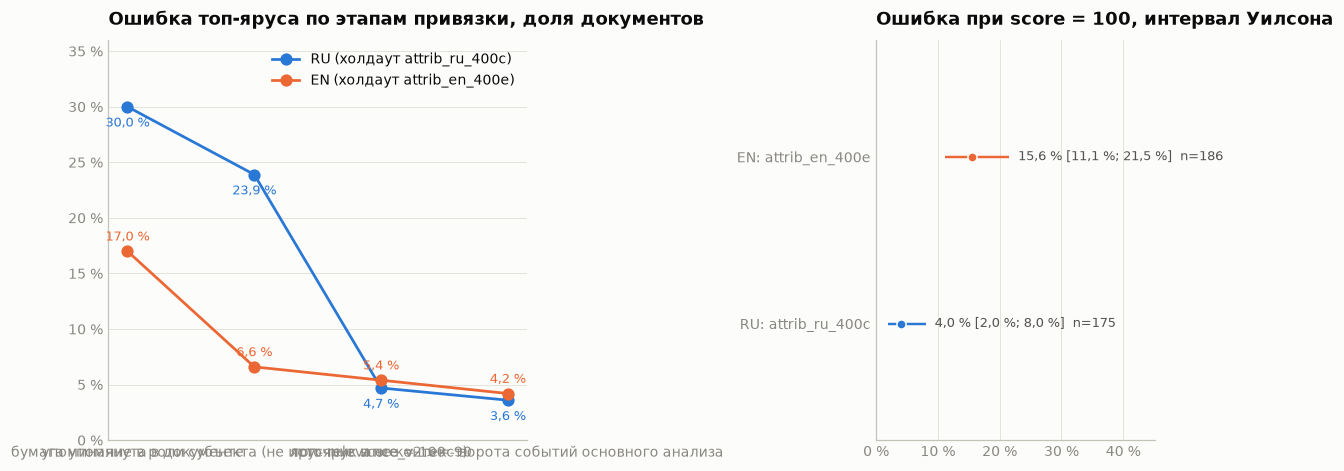

язык,холдаут,n,ошибка при score=100,строгая точность,потеря истинных
RU,attrib_ru_400c,175,"4,0 [2,0; 8,0] %","90,3 %","35,4 %"
EN,attrib_en_400e,186,"15,6 [11,1; 21,5] %","76,3 %","42,7 %"


In [6]:
@S.show("attribution_funnel", title="Воронка привязки")
def _(f):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})
    ax = axes[0]
    for lang, mk in (("RU", "RU"), ("EN", "US")):
        st = f[lang]["stages"]
        x = np.arange(len(st)); y = [s["error"] for s in st]
        ax.plot(x, y, "-o", color=market_color(mk), label=f"{lang} (холдаут {f[lang]['holdout']['id']})", ms=7)
        for xi, yi in zip(x, y):
            ax.annotate(pct(yi, 1), (xi, yi), xytext=(0, 7 if lang == "EN" else -13), textcoords="offset points", ha="center", fontsize=8.5, color=market_color(mk))
        ax.set_xticks(x); ax.set_xticklabels([s["name"] for s in st])
    ax.set_title("Ошибка топ-яруса по этапам привязки, доля документов"); ru_axis(ax, "y", 0, pct_axis=True)
    ax.set_ylim(0, 0.36); ax.legend()
    ax = axes[1]
    ys = []
    for i, (lang, mk) in enumerate((("RU", "RU"), ("EN", "US"))):
        h = f[lang]["holdout"]
        ci_dots(ax, [i], [h["error"]], [h["lo"]], [h["hi"]], market_color(mk))
        ax.annotate(f"{pct(h['error'],1)} [{pct(h['lo'],1)}; {pct(h['hi'],1)}]  n={h['n']}", (h["hi"], i), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=8.5, color=COLORS["ink2"])
        ys.append(f"{lang}: {h['id']}")
    ax.set_yticks([0, 1]); ax.set_yticklabels(ys); ax.set_ylim(-0.7, 1.7); ax.set_xlim(0, max(f[l]["holdout"]["hi"] for l in ("RU", "EN")) * 2.1)
    ax.set_title("Ошибка при score = 100, интервал Уилсона"); ru_axis(ax, "x", 0, pct_axis=True); ax.grid(axis="x"); ax.grid(False, axis="y")
    fig.tight_layout()
    rows = [{"язык": lang, "холдаут": f[lang]["holdout"]["id"], "n": f[lang]["holdout"]["n"],
             "ошибка при score=100": fmt_ci(f[lang]["holdout"]["error"] * 100, f[lang]["holdout"]["lo"] * 100, f[lang]["holdout"]["hi"] * 100, 1) + " %",
             "строгая точность": pct(f[lang]["holdout"]["strict_precision"], 1), "потеря истинных": pct(f[lang]["holdout"]["loss_true"], 1)} for lang in ("RU", "EN")]
    return [fig, pd.DataFrame(rows)]

### 1.5 Правило дня события (safe bar) и точность времени

Публикация отображается на торговый день так: **любой момент внутри календарного дня D относится к
открытию следующей сессии**, если время внутри дня неизвестно; если известно — подача до 16:00 по
бирже идёт в тот же день, позже — в следующий. Правило определяет всё остальное, потому что у
большинства событий в отметке публикации стоит ровно полночь: известна только дата.

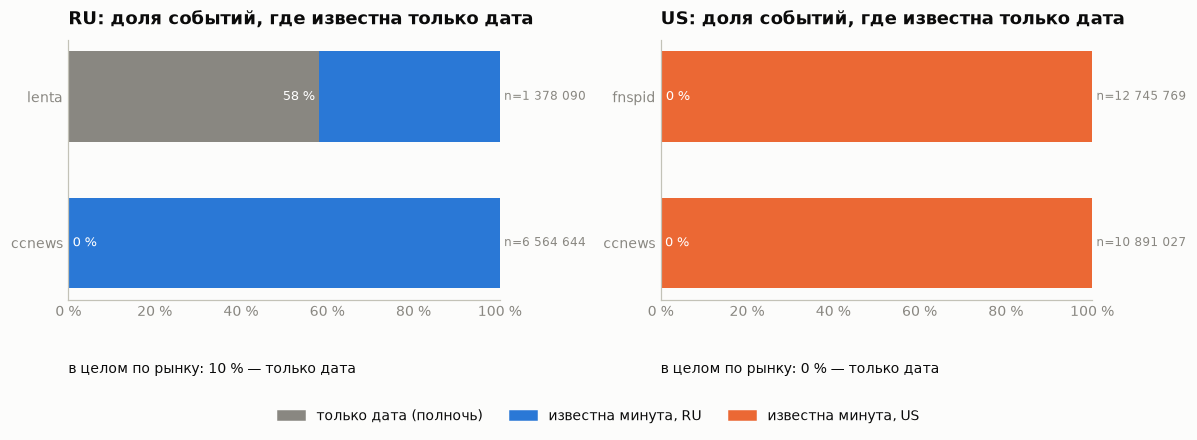

In [7]:
@S.show("time_precision", title="Точность отметки времени по источникам")
def _(tp):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
    for ax, mk in zip(axes, ["RU", "US"]):
        d = tp[tp.market == mk].pivot_table(index="source_class", columns="precision", values="events", aggfunc="sum").fillna(0)
        if d.empty:
            ax.set_axis_off(); ax.set_title(f"{mk}: нет данных"); continue
        tot = d.sum(axis=1); share = (d.T / tot).T
        share = share.sort_values("только дата") if "только дата" in share else share
        y = np.arange(len(share))
        a = share.get("только дата", pd.Series(0, index=share.index)).to_numpy()
        b = share.get("минута", pd.Series(0, index=share.index)).to_numpy()
        ax.barh(y, a, color=COLORS["muted"], height=0.62, label="только дата (полночь)")
        ax.barh(y, b, left=a, color=market_color(mk), height=0.62, label="известна минута")
        for yi, ai, n in zip(y, a, tot.loc[share.index]):
            if ai > 0.12:
                ax.text(ai - 0.01, yi, pct(ai, 0), va="center", ha="right", fontsize=8.5, color="#ffffff")
            else:
                ax.text(ai + 0.01, yi, pct(ai, 0), va="center", ha="left", fontsize=8.5, color="#ffffff")
            ax.text(1.01, yi, f"n={fmt_int(n)}", va="center", fontsize=8, color=COLORS["muted"])
        ax.set_yticks(y); ax.set_yticklabels(share.index); ax.set_xlim(0, 1.0); ax.grid(False)
        ru_axis(ax, "x", 0, pct_axis=True); ax.set_title(f"{mk}: доля событий, где известна только дата")
        w = (a * tot.loc[share.index]).sum() / tot.sum()
        ax.annotate(f"в целом по рынку: {pct(w, 0)} — только дата", (0.0, -0.28), xycoords="axes fraction", fontsize=9, color=COLORS["ink"])
    # В легенде показываем оба цвета рынка, а не чёрный образец:
    # чёрного на рисунке нет.
    fig.legend(handles=[Patch(color=COLORS["muted"], label="только дата (полночь)"),
                        Patch(color=market_color("RU"), label="известна минута, RU"),
                        Patch(color=market_color("US"), label="известна минута, US")],
               loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
    fig.tight_layout()
    return fig

### 1.6 Ценовой слой

Три решения принципиальны. **Коэффициенты дробления акций не выводятся из отношения цен** (TRNFP давал
«1:104» вместо 1:100) — применяются только документально подтверждённые. **Доходность через стык
двух лент не существует**: окна анализа лежат целиком внутри одной ленты. **Единая точка чтения**
`prices_select`: отсев лент по качеству и обрезки применяются при чтении, а не в слое — иначе
качество, посчитанное из слоя, фильтровало бы сам слой (круговая зависимость; при её разрыве 197
лент, помеченных плохими, оказались здоровыми).

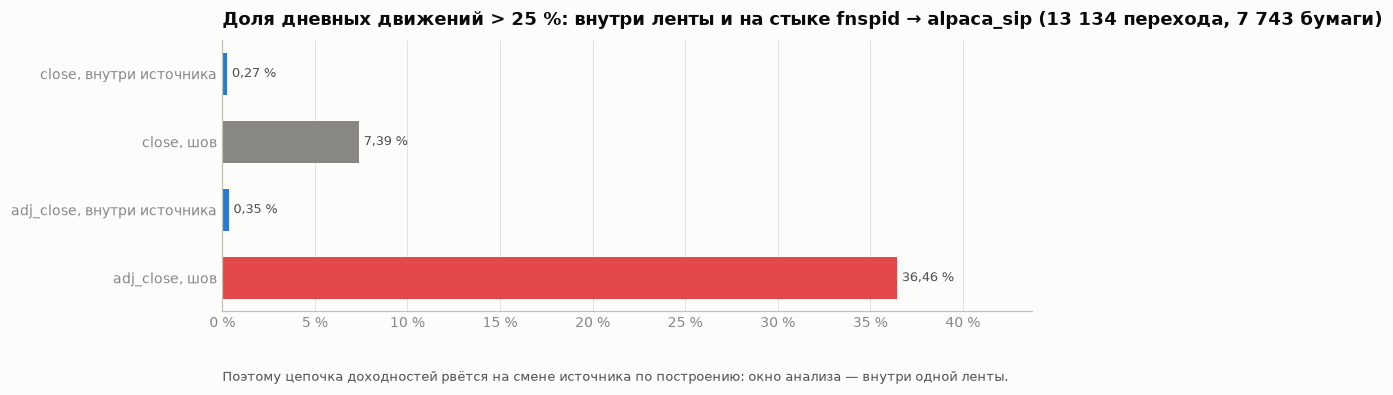

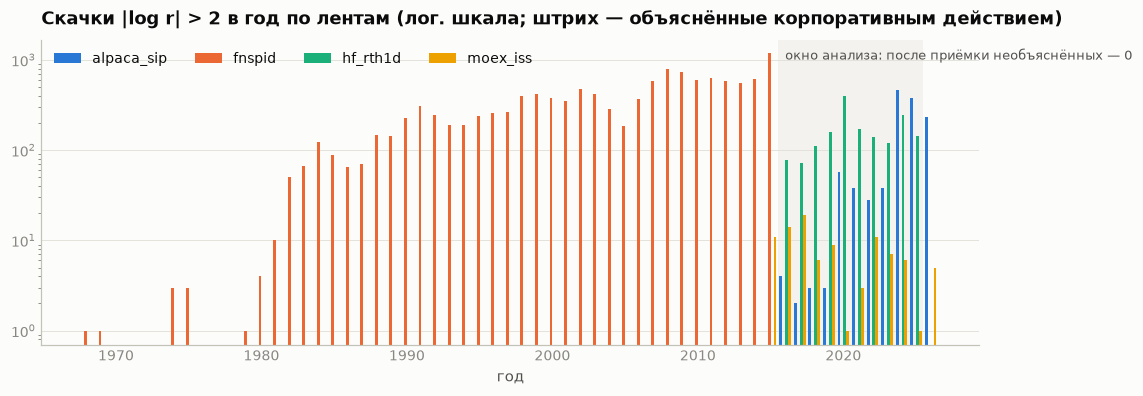

In [8]:
@S.show("price_layer", title="Цена дисциплины ценового слоя")
def _(p):
    display(stat_tiles([
        (fmt_int(p["excluded_tapes"]), "лент исключено", f"{fmt_int(p['excluded_tickers'])} бумаг, по price_quality"),
        (fmt_int(p["cut_tapes"]), "лент обрезано", "tape_cuts, с документом"),
        (fmt_int(p["dropped_days"]), "дней отброшено", "из слоя анализа"),
        (pct(p["event_days_no_window"] / p["event_days_total"], 1), "событийных дней без окна оценки",
         f"{fmt_int(p['event_days_no_window'])} из {fmt_int(p['event_days_total'])}"),
        (fmt_int(p["unexplained_in_window"]), "необъяснённых скачков в окне анализа", f"детектор {p['detector']}; всего по лентам {fmt_int(p['unexplained_total'])} = {pct(p['unexplained_share'], 3)}"),
    ], cols=5))
    return None

@S.show("seam_returns", title="Доходность через шов двух лент")
def _(sr):
    sr["label"] = sr["basis"] + ", " + sr["where"]
    fig, ax = plt.subplots(figsize=(9.5, 3.2))
    cols = [COLORS["neg"] if (w == "шов" and b == "adj_close") else (COLORS["muted"] if w == "шов" else COLORS["RU"]) for b, w in zip(sr.basis, sr["where"])]
    bars = ax.barh(sr["label"][::-1], sr["share_gt_25"][::-1], color=cols[::-1], height=0.62)
    label_bars(ax, bars, fmt_fn=lambda v: pct(v, 2), horizontal=True)
    ax.set_title("Доля дневных движений > 25 %: внутри ленты и на стыке fnspid → alpaca_sip (13 134 перехода, 7 743 бумаги)")
    ru_axis(ax, "x", 0, pct_axis=True); ax.grid(axis="x"); ax.grid(False, axis="y"); ax.set_xlim(0, sr["share_gt_25"].max() * 1.2)
    note(ax, "Поэтому цепочка доходностей рвётся на смене источника по построению: окно анализа — внутри одной ленты.", xy=(0, -0.22))
    return fig

@S.show("price_jumps_by_year", title="Скачки |log r| > 2 по лентам и годам")
def _(pj):
    fig, ax = plt.subplots(figsize=(11, 3.6))
    tapes = list(pj.tape.unique())
    w = 0.8 / len(tapes)
    for i, t in enumerate(tapes):
        d = pj[pj.tape == t]
        ax.bar(d.year + (i - (len(tapes) - 1) / 2) * w, d.jumps, width=w, color=CATEGORICAL[i], label=t)
        ax.bar(d.year + (i - (len(tapes) - 1) / 2) * w, d.explained, width=w, color=COLORS["surface"], alpha=0.35, hatch="////", edgecolor=COLORS["surface"], lw=0)
    ax.set_yscale("log"); ax.set_title("Скачки |log r| > 2 в год по лентам (лог. шкала; штрих — объяснённые корпоративным действием)")
    ax.legend(ncol=len(tapes)); ax.set_xlabel("год")
    ax.axvspan(2015.5, 2025.5, color=COLORS["band"], alpha=0.5, lw=0, zorder=0)
    ax.annotate("окно анализа: после приёмки необъяснённых — 0", (2016, ax.get_ylim()[1] * 0.6), fontsize=8.5, color=COLORS["ink2"])
    return fig

### 1.7 Цели и аномальная доходность

| величина | определение |
|---|---|
| доходность | `r_t = ln(P_t / P_{t−1})` |
| окно оценки беты | [−250, −30] торговых дней, минимум 60 наблюдений |
| аномальная доходность | `AR_t = r_t − β · r_{m,t}` (рыночная модель) |
| накопленная | `CAR[a,b] = Σ AR_{t+k}`, горизонты 1, 2, 5, 10, 20 дней |

In [9]:
@S.show("targets", title="Цели")
def _(t):
    display(stat_tiles([
        (fmt_int(t["RU"]), "целей RU", "пар бумага × день"),
        (fmt_int(t["US"]), "целей US", ""),
        (f"{fmt_int(t['holdout_skipped']['RU'])} / {fmt_int(t['holdout_skipped']['US'])}", "пропусков холдаута RU / US",
         "единственный след периода проверки в целях"),
        (f"[{t['beta_window'][0]}, {t['beta_window'][1]}]", "окно оценки беты", f"минимум {t['min_obs']} наблюдений"),
    ]))
    return None

<a id="2"></a>
## 2. Описательная часть

### 2.1 Что в данных вообще есть: корпус, привязка, тональность

Два факта тут важнее остальных для интерпретации всего дальнейшего. **Половина российского
справочника молчит** — у 350 бумаг из 692 нет ни одного упоминания при наличии цен: корпус в
629 тыс. упоминаний на 692 бумаги при наблюдённой концентрации нижней половине списка не достаётся
ничего. **Покрытие модельной тональности по США** меньше российского — любые сравнения рынков по
тональности — это сравнение разных приборов.

что меряли,способ,RU,US
Смещение фильтра периода у слоёв без своей даты,1.1,"0,000","0,000"
Сверка null_count из метаданных с честным проходом,1.1,24,24
Строк в слое docs (dev),1.2,7 942 734,23 636 796
Разрывов покрытия > 7 дней в docs,1.2,"2,000","2,000"
Дубли ключа в слоях документов,1.3,—,—
"Ключ (adsh, cik) в edgar_filings уникален",1.3,—,2 266 706
"Пустых значений в телах документов, подписях и векторах",1.4,"0,000","0,000"
Пропуски в метаданных документа случайны (MCAR),1.5,—,—
Сироты по doc_id во всех слоях документов,1.6,"0,000","0,000"
Пробел doc_extra по рыночно значимым документам,1.6,"0,000","0,000"


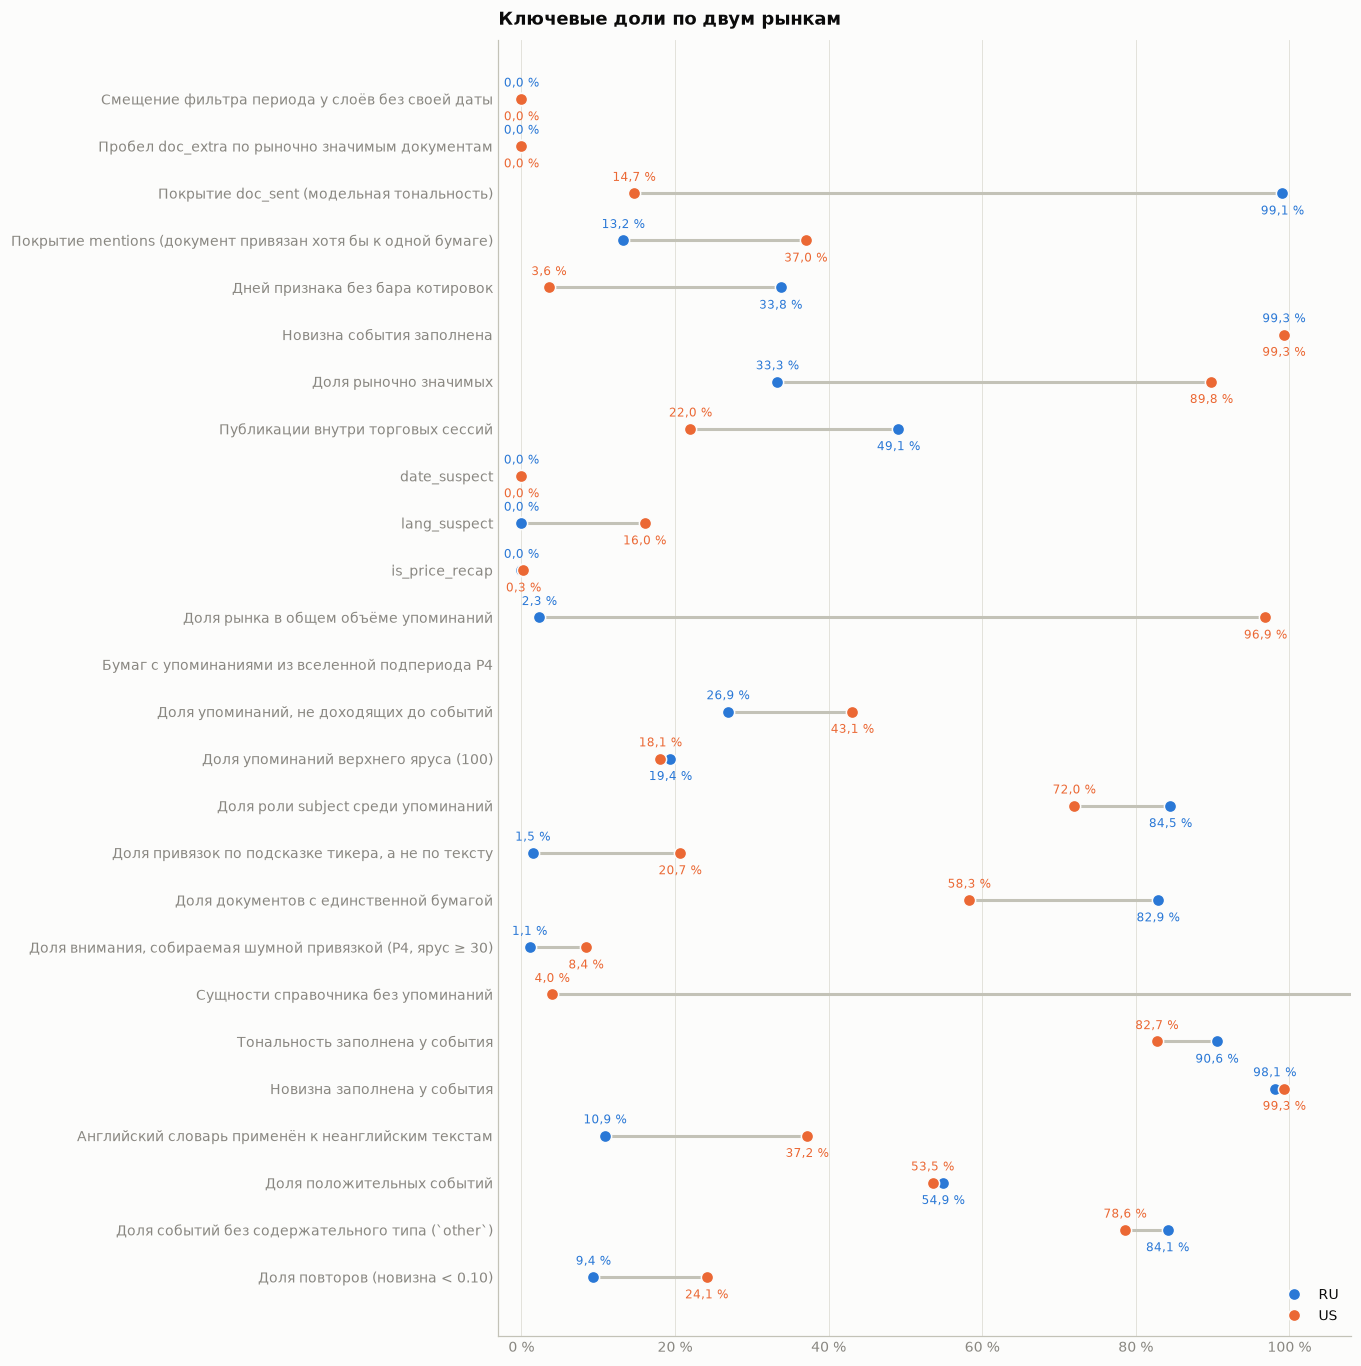

In [10]:
S.show_table("facts_ch01_04", title="Главы 01–04: измеренные факты",
             columns={"fact": "что меряли", "method": "способ", "ru": "RU", "us": "US"},
             formats={"ru": lambda v: fmt(v, 3) if abs(v) < 10 else fmt_int(v), "us": lambda v: fmt(v, 3) if abs(v) < 10 else fmt_int(v)})

@S.show("facts_ch01_04", title="Доли: RU против US")
def _(f):
    d = f[(f.unit == "share") & (f.key == True)].copy()
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(d) + 1))
    y = np.arange(len(d))[::-1]
    ax.hlines(y, d.ru, d.us, color=COLORS["axis"], lw=2, zorder=1)
    ax.plot(d.ru, y, "o", color=COLORS["RU"], ms=8, label="RU", zorder=3, markeredgecolor=COLORS["surface"])
    ax.plot(d.us, y, "o", color=COLORS["US"], ms=8, label="US", zorder=3, markeredgecolor=COLORS["surface"])
    for yi, a, b in zip(y, d.ru, d.us):
        ax.annotate(pct(a, 1), (a, yi), xytext=(0, 8 if a <= b else -14), textcoords="offset points", ha="center", fontsize=8, color=COLORS["RU"])
        ax.annotate(pct(b, 1), (b, yi), xytext=(0, 8 if b < a else -14), textcoords="offset points", ha="center", fontsize=8, color=COLORS["US"])
    ax.set_yticks(y); ax.set_yticklabels(d.fact); ax.set_xlim(-0.03, 1.08); ru_axis(ax, "x", 0, pct_axis=True)
    ax.grid(axis="x"); ax.grid(False, axis="y"); ax.legend(loc="lower right"); ax.set_title("Ключевые доли по двум рынкам")
    return fig

#### Корпус как текст: закон Ципфа и закон Хипса

Наклон Ципфа у русского корпуса (−0,93) положе английского (−1,21): морфология размазывает частоты
по словоформам. Показатель Хипса β (рост словаря с объёмом) у русского выше по той же причине.

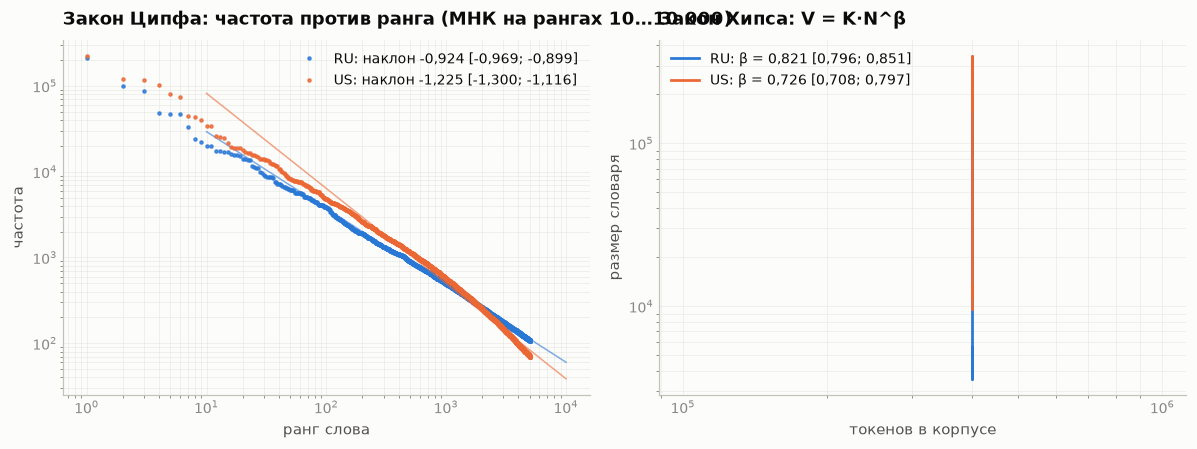

In [11]:
@S.show("zipf", "heaps", title="Ципф и Хипс")
def _(z, h):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    ax = axes[0]
    for mk in ["RU", "US"]:
        d = z[z.market == mk].sort_values("rank")
        ax.loglog(d["rank"], d["freq"], ".", ms=4, color=market_color(mk), alpha=0.8,
                  label=f"{mk}: наклон {fmt(d.slope.iloc[0], 3)} [{fmt(d.slope_lo.iloc[0], 3)}; {fmt(d.slope_hi.iloc[0], 3)}]")
        sel = d[(d["rank"] >= 10) & (d["rank"] <= 10_000)]
        if len(sel) > 2:
            b, a = np.polyfit(np.log(sel["rank"]), np.log(sel["freq"]), 1)
            xx = np.array([10, 10_000]); ax.loglog(xx, np.exp(a) * xx ** b, color=market_color(mk), lw=1, alpha=0.6)
    ax.set_xlabel("ранг слова"); ax.set_ylabel("частота"); ax.set_title("Закон Ципфа: частота против ранга (МНК на рангах 10…10 000)"); ax.legend(); ax.grid(True, which="both", axis="both", alpha=0.5)
    ax = axes[1]
    for mk in ["RU", "US"]:
        d = h[h.market == mk].sort_values("tokens")
        ax.loglog(d.tokens, d.vocab, "-", color=market_color(mk), label=f"{mk}: β = {fmt(d.beta.iloc[0], 3)} [{fmt(d.beta_lo.iloc[0], 3)}; {fmt(d.beta_hi.iloc[0], 3)}]")
    ax.set_xlabel("токенов в корпусе"); ax.set_ylabel("размер словаря"); ax.set_title("Закон Хипса: V = K·N^β"); ax.legend(); ax.grid(True, which="both", alpha=0.5)
    fig.tight_layout()
    return fig

@S.show("doc_length", title="Длина документов")
def _(dl):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, field, ttl in zip(axes, ["title", "text"], ["заголовок", "текст"]):
        for mk in ["RU", "US"]:
            d = dl[(dl.market == mk) & (dl.field == field)].sort_values("bin_lo")
            w = d.bin_hi - d.bin_lo
            dens = d.docs / d.docs.sum() / w
            ax.step(d.bin_lo, dens, where="post", color=market_color(mk), label=mk)
        ax.set_xscale("log"); ax.set_title(f"Длина: {ttl}, токенов (плотность, лог. ось)"); ax.set_xlabel("токенов"); ax.legend()
        ax.set_yticks([])
    fig.tight_layout()
    return fig

#### Тональность: модель против словаря

Тональность в проекте — две независимые шкалы: **модель** (RU — `rubert-tiny2-fin`, US — FinBERT в
`doc_sent_v2`) и **словарь** (RuSentiLex / Loughran–McDonald). Они хранятся и используются раздельно
(`sentiment_select`), потому что согласие между ними неполное — это видно на матрице справа.

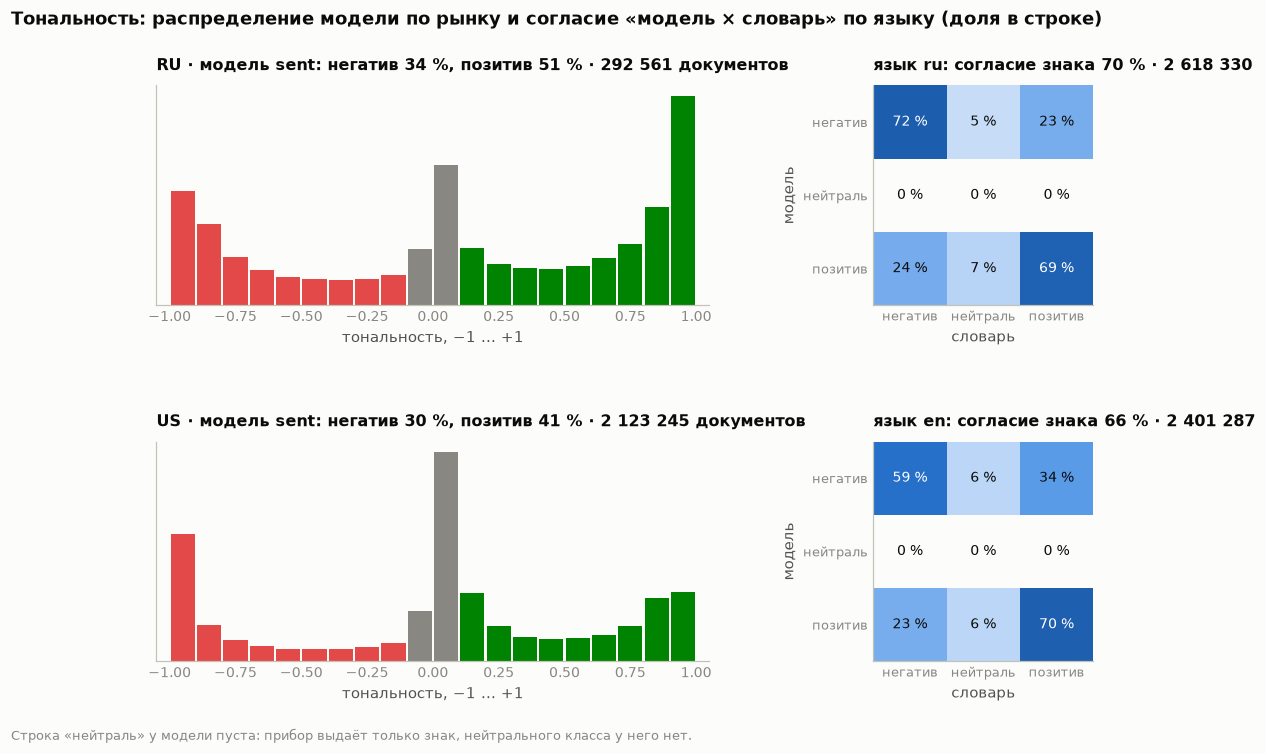

In [12]:
@S.show("sentiment_dist", "sentiment_agreement", title="Тональность: распределения и согласие приборов")
def _(sd, sa):
    # Словарного балла в озере нет, поэтому слева - распределение модели по
    # рынку, справа - матрица согласия «модель x словарь» по языку документа
    # (ru для российского рынка, en для американского).
    LANG = {"RU": "ru", "US": "en"}
    fig = plt.figure(figsize=(11.5, 6.8))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.8, 1.0], hspace=0.62, wspace=0.28)
    for i, mk in enumerate(["RU", "US"]):
        ax = fig.add_subplot(gs[i, 0])
        d = sd[sd.market == mk].sort_values("bin_lo")
        if len(d) == 0:
            ax.set_axis_off(); ax.set_title(f"{mk}: нет данных", fontsize=10.5)
        else:
            centers = (d.bin_lo + d.bin_hi) / 2
            cols = [COLORS["neg"] if c < -0.1 else (COLORS["pos"] if c > 0.1 else COLORS["neu"]) for c in centers]
            share = d.docs / d.docs.sum()
            ax.bar(centers, share, width=(d.bin_hi - d.bin_lo) * 0.92, color=cols)
            neg = float(share[centers < -0.1].sum()); pos = float(share[centers > 0.1].sum())
            ax.set_title(f"{mk} · модель {d.model_name.iloc[0]}: негатив {pct(neg, 0)}, позитив {pct(pos, 0)} · {fmt_int(d.docs.sum())} документов", fontsize=10.5)
            ax.set_xlim(-1.05, 1.05); ax.set_yticks([]); ax.set_xlabel("тональность, −1 … +1")
        ax = fig.add_subplot(gs[i, 1])
        lg = LANG[mk]
        m = sa[sa.lang == lg].pivot_table(index="model_sign", columns="dict_sign", values="docs", aggfunc="sum").reindex(index=["neg", "neu", "pos"], columns=["neg", "neu", "pos"]).fillna(0)
        total = float(m.values.sum())
        if total <= 0:
            ax.set_axis_off(); ax.set_title(f"{lg}: нет данных", fontsize=10.5); continue
        rowsum = m.sum(axis=1).replace(0, np.nan)
        rowshare = (m.T / rowsum).T.fillna(0)
        ax.imshow(rowshare.values, cmap=mpl.colors.LinearSegmentedColormap.from_list("b", [COLORS["surface"]] + SEQ_BLUE[2:]), vmin=0, vmax=1)
        for r in range(3):
            for c in range(3):
                v = float(rowshare.values[r, c])
                ax.text(c, r, pct(v, 0), ha="center", va="center", fontsize=9, color="#ffffff" if v > 0.5 else COLORS["ink"])
        lab = ["негатив", "нейтраль", "позитив"]
        ax.set_xticks(range(3)); ax.set_xticklabels(lab, fontsize=8.5); ax.set_yticks(range(3)); ax.set_yticklabels(lab, fontsize=8.5)
        ax.set_xlabel("словарь"); ax.set_ylabel("модель"); ax.grid(False)
        agree = float(np.trace(m.values)) / total
        ax.set_title(f"язык {lg}: согласие знака {pct(agree, 0)} · {fmt_int(total)}", fontsize=10.5)
    if float(sa[sa.model_sign == "neu"].docs.sum()) == 0:
        fig.text(0.01, 0.005, "Строка «нейтраль» у модели пуста: прибор выдаёт только знак, нейтрального класса у него нет.", fontsize=8.5, color="#898781")
    fig.suptitle("Тональность: распределение модели по рынку и согласие «модель × словарь» по языку (доля в строке)", x=0.01, ha="left", fontsize=12, fontweight="semibold")
    return fig

#### Типы событий и концентрация упоминаний

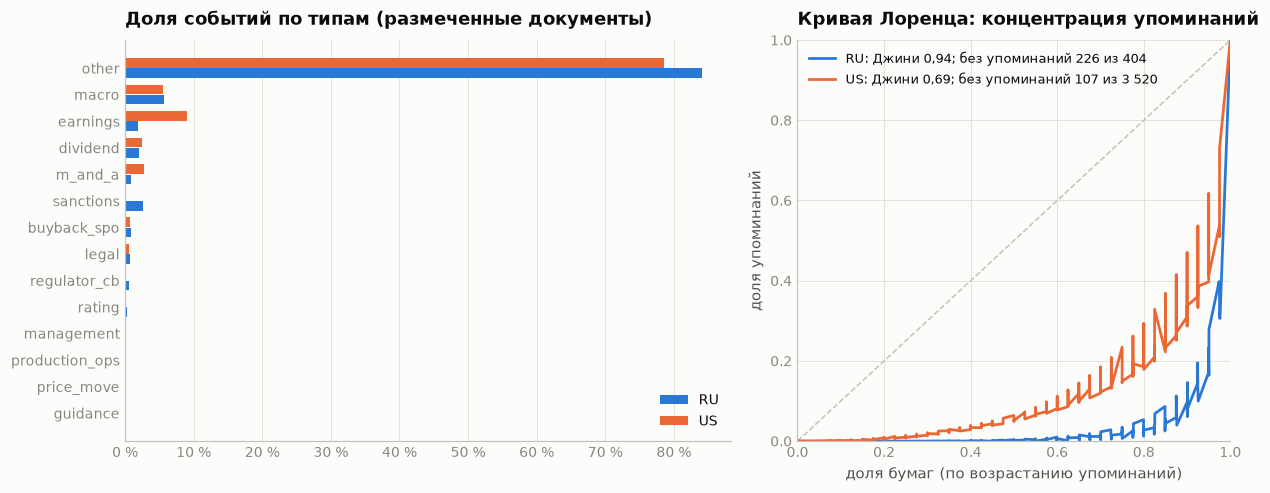

In [13]:
@S.show("event_types", "mentions_lorenz", title="Типы событий и концентрация упоминаний по бумагам")
def _(et, lz):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
    ax = axes[0]
    types = et.groupby("type")["share"].sum().sort_values(ascending=True).index
    y = np.arange(len(types))
    for i, mk in enumerate(["RU", "US"]):
        d = et[et.market == mk].set_index("type").reindex(types)
        ax.barh(y + (i - 0.5) * 0.38, d["share"].fillna(0), height=0.36, color=market_color(mk), label=mk)
    ax.set_yticks(y); ax.set_yticklabels(types); ru_axis(ax, "x", 0, pct_axis=True); ax.grid(axis="x"); ax.grid(False, axis="y")
    ax.set_title("Доля событий по типам (размеченные документы)"); ax.legend(loc="lower right")
    ax = axes[1]
    ax.plot([0, 1], [0, 1], color=COLORS["axis"], lw=1, ls="--")
    for mk in ["RU", "US"]:
        d = lz[lz.market == mk].sort_values("tickers_cum_share")
        g = d.gini.iloc[0]; silent = int(d.silent_tickers.iloc[0]); tot = int(d.tickers_total.iloc[0])
        ax.plot(d.tickers_cum_share, d.mentions_cum_share, color=market_color(mk), label=f"{mk}: Джини {fmt(g, 2)}; без упоминаний {fmt_int(silent)} из {fmt_int(tot)}")
    ax.set_xlabel("доля бумаг (по возрастанию упоминаний)"); ax.set_ylabel("доля упоминаний"); ax.set_title("Кривая Лоренца: концентрация упоминаний")
    ax.legend(loc="upper left", fontsize=8.5); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(True, axis="both")
    fig.tight_layout()
    return fig

### 2.2 Хвосты распределений

Вселенная — 50 бумаг с наибольшим оборотом среди членов индекса (IMOEX / SPX). Хвосты тяжёлые
везде, нормальность отвергнута почти всюду; индекс Хилла 2,0–3,3 означает, что **четвёртого момента
не существует**. Эксцесс чувствителен к одному наблюдению: у IMOEX 208 падает до 25 после
удаления единственного дня 24.02.2022. Число, исчезающее вместе с одним днём, нельзя подавать как
свойство распределения, не показав рядом вариант без него.

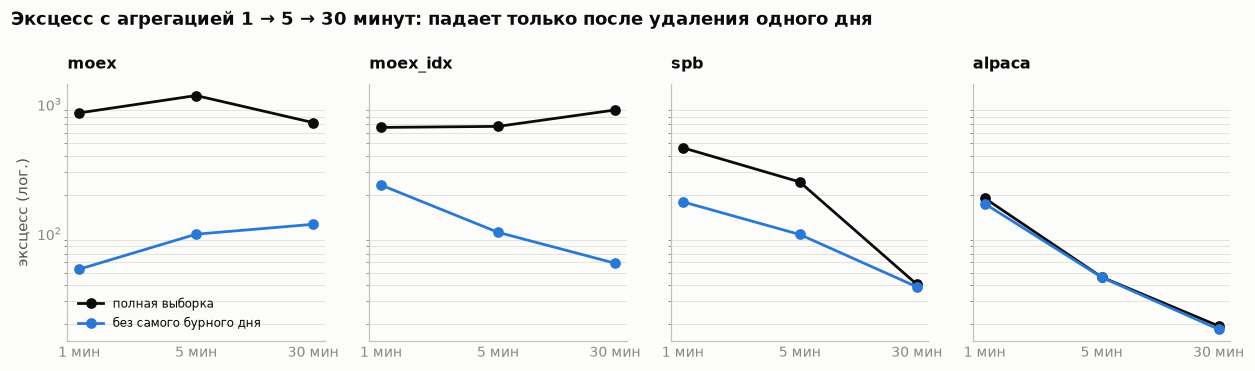

In [14]:
@S.show("tails", "kurtosis_sensitivity", title="Хвосты: индекс Хилла и эксцесс")
def _(t, ks):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
    ax = axes[0]
    y = np.arange(len(t))[::-1]
    ci_dots(ax, y + 0.17, t.hill_r, t.hill_r_lo, t.hill_r_hi, COLORS["RU"], label="правый хвост (рост)")
    ci_dots(ax, y - 0.17, t.hill_l, t.hill_l_lo, t.hill_l_hi, COLORS["US"], label="левый хвост (падение)", marker="s")
    ax.axvspan(2, 4, color=COLORS["band"], alpha=0.5, lw=0); ax.axvline(4, color=COLORS["axis"], lw=0.8)
    ax.text(4.03, y.max() + 0.5, "α < 4: 4-го момента нет", fontsize=8.5, color=COLORS["ink2"], va="top")
    ax.set_yticks(y); ax.set_yticklabels([f"{s} · {w}" for s, w in zip(t.series, t.window)], fontsize=8.5)
    ax.set_xlabel("индекс хвоста Хилла α"); ax.set_title("Индекс Хилла по рядам, 95 % ДИ"); ax.legend(loc="lower right"); ax.grid(axis="x"); ax.grid(False, axis="y")
    ax = axes[1]
    ax.barh(y, t["kurt"], color=[market_color(m) for m in t.market], height=0.6)
    ax.errorbar(t["kurt"], y, xerr=[t["kurt"] - t.kurt_lo, t.kurt_hi - t["kurt"]], fmt="none", ecolor=COLORS["ink2"], elinewidth=1, capsize=2)
    ax.set_yticks(y); ax.set_yticklabels([]); ax.set_xscale("log"); ax.set_xlabel("избыточный эксцесс (лог. шкала)")
    ax.set_title("Эксцесс дневных доходностей"); ax.grid(axis="x", which="both"); ax.grid(False, axis="y")
    i = t.index[t.series.str.contains("IMOEX")].tolist()
    if i and ks:
        yy = y[i[0]]
        ax.annotate(f"без {ks['worst_day']}: {fmt(ks['without_worst_day'], 0)}", (ks["without_worst_day"], yy), xytext=(0, -14), textcoords="offset points",
                    fontsize=8.5, color=COLORS["neg"], ha="center", arrowprops=dict(arrowstyle="-", color=COLORS["neg"], lw=0.8))
        ax.plot([ks["without_worst_day"]], [yy], "|", color=COLORS["neg"], ms=14, mew=2)
    fig.tight_layout()
    return fig

@S.show("aggregation_gaussianity", title="Агрегационная гауссовость на минутках")
def _(ag):
    venues = list(ag.venue.unique())
    fig, axes = plt.subplots(1, len(venues), figsize=(11.5, 3.4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, v in zip(axes, venues):
        d = ag[ag.venue == v].set_index("horizon").reindex(["1m", "5m", "30m"])
        ax.plot(range(3), d.kurt_full, "-o", color=COLORS["ink"], label="полная выборка")
        ax.plot(range(3), d.kurt_wo_worst, "-o", color=COLORS["RU"], label="без самого бурного дня")
        ax.set_xticks(range(3)); ax.set_xticklabels(["1 мин", "5 мин", "30 мин"]); ax.set_yscale("log"); ax.set_title(v, fontsize=10.5)
        ax.grid(axis="y", which="both")
    axes[0].set_ylabel("эксцесс (лог.)"); axes[0].legend(fontsize=8)
    fig.suptitle("Эксцесс с агрегацией 1 → 5 → 30 минут: падает только после удаления одного дня", x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.tight_layout()
    return fig

### 2.3 Автокорреляция, кластеризация волатильности, долгая память, рычаг

Контроль, без которого вся «долгая память» была бы артефактом: тот же показатель Хёрста считается на
самих доходностях и обязан остаться около 0,5 — он и остался (0,43–0,52). Итог: линейной
автокорреляции доходностей нет, кластеризация волатильности есть (АКФ модулей 0,23–0,38 на первом
сдвиге, держится до сдвига 40), долгая память есть (Хёрст 0,81–0,95), рычаг отрицателен.

**Единственное место главы, где стилизованный факт не подтверждается** — минутные данные: АКФ
первого порядка велика, и её знак определяется **ликвидностью, а не страной** (bid-ask bounce).

/tmp/ipykernel_23305/2226533110.py:19: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


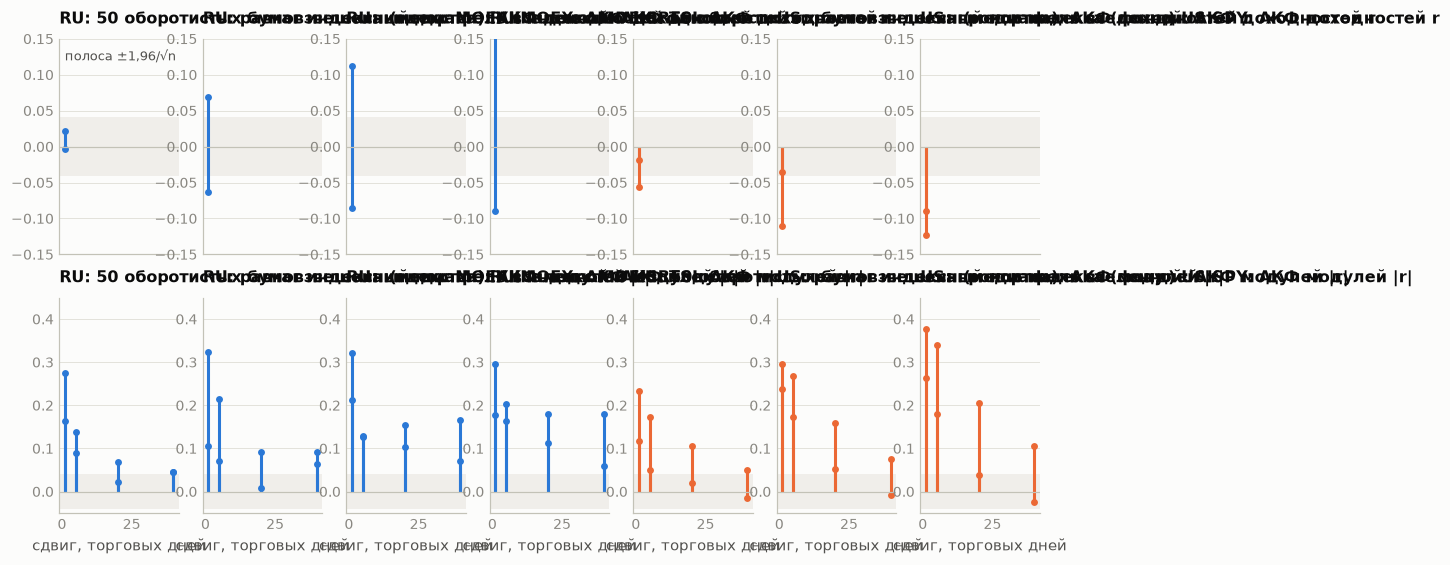

ряд,"АКФ(r,1)","АКФ(|r|,1)",Хёрст |r|,контроль на r,GPH d,рычаг k=1
RU: 50 оборотистых бумаг индекса (медиана),"-0,003",—,—,"0,494",—,—
RU: равновзвешенный портфель вселенной,"-0,064",—,—,"0,514",—,—
RU: 50 оборотистых бумаг индекса (медиана),"0,022",—,—,"0,480",—,—
RU: равновзвешенный портфель вселенной,"0,069",—,—,"0,495",—,—
RU: индекс MOEX:IMOEX,"-0,086",—,—,"0,518",—,—
RU: индекс MOEX:IMOEX,"0,112",—,—,"0,446",—,—
RU: индекс MOEX:RTSI,"-0,089",—,—,"0,466",—,—
RU: индекс MOEX:RTSI,"0,182",—,—,"0,454",—,—
US: 50 оборотистых бумаг индекса (медиана),"-0,057",—,—,"0,466",—,—
US: равновзвешенный портфель вселенной,"-0,110",—,—,"0,461",—,—


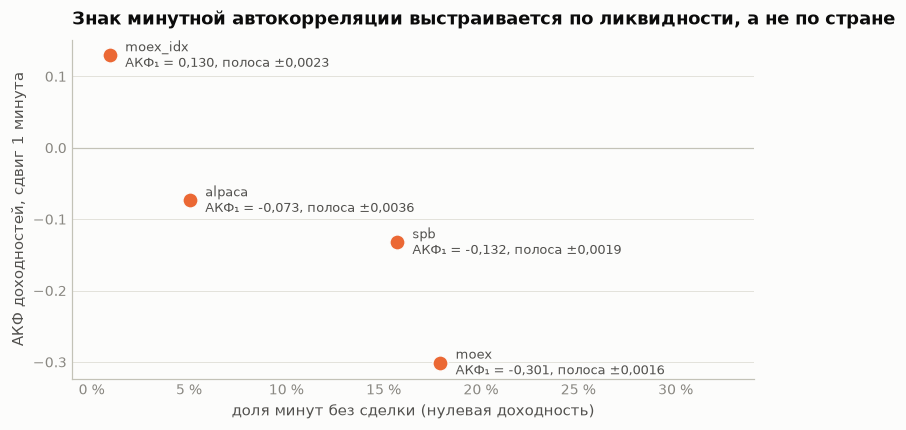

In [15]:
@S.show("acf", title="АКФ доходностей и их модулей")
def _(acf):
    series = list(acf.series.unique())
    fig, axes = plt.subplots(2, len(series), figsize=(11.5, 5.6), sharex=True)
    axes = np.array(axes).reshape(2, -1)
    for j, s in enumerate(series):
        d = acf[acf.series == s].sort_values("lag")
        c = market_color(d.market.iloc[0]); band = d.band.iloc[0]
        for i, (col, ttl) in enumerate([("acf_r", "АКФ доходностей r"), ("acf_absr", "АКФ модулей |r|")]):
            ax = axes[i, j]
            ax.axhspan(-band, band, color=COLORS["band"], alpha=0.7, lw=0)
            ax.vlines(d.lag, 0, d[col], color=c, lw=2)
            ax.plot(d.lag, d[col], "o", color=c, ms=3.5)
            ax.axhline(0, color=COLORS["axis"], lw=0.8)
            ax.set_title(f"{s}: {ttl}", fontsize=10.5)
            if i == 1: ax.set_xlabel("сдвиг, торговых дней")
        axes[0, j].set_ylim(-0.15, 0.15); axes[1, j].set_ylim(-0.05, max(0.45, d.acf_absr.max() * 1.15))
    axes[0, 0].text(1, 0.12, "полоса ±1,96/√n", fontsize=8.5, color=COLORS["ink2"])
    fig.tight_layout()
    return fig

S.show_table("longmemory", title="Долгая память и рычаг (2015–2023)",
             columns={"series": "ряд", "acf_r1": "АКФ(r,1)", "acf_absr1": "АКФ(|r|,1)", "hurst_absr": "Хёрст |r|",
                      "hurst_r_control": "контроль на r", "gph_d": "GPH d", "leverage_k1": "рычаг k=1"})

@S.show("minute_acf", title="Минутная автокорреляция и ликвидность")
def _(ma):
    fig, ax = plt.subplots(figsize=(8, 4))
    for _, r in ma.iterrows():
        c = COLORS["RU"] if r.venue.startswith("RU") else COLORS["US"]
        ax.plot(r.zero_share, r.acf1, "o", ms=10, color=c, markeredgecolor=COLORS["surface"])
        ax.annotate(f"{r.venue}\nАКФ₁ = {fmt(r.acf1, 3)}, полоса ±{fmt(r.band, 4)}", (r.zero_share, r.acf1), xytext=(10, 0), textcoords="offset points", fontsize=8.5, va="center", color=COLORS["ink2"])
    ax.axhline(0, color=COLORS["axis"], lw=0.8); ru_axis(ax, "x", 0, pct_axis=True)
    ax.set_xlabel("доля минут без сделки (нулевая доходность)"); ax.set_ylabel("АКФ доходностей, сдвиг 1 минута")
    ax.set_title("Знак минутной автокорреляции выстраивается по ликвидности, а не по стране"); ax.set_xlim(-0.01, ma.zero_share.max() * 1.9)
    return fig

### 2.4 Объём против волатильности; асимметрия прибыли и убытка

Грейнджер отчитывается **долей бумаг**, у которых направление отвергается при уровне 1 %, с
интервалом Уилсона — а не одним p-значением. Направление связи **противоположно на двух рынках**
и сохраняется во всех 12 спецификациях на рынок (окно нормировки, мера волатильности, число сдвигов).
Асимметрия по Cont (2001): сколько дней нужно, чтобы впервые набрать прибыль заданного размера, и
сколько — такой же убыток; она появляется только на крупных уровнях.

In [16]:
@S.show("volume_vol", "gainloss_asym", title="Объём ↔ волатильность и асимметрия прибыль/убыток")
def _(vv, ga):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    ax = axes[0]
    y = np.arange(len(vv))[::-1]
    ci_dots(ax, y + 0.17, vv.g_vol2vola, vv.g_vol2vola_lo, vv.g_vol2vola_hi, COLORS["RU"], label="объём → волатильность")
    ci_dots(ax, y - 0.17, vv.g_vola2vol, vv.g_vola2vol_lo, vv.g_vola2vol_hi, COLORS["US"], label="волатильность → объём", marker="s")
    ax.axvline(0.05, color=COLORS["axis"], lw=0.8, ls="--"); ax.text(0.055, y.min() - 0.45, "5 % — уровень ложных срабатываний", fontsize=8, color=COLORS["ink2"])
    ax.set_yticks(y); ax.set_yticklabels([f"{s}\ncorr(|r|, объём) {fmt(c, 2)}" for s, c in zip(vv.series, vv["corr"])], fontsize=9)
    ru_axis(ax, "x", 0, pct_axis=True); ax.set_xlim(-0.02, 1.02); ax.grid(axis="x"); ax.grid(False, axis="y")
    ax.set_title("Доля бумаг с причинностью по Грейнджеру (1 %), Уилсон"); ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=2)
    ax = axes[1]
    lv = ["±5 %", "±10 %", "±20 %"]
    for i, (_, r) in enumerate(ga.iterrows()):
        c = COLORS["RU"] if r.series.startswith("RU") else COLORS["US"]
        ls = "-" if ("портфель" in r.series) else "--"
        ax.plot(range(3), [r.ratio_5, r.ratio_10, r.ratio_20], ls, marker="o", color=c, label=r.series)
    ax.axhline(1, color=COLORS["axis"], lw=0.8); ax.set_xticks(range(3)); ax.set_xticklabels(lv)
    ax.set_ylabel("дней до прибыли / дней до убытка"); ax.set_title("Асимметрия Cont: убытки приходят быстрее только на крупных уровнях"); ax.legend(fontsize=8.5)
    fig.tight_layout()
    return fig

### 2.5 Внутридневная сезонность

Профиль: значение минуты делится на среднее по минутам **того же дня у той же бумаги**; множитель 1
читается как «как в среднюю минуту этого дня». Свод по бумагам — медианой, по дням — средним,
интервал — бутстрэпом по дням. Зона биржи задаётся явно: без перевода из MSK профиль США съехал бы на
7–8 часов, по-разному летом и зимой. Границы сессий **измерены, а не взяты из регламента**: у MOEX
основная сессия кончается на 18:39, аукцион закрытия 18:45–18:49, вечерняя начинается в 19:04.

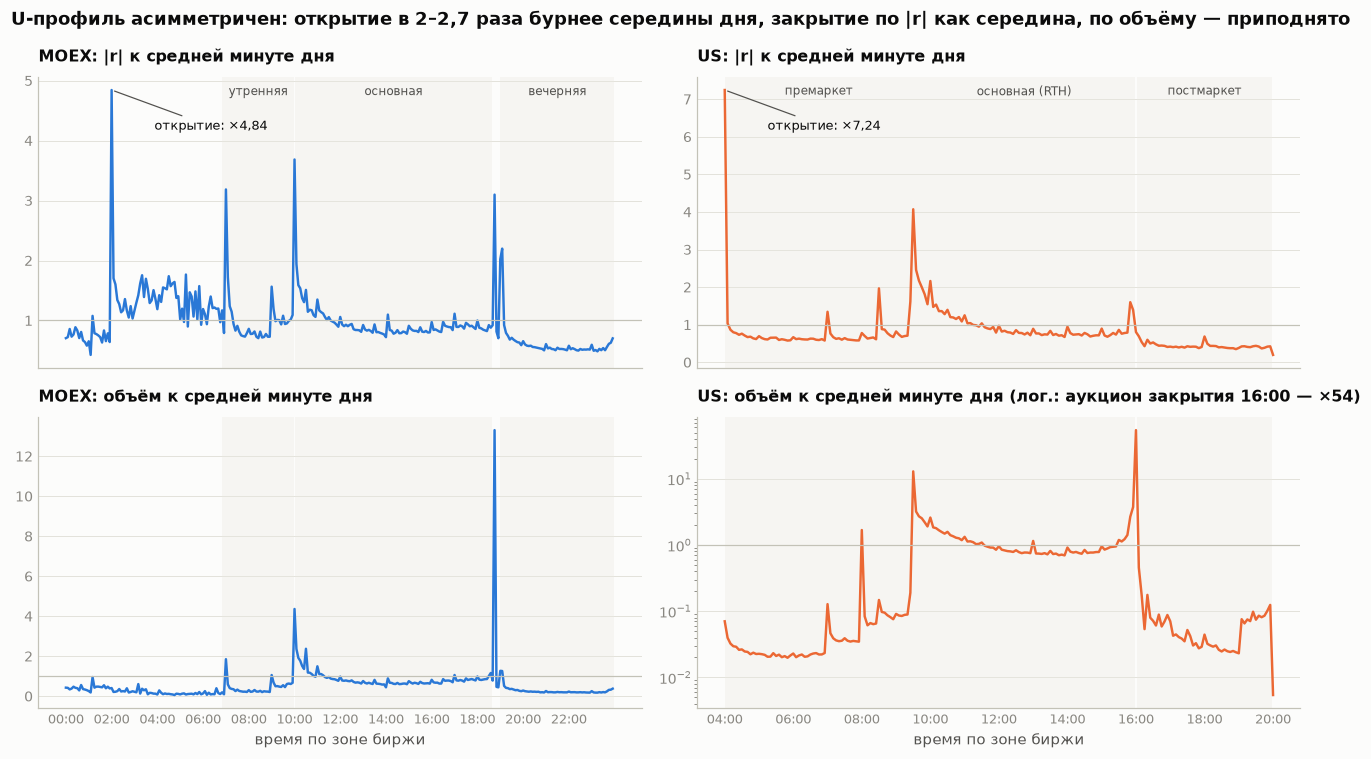

площадка,величина,сессия,с,по,множитель,ДИ ниж.,ДИ верх.
MOEX,|r|,утренняя,06:50,09:59,"0,984","0,961","1,007"
MOEX,|r|,основная,10:00,18:39,"0,901","0,895","0,906"
MOEX,|r|,аукцион закрытия,18:40,18:59,"0,770","0,752","0,790"
MOEX,|r|,вечерняя,19:00,23:59,"0,580","0,570","0,591"
MOEX,объём,утренняя,06:50,09:59,"0,479","0,452","0,509"
MOEX,объём,основная,10:00,18:39,"0,806","0,796","0,815"
MOEX,объём,аукцион закрытия,18:40,18:59,"2,382","2,229","2,543"
MOEX,объём,вечерняя,19:00,23:59,"0,249","0,238","0,261"
US,|r|,премаркет,04:00,09:29,"0,692","0,682","0,701"
US,|r|,основная (RTH),09:30,15:59,"0,953","0,945","0,961"


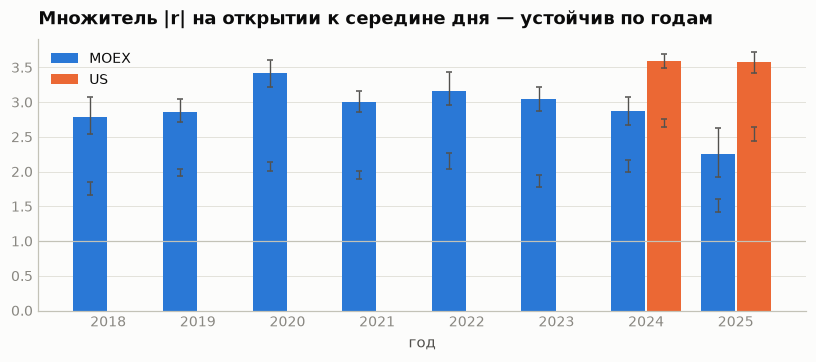

In [17]:
@S.show("intraday_profile", "intraday_sessions", title="Внутридневной профиль |r| и объёма")
def _(ip, ses):
    def to_min(s):
        h, m = s.split(":"); return int(h) * 60 + int(m)
    ip["t"] = ip.time.map(to_min)
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="col")
    for j, venue in enumerate(["MOEX", "US"]):
        d = ip[ip.venue == venue].sort_values("t"); c = COLORS["RU"] if venue == "MOEX" else COLORS["US"]
        for i, (col, lo, hi, ttl) in enumerate([("absr_mult", "absr_lo", "absr_hi", "|r| к средней минуте дня"), ("vol_mult", "vol_lo", "vol_hi", "объём к средней минуте дня")]):
            ax = axes[i, j]
            ax.fill_between(d.t, d[lo], d[hi], color=c, alpha=0.18, lw=0)
            ax.plot(d.t, d[col], color=c, lw=1.6)
            ax.axhline(1, color=COLORS["axis"], lw=0.8)
            ss = ses[(ses.venue == venue)]
            for _, r in ss.drop_duplicates("session").iterrows():
                a, b = to_min(r.t_from), to_min(r.t_to)
                if b - a > 30:
                    ax.axvspan(a, b, color=COLORS["band"], alpha=0.35, lw=0)
                    if i == 0: ax.text((a + b) / 2, ax.get_ylim()[1] * 0.97 if ax.get_ylim()[1] > 2 else 2.9, r.session, ha="center", va="top", fontsize=8, color=COLORS["ink2"])
            if i == 1 and venue == "US":
                ax.set_yscale("log"); ax.set_title(f"{venue}: {ttl} (лог.: аукцион закрытия 16:00 — ×{fmt(d.vol_mult.max(), 0)})", fontsize=10.5)
            else:
                ax.set_title(f"{venue}: {ttl}", fontsize=10.5)
            ticks = np.arange((d.t.min() // 60) * 60, d.t.max() + 1, 120)
            ax.set_xticks(ticks); ax.set_xticklabels([f"{int(t)//60:02d}:00" for t in ticks], fontsize=8.5)
            if i == 0:
                o = d.iloc[(d.absr_mult.idxmax() - d.index[0])]
                ax.annotate(f"открытие: ×{fmt(o.absr_mult, 2)}", (o.t, o.absr_mult), xytext=(28, -26), textcoords="offset points", fontsize=8.5, color=COLORS["ink"], arrowprops=dict(arrowstyle="-", color=COLORS["ink2"], lw=0.8))
        axes[1, j].set_xlabel("время по зоне биржи")
    fig.suptitle("U-профиль асимметричен: открытие в 2–2,7 раза бурнее середины дня, закрытие по |r| как середина, по объёму — приподнято", x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.tight_layout()
    return fig

S.show_table("intraday_sessions", title="Множители по сессиям (к средней минуте дня)",
             columns={"venue": "площадка", "measure": "величина", "session": "сессия", "t_from": "с", "t_to": "по", "mult": "множитель", "lo": "ДИ ниж.", "hi": "ДИ верх."})

@S.show("open_mult_by_year", title="Множитель открытия по годам")
def _(om):
    fig, ax = plt.subplots(figsize=(9, 3.2))
    for venue, off in (("MOEX", -0.2), ("US", 0.2)):
        d = om[om.venue == venue]
        ax.bar(d.year + off, d.mult, width=0.38, color=COLORS["RU"] if venue == "MOEX" else COLORS["US"], label=venue)
        ax.errorbar(d.year + off, d.mult, yerr=[d.mult - d.lo, d.hi - d.mult], fmt="none", ecolor=COLORS["ink2"], elinewidth=0.9, capsize=2)
    ax.axhline(1, color=COLORS["axis"], lw=0.8); ax.set_title("Множитель |r| на открытии к середине дня — устойчив по годам"); ax.legend(); ax.set_xlabel("год")
    ax.set_xticks(sorted(om.year.unique()))
    return fig

### 2.6 Календарные эффекты

Эффект — безразмерный множитель **внутри своей недели** (день недели) или **внутри своего месяца**
(конец месяца): иначе «вторник выше пятницы» померило бы состав выборки по годам. Интервал —
бутстрэпом по неделям и месяцам. Номер дня с конца месяца считается по панели, не по календарю.
На ex-date меряется остаток `r + div/P(−1)`: ноль значит «цена упала ровно на дивиденд»; цена берётся
**сырая** — в скорректированном ряду цена на ex-date не падает, а растёт.

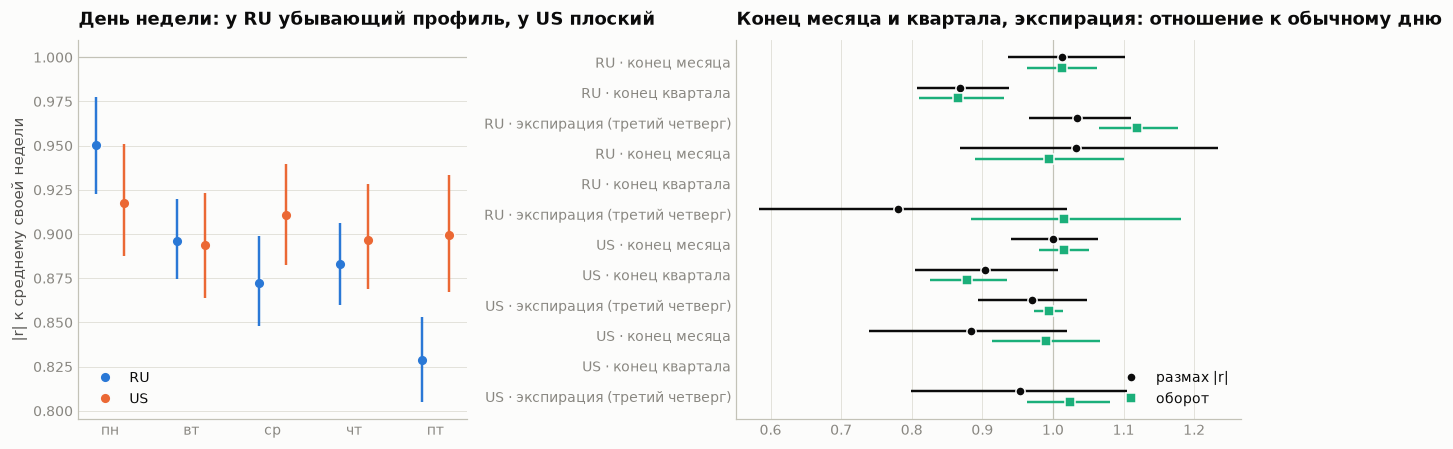

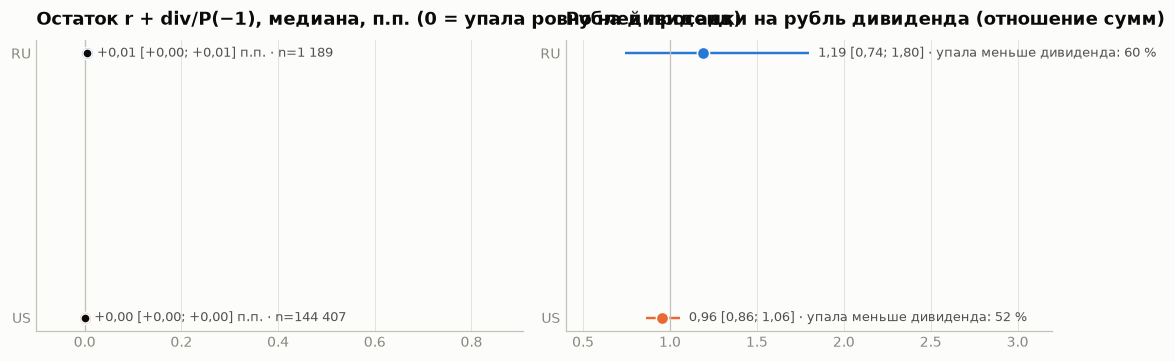

In [18]:
@S.show("weekday", "calendar_effects", title="День недели и календарные эффекты")
def _(wd, ce):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
    ax = axes[0]
    order = ["пн", "вт", "ср", "чт", "пт"]
    for mk, off in (("RU", -0.17), ("US", 0.17)):
        d = wd[wd.market == mk].set_index("weekday").reindex(order)
        x = np.arange(5) + off
        ax.plot(x, d.mult, "o", color=market_color(mk), ms=7, label=mk, markeredgecolor=COLORS["surface"])
        ax.vlines(x, d.lo, d.hi, color=market_color(mk), lw=1.6)
    ax.axhline(1, color=COLORS["axis"], lw=0.8); ax.set_xticks(range(5)); ax.set_xticklabels(order)
    ax.set_ylabel("|r| к среднему своей недели"); ax.set_title("День недели: у RU убывающий профиль, у US плоский"); ax.legend()
    ax = axes[1]
    ce["label"] = ce.market + " · " + ce.effect
    y = np.arange(len(ce))[::-1]
    ci_dots(ax, y + 0.17, ce.absr_ratio, ce.absr_lo, ce.absr_hi, COLORS["ink"], label="размах |r|")
    ci_dots(ax, y - 0.17, ce.turn_ratio, ce.turn_lo, ce.turn_hi, COLORS["third"], label="оборот", marker="s")
    ax.axvline(1, color=COLORS["axis"], lw=0.8); ax.set_yticks(y); ax.set_yticklabels(ce.label, fontsize=9)
    ax.set_title("Конец месяца и квартала, экспирация: отношение к обычному дню"); ax.legend(loc="lower right"); ax.grid(axis="x"); ax.grid(False, axis="y")
    fig.tight_layout()
    return fig

@S.show("exdate", title="Ex-date: падает ли цена ровно на дивиденд")
def _(ex):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    y = np.arange(len(ex))[::-1]
    ax = axes[0]
    ci_dots(ax, y, ex.resid_med, ex.resid_lo, ex.resid_hi, [market_color(m) for m in ex.market][0] if len(ex) == 1 else COLORS["ink"])
    for yi, (_, r) in zip(y, ex.iterrows()):
        ax.plot([r.resid_med], [yi], "o", color=market_color(r.market), ms=8, markeredgecolor=COLORS["surface"])
        ax.annotate(f"{fmt_ci(r.resid_med, r.resid_lo, r.resid_hi, 2, plus=True)} п.п. · n={fmt_int(r.events)}", (r.resid_hi, yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=COLORS["ink2"])
    zero_line(ax); ax.set_yticks(y); ax.set_yticklabels(ex.market); ax.set_xlim(min(-0.1, ex.resid_lo.min() - 0.1), ex.resid_hi.max() + 0.9)
    ax.set_title("Остаток r + div/P(−1), медиана, п.п. (0 = упала ровно на дивиденд)"); ax.grid(axis="x"); ax.grid(False, axis="y")
    ax = axes[1]
    for yi, (_, r) in zip(y, ex.iterrows()):
        ax.hlines(yi, r.ratio_lo, r.ratio_hi, color=market_color(r.market), lw=1.6)
        ax.plot([r.ratio_sums], [yi], "o", color=market_color(r.market), ms=8, markeredgecolor=COLORS["surface"])
        ax.annotate(f"{fmt_ci(r.ratio_sums, r.ratio_lo, r.ratio_hi, 2)} · упала меньше дивиденда: {pct(r.share_less, 0)}", (r.ratio_hi, yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=COLORS["ink2"])
    ax.axvline(1, color=COLORS["axis"], lw=0.8); ax.set_yticks(y); ax.set_yticklabels(ex.market); ax.set_xlim(0.4, ex.ratio_hi.max() + 1.4)
    ax.set_title("Рублей просадки на рубль дивиденда (отношение сумм)"); ax.grid(axis="x"); ax.grid(False, axis="y")
    fig.tight_layout()
    return fig

<a id="3"></a>
## 3. Новости и рынок вместе: описание без гипотез

Величины нормированы: **размах** — |r| к стандартному отклонению той же бумаги за 20 предыдущих
дней; **оборот** — к своей медиане за те же 20 дней. Каждая разница «день с событием минус день без»
считается четырьмя способами одной машинкой:

| вариант | что сравнивается |
|---|---|
| C0 | день с событием против среднего по всем безновостным дням подпериода — сырая разница |
| C1 | дни **одной бумаги внутри одного месяца** |
| C2 | то же плюс день недели |
| плацебо | C1 на панели, где метка «день с событиями» переставлена **внутри каждой бумаги** |

Единица ресемплинга — дата, не пара.

### 3.1 Контроль меняет даже знак

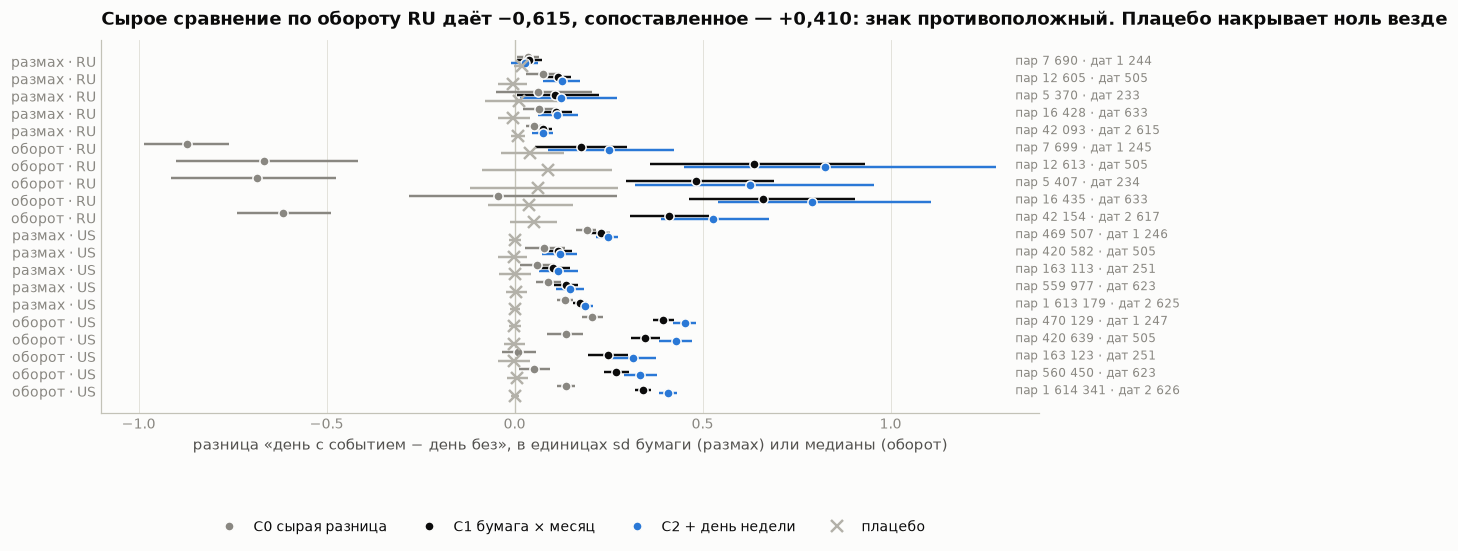

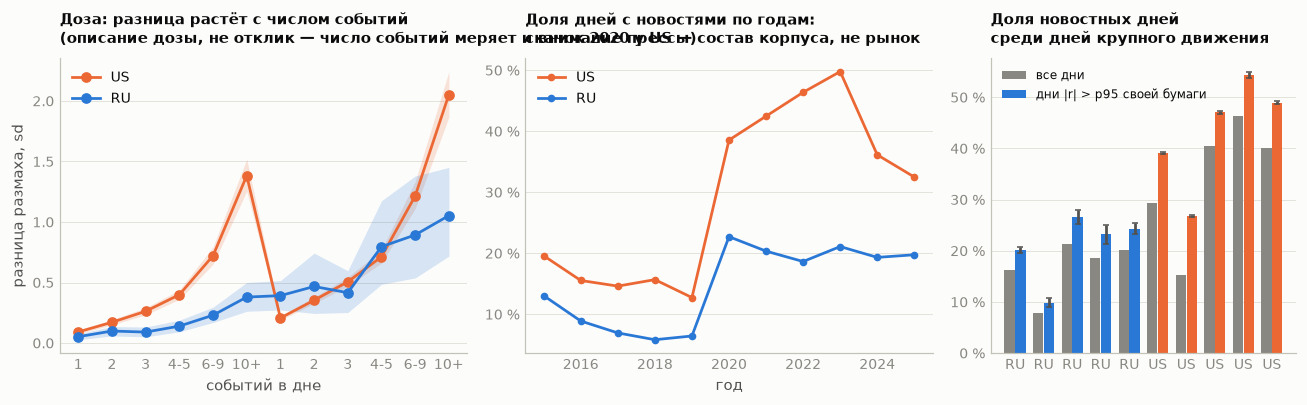

In [19]:
@S.show("ch06_contrast", title="Четыре варианта сравнения")
def _(cc):
    cc["label"] = cc.measure + " · " + cc.market
    fig, ax = plt.subplots(figsize=(11, 4.4))
    y = np.arange(len(cc))[::-1]
    specs = [("c0", "C0 сырая разница", COLORS["muted"], "o"), ("c1", "C1 бумага × месяц", COLORS["ink"], "o"),
             ("c2", "C2 + день недели", COLORS["RU"], "o"), ("pl", "плацебо", COLORS["placebo"], "x")]
    offs = [0.27, 0.09, -0.09, -0.27]
    for (col, lab, c, mk), off in zip(specs, offs):
        m = cc[col].notna()
        ci_dots(ax, y[m] + off, cc[col][m], cc[col + "_lo"][m], cc[col + "_hi"][m], c, label=lab, marker=mk, ms=7 if mk == "x" else 6)
    zero_line(ax)
    for yi, (_, r) in zip(y, cc.iterrows()):
        ax.text(ax.get_xlim()[1] if False else cc[["c0_hi", "c1_hi", "c2_hi"]].max().max() + 0.05, yi, f"пар {fmt_int(r.pairs)} · дат {fmt_int(r.dates)}", fontsize=8, color=COLORS["muted"], va="center")
    ax.set_yticks(y); ax.set_yticklabels(cc.label); ax.grid(axis="x"); ax.grid(False, axis="y")
    ax.set_xlabel("разница «день с событием − день без», в единицах sd бумаги (размах) или медианы (оборот)")
    ax.set_title("Сырое сравнение по обороту RU даёт −0,615, сопоставленное — +0,410: знак противоположный. Плацебо накрывает ноль везде")
    ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.36))
    return fig

@S.show("ch06_dose", "ch06_newsdays_by_year", "ch06_bigmove", title="Доза, ступень 2020 и дни крупного движения")
def _(dose, ny, bm):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.2, 1.2, 0.9]})
    ax = axes[0]
    for mk in ["US", "RU"]:
        d = dose[dose.market == mk]
        x = np.arange(len(d))
        ax.fill_between(x, d.lo, d.hi, color=market_color(mk), alpha=0.18, lw=0)
        ax.plot(x, d["diff"], "-o", color=market_color(mk), label=mk)
        ax.set_xticks(x); ax.set_xticklabels(d.n_events)
    ax.set_xlabel("событий в дне"); ax.set_ylabel("разница размаха, sd"); ax.set_title("Доза: разница растёт с числом событий\n(описание дозы, не отклик — число событий меряет и внимание прессы)", fontsize=10); ax.legend()
    ax = axes[1]
    for mk in ["US", "RU"]:
        d = ny[ny.market == mk].sort_values("year")
        ax.plot(d.year, d.share_news_days, "-o", color=market_color(mk), label=mk, ms=4)
    ru_axis(ax, "y", 0, pct_axis=True); ax.set_title("Доля дней с новостями по годам:\nскачок 2020 у US — состав корпуса, не рынок", fontsize=10); ax.legend(); ax.set_xlabel("год")
    ax = axes[2]
    x = np.arange(len(bm))
    ax.bar(x - 0.19, bm.base_share, width=0.36, color=COLORS["muted"], label="все дни")
    ax.bar(x + 0.19, bm.share_news_in_bigmove, width=0.36, color=[market_color(m) for m in bm.market], label="дни |r| > p95 своей бумаги")
    ax.errorbar(x + 0.19, bm.share_news_in_bigmove, yerr=[bm.share_news_in_bigmove - bm.lo, bm.hi - bm.share_news_in_bigmove], fmt="none", ecolor=COLORS["ink2"], capsize=2)
    ax.set_xticks(x); ax.set_xticklabels(bm.market); ru_axis(ax, "y", 0, pct_axis=True); ax.set_title("Доля новостных дней\nсреди дней крупного движения", fontsize=10); ax.legend(fontsize=8)
    fig.tight_layout()
    return fig

### 3.2 Реакция или только совпадение — главная оговорка работы

Для событий, у которых известна только дата, порядок «сначала новость, потом движение» внутри суток
ничем не подтверждён. Поэтому разница считается дважды: на подвыборке с **настоящим временем**
(превышение — движение **после** публикации, это реакция) и на **полуночных** (новость и движение
попали в одни сутки — это ассоциация). Чего этот разрез **не** делает: подвыборка с настоящим временем
смещена по источникам, поэтому сказать «во сколько раз реакция сильнее ассоциации» нельзя.

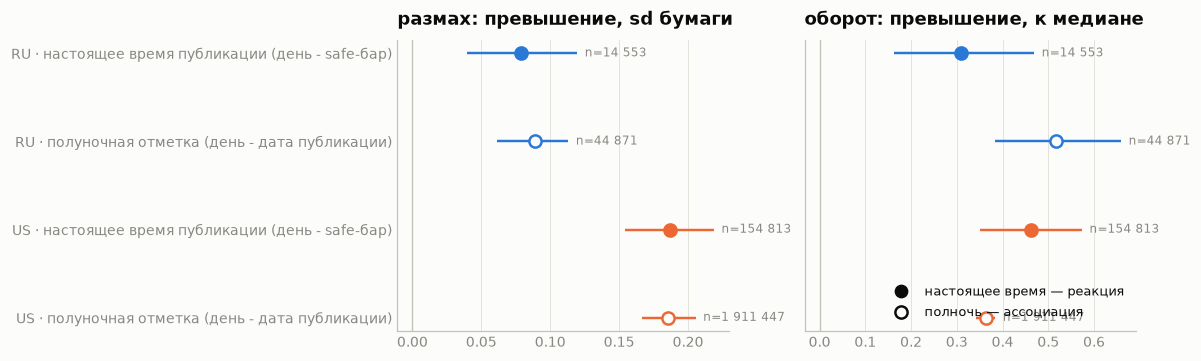

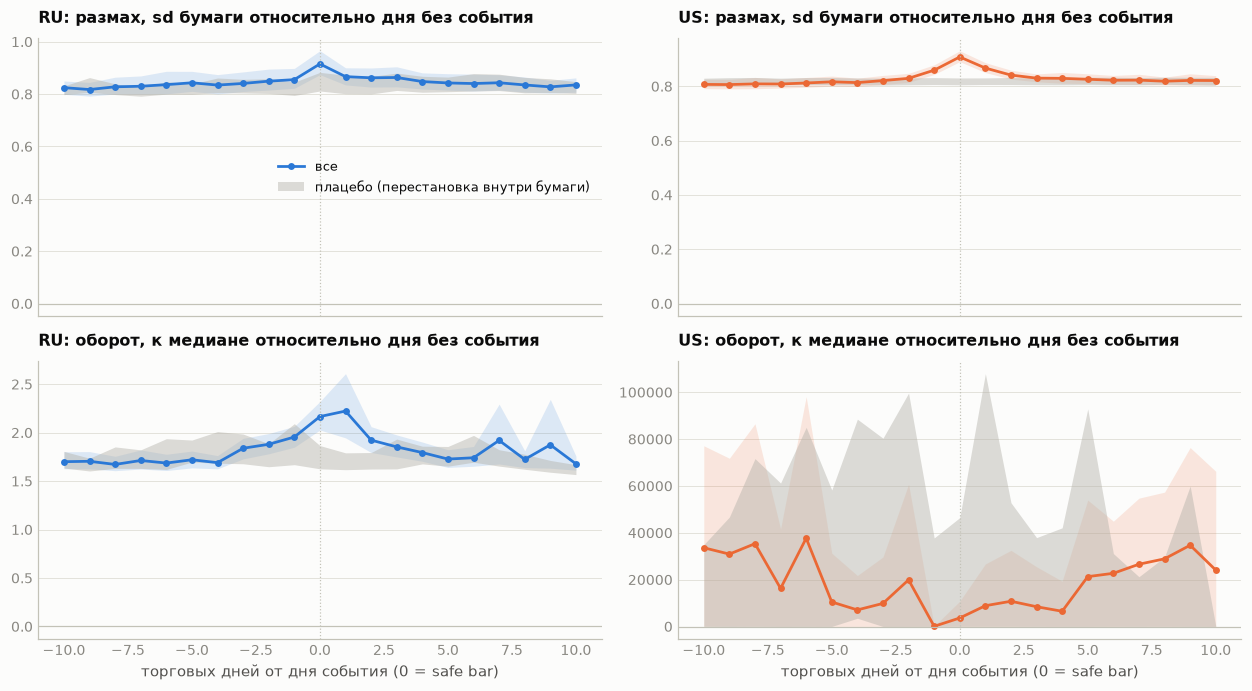

In [20]:
@S.show("ch06_timeknown", title="Настоящее время против полуночи")
def _(tk):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
    tk["label"] = tk.market + " · " + tk.subsample
    y = np.arange(len(tk))[::-1]
    for ax, (col, ttl) in zip(axes, [("absr", "размах: превышение, sd бумаги"), ("turn", "оборот: превышение, к медиане")]):
        for yi, (_, r) in zip(y, tk.iterrows()):
            c = market_color(r.market); mk = "o" if r.subsample.startswith("наст") else "o"
            ax.hlines(yi, r[col + "_lo"], r[col + "_hi"], color=c, lw=1.6)
            ax.plot([r[col]], [yi], mk, color=c if r.subsample.startswith("наст") else COLORS["surface"], ms=8, markeredgecolor=c, markeredgewidth=1.6)
            ax.annotate(f"n={fmt_int(r.news_days)}", (r[col + "_hi"], yi), xytext=(5, 0), textcoords="offset points", va="center", fontsize=8, color=COLORS["muted"])
        zero_line(ax); ax.set_yticks(y); ax.set_yticklabels(tk.label); ax.set_title(ttl); ax.grid(axis="x"); ax.grid(False, axis="y")
    axes[1].legend(handles=[Line2D([], [], marker="o", color=COLORS["ink"], ls="", ms=8, label="настоящее время — реакция"),
                            Line2D([], [], marker="o", color=COLORS["surface"], markeredgecolor=COLORS["ink"], markeredgewidth=1.6, ls="", ms=8, label="полночь — ассоциация")],
                   loc="lower right", fontsize=8.5)
    fig.tight_layout()
    return fig

@S.show("event_window_profile", title="Что происходит вокруг события: −10…+10 торговых дней")
def _(ew):
    subs = [s for s in ["все", "настоящее время", "плацебо"] if s in set(ew.subsample)]
    fig, axes = plt.subplots(2, 2, figsize=(11.5, 6.4), sharex=True)
    for j, mk in enumerate(["RU", "US"]):
        for i, (col, lo, hi, ttl) in enumerate([("absr_n", "absr_lo", "absr_hi", "размах, sd бумаги"), ("turn_r", "turn_lo", "turn_hi", "оборот, к медиане")]):
            ax = axes[i, j]
            for s in subs:
                d = ew[(ew.market == mk) & (ew.subsample == s)].sort_values("k")
                if s == "плацебо":
                    ax.fill_between(d.k, d[lo], d[hi], color=COLORS["placebo"], alpha=0.45, lw=0, label="плацебо (перестановка внутри бумаги)")
                else:
                    c = market_color(mk) if s == "все" else COLORS["ink"]
                    ax.fill_between(d.k, d[lo], d[hi], color=c, alpha=0.15, lw=0)
                    ax.plot(d.k, d[col], marker="o", color=c, ms=3.5, label=f"{s}", ls="-" if s == "все" else "--")
            ax.axhline(0, color=COLORS["axis"], lw=0.8); ax.axvline(0, color=COLORS["axis"], lw=0.8, ls=":")
            ax.set_title(f"{mk}: {ttl} относительно дня без события", fontsize=10.5)
            if i == 1: ax.set_xlabel("торговых дней от дня события (0 = safe bar)")
    axes[0, 0].legend(fontsize=8.5)
    fig.tight_layout()
    return fig

<a id="4"></a>
## 4. Гипотезы: метод и результат по каждой

### 4.1 Общий аппарат событийного анализа

Стандартизация накопленной доходности (BMP): `SCAR_i = CAR_i / (s_i · √T · fe_i)`, где `s_i` —
остаточное СКО окна оценки (ddof = 2), `√T` — потому что дисперсия суммы T остатков растёт как T
(без корня тест на окне [2, 60] завышает статистику в √59 = 7,68 раза), `fe_i` — поправка Пателла.
Тест BMP `t = √N · mean(SCAR) / sd(SCAR)` с поправкой Kolari–Pynnönen на кросс-секционную корреляцию
остатков. **Плацебо** обязательно для каждой гипотезы: даты событий переставляются внутри бумаги.
Порог — **t ≥ 3** (Харви–Лю–Чжу), поправка Холма внутри семейства.

Вердикт у каждой строки — одно из четырёх механических значений: **подтверждена** (интервал вне нуля,
t ≥ 3, плацебо около нуля), **отличима от нуля, ниже порога** (интервал вне нуля, t < 3),
**не различима** (интервал накрывает ноль), **опровергнута** (противоположный знак или нарушен
заранее заданный критерий); плюс «недостаточно наблюдений» и «в работе».

id,рынок,что проверялось,метрика,ед.,эффект [95 % ДИ],t,n,плацебо,вердикт,примечание
H1,RU,HAR + внимание против HAR,прирост QLIKE вне выборки (DM),"QLIKE, доля потери HAR",—,—,—,—,недостаточно наблюдений,—
H1,US,HAR + внимание против HAR,прирост QLIKE вне выборки (DM),"QLIKE, доля потери HAR",—,—,—,—,недостаточно наблюдений,—
H1b,RU,только настоящее время публикации,прирост QLIKE вне выборки (DM),"QLIKE, доля потери HAR","-0,001 [-0,002; +0,000]","-1,15",1 382,—,не различима,событий 35874
H1b,RU,полночь → следующий торговый день,прирост QLIKE вне выборки (DM),"QLIKE, доля потери HAR","-0,000 [-0,000; +0,000]","-0,31",2 131,—,не различима,событий 261218
H1b,US,только настоящее время публикации,прирост QLIKE вне выборки (DM),"QLIKE, доля потери HAR","+0,000 [-0,000; +0,000]","1,11",879,—,не различима,событий 339147
H1b,US,полночь → следующий торговый день,прирост QLIKE вне выборки (DM),"QLIKE, доля потери HAR","+0,004 [+0,003; +0,006]","4,40",879,—,подтверждена,событий 11297475
H2,RU,CAR негатива,"CAR[0,1]",п.п. аномальной доходности,"-22,592 [-54,795; +4,780]","2,57",59 565,—,не различима,—
H2,RU,CAR позитива,"CAR[0,1]",п.п. аномальной доходности,"+18,723 [-5,229; +46,243]","-0,50",102 652,—,не различима,—
H2,RU,асимметрия негатив − позитив,разность CAR,п.п. аномальной доходности,"+3,869 [-11,782; +21,589]",—,—,—,не различима,—
H2,US,CAR негатива,"CAR[0,1]",п.п. аномальной доходности,"-0,493 [-1,464; +0,351]","28,83",2 024 052,—,не различима,—


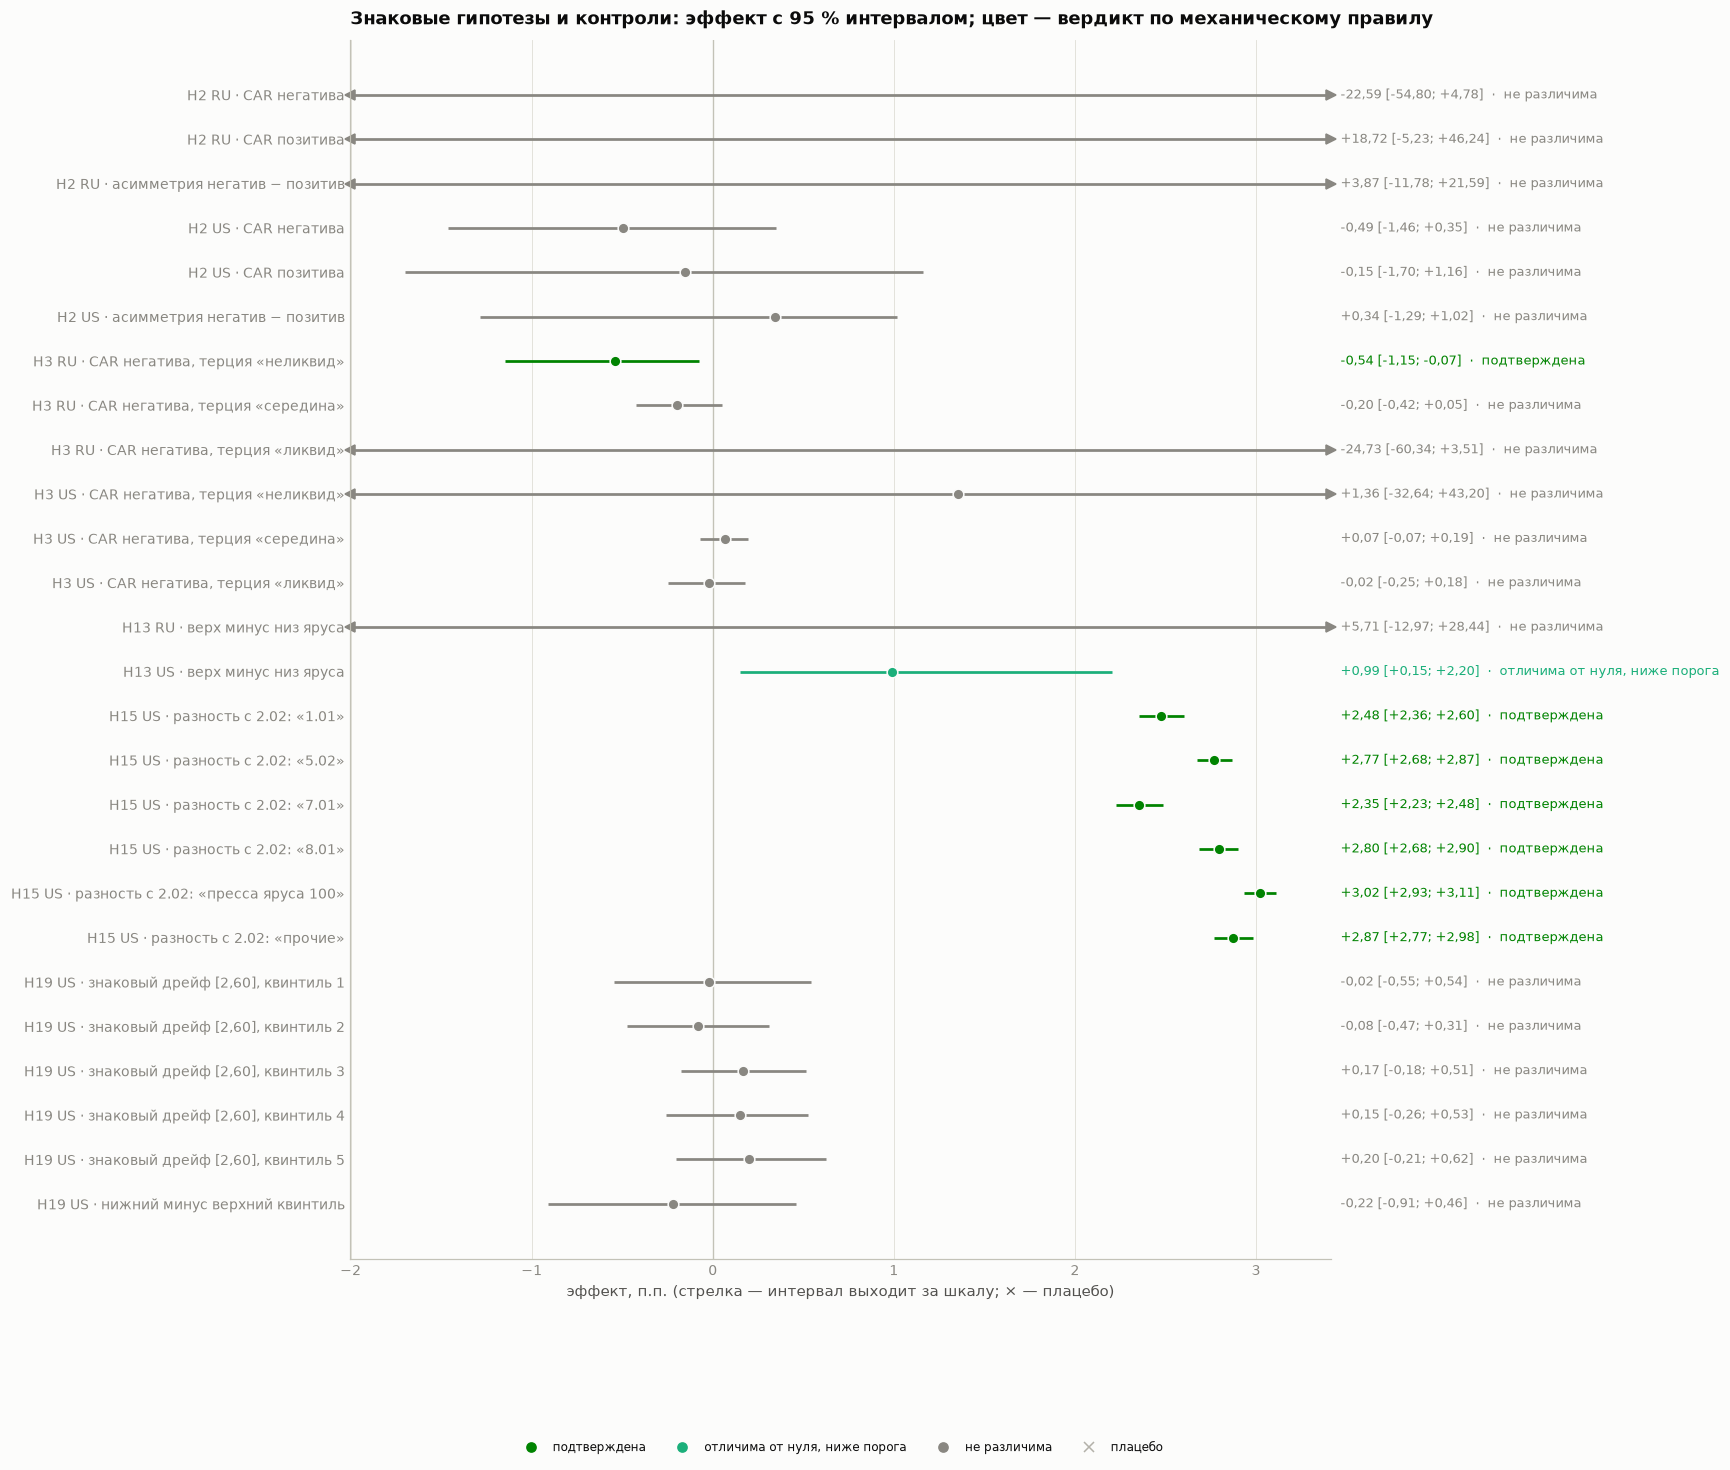

In [21]:
_VERD = {"подтверждена": COLORS["pos"], "отличима от нуля, ниже порога": COLORS["third"], "не различима": COLORS["muted"],
         "опровергнута": COLORS["neg"], "недостаточно наблюдений": COLORS["axis"], "в работе": COLORS["fourth"]}

@S.show("hypotheses", title="Сводная таблица гипотез")
def _(h):
    d = h.copy()
    d["эффект [95 % ДИ]"] = [fmt_ci(e, l, u, 3, plus=True) if pd.notna(e) else "—" for e, l, u in zip(d.estimate, d.lo, d.hi)]
    d["плацебо"] = [fmt(p, 3, plus=True) if pd.notna(p) else "—" for p in d.placebo]
    d["t"] = d.t.map(lambda v: fmt(v, 2) if pd.notna(v) else "—")
    d["n"] = d.n.map(lambda v: fmt_int(v) if pd.notna(v) else "—")
    d["вердикт"] = ["<span style='color:%s;font-weight:600'>%s</span>" % (_VERD.get(v, COLORS["ink"]), v) for v in d.verdict]
    cols = {"id": "id", "market": "рынок", "variant": "что проверялось", "metric": "метрика", "unit": "ед.", "эффект [95 % ДИ]": "эффект [95 % ДИ]",
            "t": "t", "n": "n", "плацебо": "плацебо", "вердикт": "вердикт", "note": "примечание"}
    out = d[list(cols)].rename(columns=cols)
    counts = h.verdict.value_counts()
    display(stat_tiles([(fmt_int(counts.get(k, 0)), k, "") for k in ["подтверждена", "отличима от нуля, ниже порога", "не различима", "опровергнута", "в работе"]], cols=5))
    return out

@S.show("hypotheses", title="Знаковые эффекты с интервалами")
def _(h):
    d = h[h.estimate.notna() & (h.family != "H1") & h.unit.str.startswith("п.п.")].copy()
    d["label"] = d.id + " " + d.market + " · " + d.variant
    d = d.reset_index(drop=True)
    # шкала — по «типичным» интервалам; очень широкие интервалы обрезаются стрелкой и подписываются числом
    w = (d.hi - d.lo); typical = d[w <= 4 * w.median()] if len(d) > 2 else d
    xmin = min(-1.0, float(typical.lo.min()) - 0.3); xmax = max(1.0, float(typical.hi.max()) + 0.3)
    fig, ax = plt.subplots(figsize=(11.5, 0.5 * len(d) + 1.4))
    y = np.arange(len(d))[::-1]
    for yi, (_, r) in zip(y, d.iterrows()):
        c = _VERD.get(r.verdict, COLORS["ink"])
        lo_c, hi_c = max(r.lo, xmin), min(r.hi, xmax)
        ax.hlines(yi, lo_c, hi_c, color=c, lw=1.8)
        if r.lo < xmin: ax.plot([xmin], [yi], marker="<", color=c, ms=6, clip_on=False)
        if r.hi > xmax: ax.plot([xmax], [yi], marker=">", color=c, ms=6, clip_on=False)
        if xmin <= r.estimate <= xmax:
            ax.plot([r.estimate], [yi], "o", color=c, ms=7, markeredgecolor=COLORS["surface"])
        if pd.notna(r.placebo) and xmin <= r.placebo <= xmax:
            ax.plot([r.placebo], [yi], "x", color=COLORS["placebo"], ms=7, mew=1.6)
        txt = f"{fmt_ci(r.estimate, r.lo, r.hi, 2, plus=True)}  ·  {r.verdict}"
        ax.text(1.01, yi, txt, transform=ax.get_yaxis_transform(), fontsize=8.5, va="center", color=c)
    zero_line(ax); ax.set_xlim(xmin, xmax)
    ax.set_yticks(y); ax.set_yticklabels(d.label, fontsize=9); ax.grid(axis="x"); ax.grid(False, axis="y")
    ax.set_xlabel("эффект, п.п. (стрелка — интервал выходит за шкалу; × — плацебо)")
    ax.set_title("Знаковые гипотезы и контроли: эффект с 95 % интервалом; цвет — вердикт по механическому правилу")
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=v, label=k) for k, v in _VERD.items() if k in set(d.verdict)]
              + [Line2D([], [], marker="x", ls="", color=COLORS["placebo"], label="плацебо")], loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=5, fontsize=8)
    return fig

### 4.2 H1 и H1b — новости в прогнозе волатильности

HAR (Corsi 2009) против HAR + z-оценка внимания (число уникальных сюжетов яруса ≥ 30 к норме 60
дней, кончающейся на t−1). Прогноз по расширяющемуся окну, переоценка раз в 22 дня, **эмбарго длиной
горизонта**, потеря QLIKE, тест Диболда–Мариано с HAC-дисперсией, порог t ≥ 3.

H1b — вариант, добавленный **после результатов раунда 1** (TASK12, 06.11): внимание дня t от событий с
датой t−1 (информационное множество — открытие t). Правило формулировки было задано до прогона:
вывод допустим, только если плацебо-прирост исчез **и** прирост на «несвежих» новостях меньше
основного. Все «подтверждена» — на dev; холдаут не открывался.

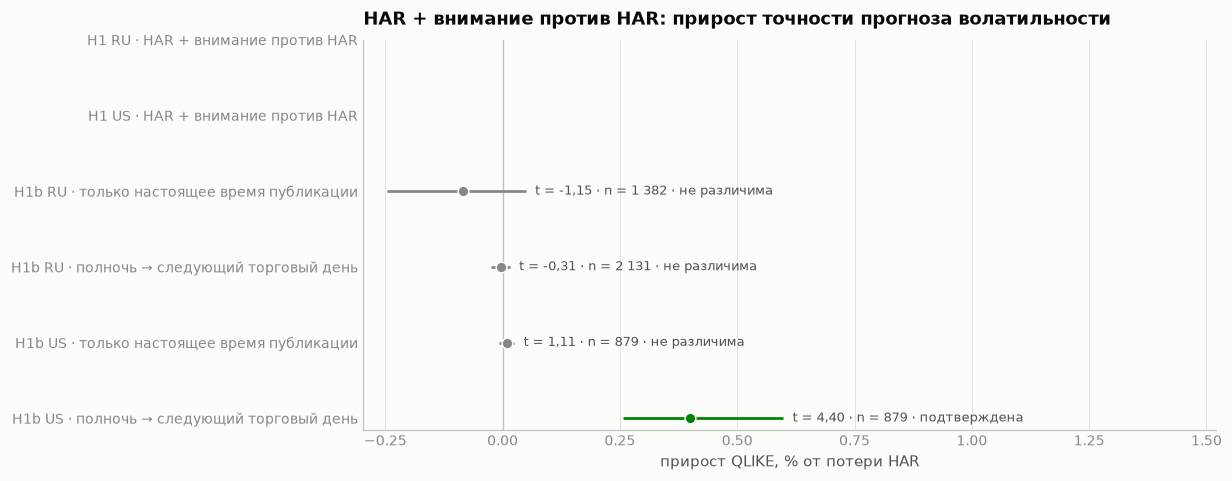

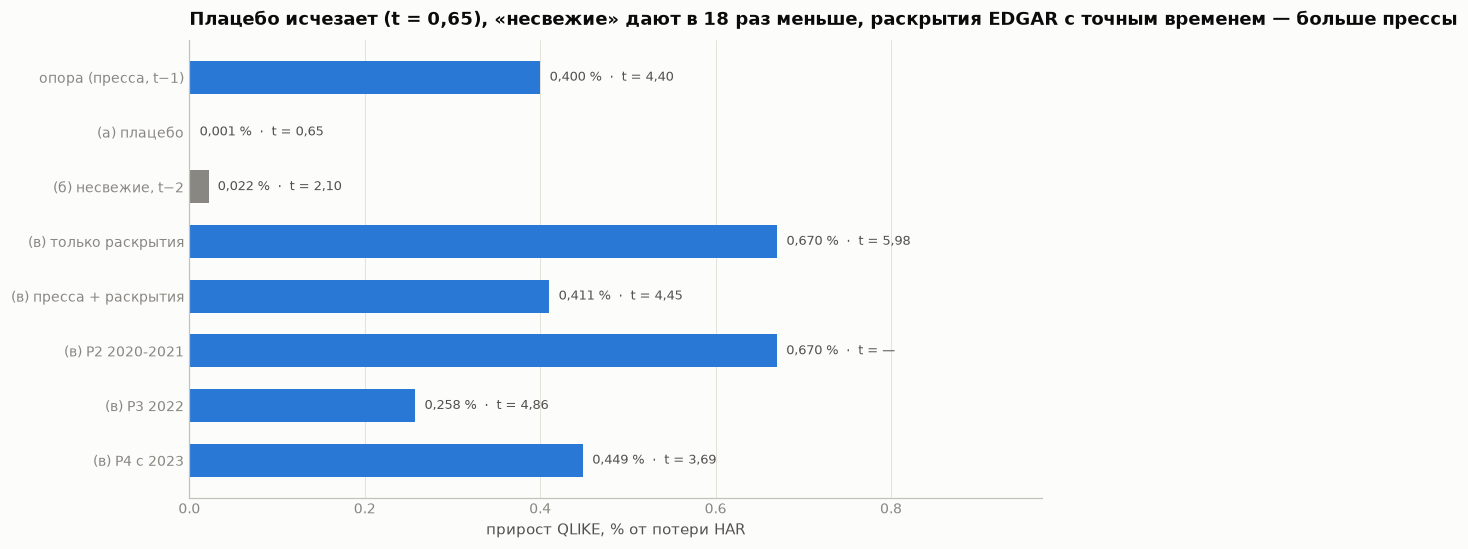

In [22]:
@S.show("hypotheses", title="H1 / H1b: прирост QLIKE")
def _(h):
    d = h[h.family == "H1"].copy()
    d["label"] = d.id + " " + d.market + " · " + d.variant
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(d) + 1))
    y = np.arange(len(d))[::-1]
    for yi, (_, r) in zip(y, d.iterrows()):
        c = _VERD.get(r.verdict, COLORS["ink"])
        if pd.notna(r.estimate):
            ax.hlines(yi, r.lo * 100, r.hi * 100, color=c, lw=1.8); ax.plot([r.estimate * 100], [yi], "o", color=c, ms=7, markeredgecolor=COLORS["surface"])
            ax.annotate(f"t = {fmt(r.t, 2)} · n = {fmt_int(r.n)} · {r.verdict}", (r.hi * 100, yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=COLORS["ink2"])
    zero_line(ax); ax.set_yticks(y); ax.set_yticklabels(d.label, fontsize=9); ax.grid(axis="x"); ax.grid(False, axis="y")
    ax.set_xlabel("прирост QLIKE, % от потери HAR"); ax.set_title("HAR + внимание против HAR: прирост точности прогноза волатильности")
    ax.set_xlim(min(-0.1, (d.lo.min() or 0) * 100 - 0.05), max(0.8, (d.hi.max() or 0) * 100) * 1.9)
    return fig

@S.show("h1b_diagnostics", title="H1b-US: три диагностики")
def _(dg):
    dg = dg.sort_values("order")
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(dg) + 1))
    y = np.arange(len(dg))[::-1]
    cols = [COLORS["placebo"] if "плацебо" in r else (COLORS["muted"] if "несвеж" in r else (COLORS["pos"] if "EDGAR" in r else COLORS["RU"])) for r in dg.run]
    ax.barh(y, dg.qlike_pct, color=cols, height=0.6)
    for yi, (_, r) in zip(y, dg.iterrows()):
        ax.annotate(f"{fmt(r.qlike_pct, 3)} %  ·  t = {fmt(r.t, 2)}", (max(r.qlike_pct, 0), yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=COLORS["ink2"])
    ax.set_yticks(y); ax.set_yticklabels(dg.run, fontsize=9); ax.grid(axis="x"); ax.grid(False, axis="y"); ax.set_xlim(0, dg.qlike_pct.max() * 1.45)
    ax.set_xlabel("прирост QLIKE, % от потери HAR"); ax.set_title("Плацебо исчезает (t = 0,65), «несвежие» дают в 18 раз меньше, раскрытия EDGAR с точным временем — больше прессы")
    return fig

### 4.3 H2, H3, H4, H13 — знаковая реакция

Единица наблюдения — событие, окно реакции [0, 1]. H13 важна не как гипотеза, а как **контроль**:
ярус — мера уверенности привязки, и эффект обязан расти с ярусом. Ограничение названо: ярус
частично совпадает с ролью, ярусы 10 и 20 событий не дают вовсе.

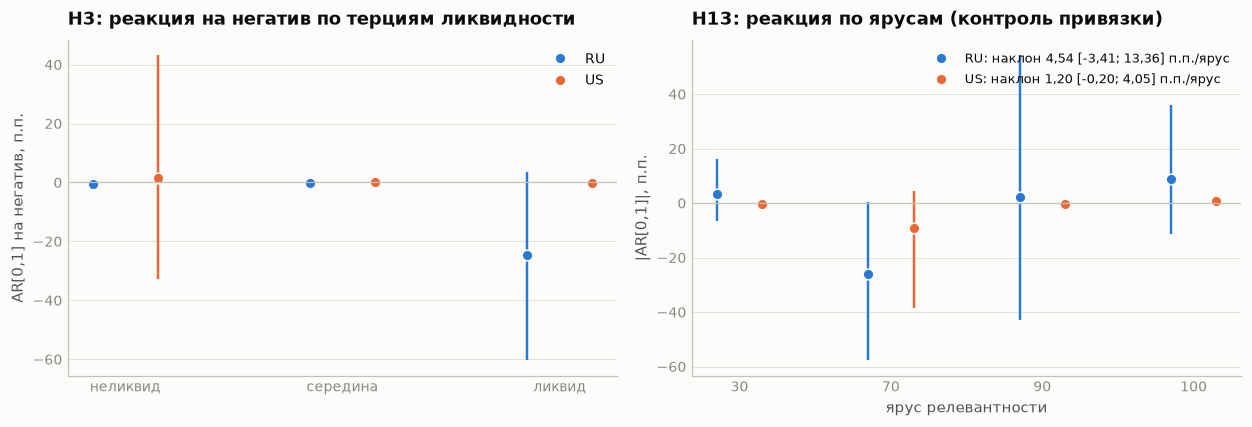

In [23]:
@S.show("h3_terciles", "h13_tiers", title="H3 по терциям ликвидности и H13 по ярусам")
def _(h3, h13):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
    ax = axes[0]
    order = ["неликвид", "середина", "ликвид"]
    for mk, off in (("RU", -0.15), ("US", 0.15)):
        d = h3[h3.market == mk].set_index("tercile").reindex(order)
        x = np.arange(3) + off
        ax.vlines(x, d.lo, d.hi, color=market_color(mk), lw=1.6); ax.plot(x, d.est, "o", color=market_color(mk), ms=7, label=mk, markeredgecolor=COLORS["surface"])
    ax.axhline(0, color=COLORS["axis"], lw=0.8); ax.set_xticks(range(3)); ax.set_xticklabels(order); ax.set_ylabel("AR[0,1] на негатив, п.п.")
    ax.set_title("H3: реакция на негатив по терциям ликвидности"); ax.legend()
    ax = axes[1]
    for mk, off in (("RU", -0.15), ("US", 0.15)):
        d = h13[h13.market == mk].sort_values("tier")
        x = np.arange(len(d)) + off
        ax.vlines(x, d.lo, d.hi, color=market_color(mk), lw=1.6); ax.plot(x, d.est, "o", color=market_color(mk), ms=7, markeredgecolor=COLORS["surface"],
                 label=f"{mk}: наклон {fmt(d.slope.iloc[0], 2)} [{fmt(d.slope_lo.iloc[0], 2)}; {fmt(d.slope_hi.iloc[0], 2)}] п.п./ярус")
        ax.set_xticks(range(len(d))); ax.set_xticklabels(d.tier.astype(int))
    ax.axhline(0, color=COLORS["axis"], lw=0.8); ax.set_xlabel("ярус релевантности"); ax.set_ylabel("|AR[0,1]|, п.п.")
    ax.set_title("H13: реакция по ярусам (контроль привязки)"); ax.legend(fontsize=8.5)
    fig.tight_layout()
    return fig

### 4.4 H15 — какой класс раскрытий даёт самую сильную реакцию

Класс подачи 8-K — из метаданных SEC; пункт 9.01 игнорируется. Разности против класса 2.02 —
бутстрэпом по датам. **Подтверждена**: 2.02 сильнее каждого класса по обоим мерилам.

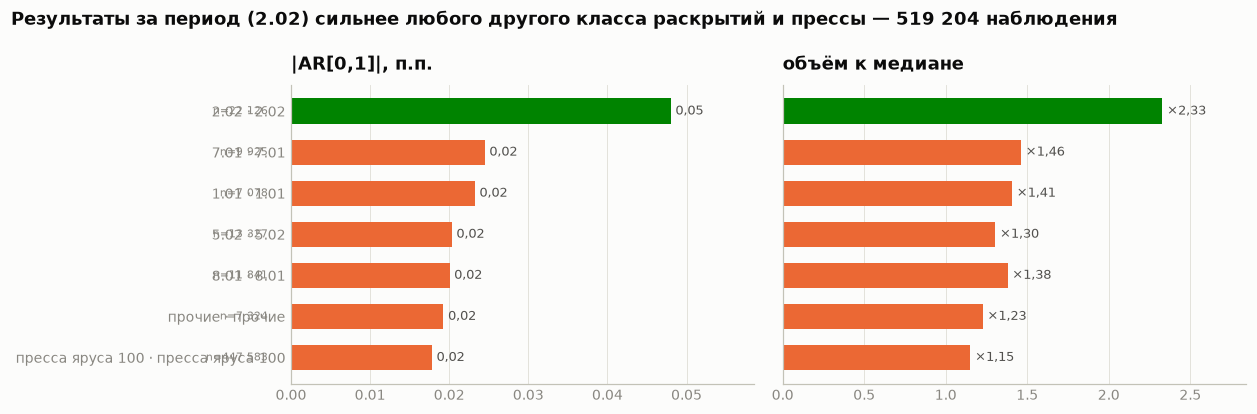

In [24]:
@S.show("h15_items", title="H15: классы 8-K")
def _(h15):
    d = h15.sort_values("abs_ar", ascending=True)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
    labels = [f"{i} · {l}" for i, l in zip(d["item"], d.label)]
    cols = [COLORS["pos"] if i == "2.02" else (COLORS["muted"] if i == "пресса" else COLORS["US"]) for i in d["item"]]
    for ax, col, ttl, f in zip(axes, ["abs_ar", "vol_ratio"], ["|AR[0,1]|, п.п.", "объём к медиане"], [lambda v: fmt(v, 2), lambda v: "×" + fmt(v, 2)]):
        bars = ax.barh(labels, d[col], color=cols, height=0.62); label_bars(ax, bars, fmt_fn=f, horizontal=True)
        ax.set_title(ttl); ax.grid(axis="x"); ax.grid(False, axis="y"); ax.set_xlim(0, d[col].max() * 1.22)
    for yi, n in enumerate(d.n):
        axes[0].text(-0.05, yi, f"n={fmt_int(n)}", ha="right", va="center", fontsize=7.5, color=COLORS["muted"], transform=axes[0].get_yaxis_transform())
    fig.suptitle("Результаты за период (2.02) сильнее любого другого класса раскрытий и прессы — 519 204 наблюдения", x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.tight_layout()
    return fig

### 4.5 H16 — укладывается ли реакция в первый час

Внутрисессионные подачи — по минуткам (с 2024-01), внесессионные — по дневным барам. Вердикт
двумя частями: **первый час — опровергнута** (за час проходит 14 % объёма и 26 % хода), **ночной
ночной разрыв — подтверждена** (у внесессионных подач 83 % движения приходится на разрыв до открытия). Это
верхняя оценка: цены открытия в ряду нет, за разрыв берётся весь ход дня события. n = 490
внутрисессионных подач — мало, и это названо как ограничение.

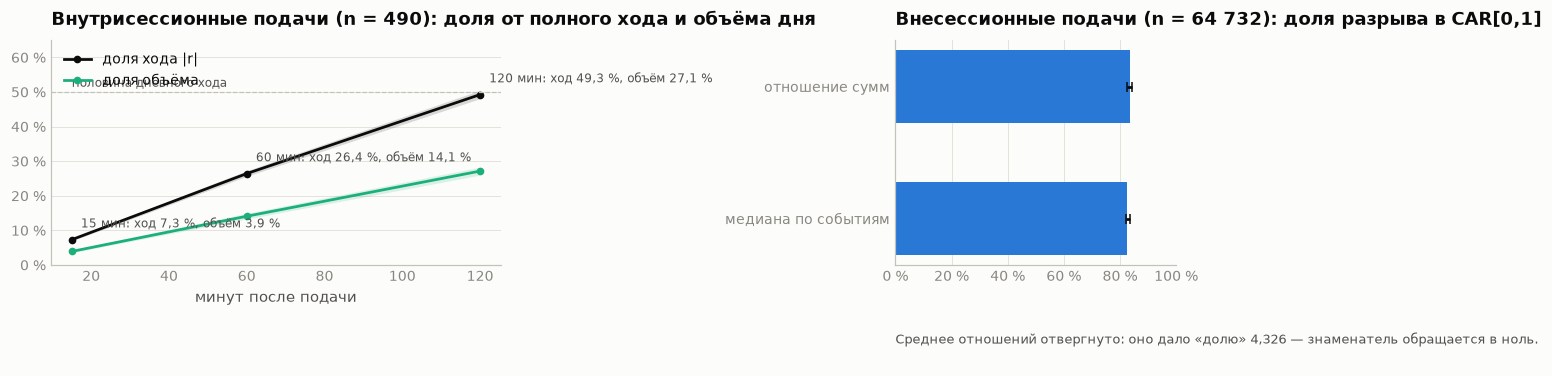

In [25]:
@S.show("h16_horizons", "h16_gap", title="H16: доля реакции по минутам после подачи")
def _(hz, gap):
    hz = hz.sort_values("horizon_min")
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
    ax = axes[0]
    for col, lo, hi, c, lab in [("move_share", "move_lo", "move_hi", COLORS["ink"], "доля хода |r|"), ("vol_share", "vol_lo", "vol_hi", COLORS["third"], "доля объёма")]:
        ax.fill_between(hz.horizon_min, hz[lo], hz[hi], color=c, alpha=0.15, lw=0); ax.plot(hz.horizon_min, hz[col], "-o", color=c, ms=4, label=lab)
    for hm in (15, 60, 120):
        r = hz.iloc[(hz.horizon_min - hm).abs().argsort().iloc[0]]
        ax.annotate(f"{int(r.horizon_min)} мин: ход {pct(r.move_share, 1)}, объём {pct(r.vol_share, 1)}", (r.horizon_min, r.move_share), xytext=(6, 8), textcoords="offset points", fontsize=8, color=COLORS["ink2"])
    ax.axhline(0.5, color=COLORS["axis"], lw=0.8, ls="--"); ax.text(hz.horizon_min.min(), 0.515, "половина дневного хода", fontsize=8, color=COLORS["ink2"])
    ru_axis(ax, "y", 0, pct_axis=True); ax.set_ylim(0, 0.65); ax.set_xlabel("минут после подачи"); ax.set_title(f"Внутрисессионные подачи (n = {fmt_int(hz.n.iloc[0])}): доля от полного хода и объёма дня"); ax.legend(loc="upper left")
    ax = axes[1]
    ax.barh([1, 0], [gap["ratio_sums"], gap["median"]], color=[COLORS["RU"], COLORS["RU"]], height=0.55)
    ax.errorbar([gap["ratio_sums"], gap["median"]], [1, 0], xerr=[[gap["ratio_sums"] - gap["lo"], gap["median"] - gap["med_lo"]], [gap["hi"] - gap["ratio_sums"], gap["med_hi"] - gap["median"]]], fmt="none", ecolor=COLORS["ink"], capsize=3)
    ax.set_yticks([1, 0]); ax.set_yticklabels(["отношение сумм", "медиана по событиям"]); ax.set_xlim(0, 1); ru_axis(ax, "x", 0, pct_axis=True); ax.grid(axis="x"); ax.grid(False, axis="y")
    ax.set_title(f"Внесессионные подачи (n = {fmt_int(gap['n'])}): доля разрыва в CAR[0,1]")
    note(ax, f"Среднее отношений отвергнуто: оно дало «долю» {fmt(gap['mean_of_ratios_rejected'], 3)} — знаменатель обращается в ноль.", xy=(0, -0.3))
    fig.tight_layout()
    return fig

### 4.6 H19 — PEAD только в микрокапах

Знак сюрприза — ценовой прокси из AR[0,1] (консенсуса прибыли в проекте нет), размер — медианный
дневной оборот в долларах за [−65, −6] дней, квинтили внутри календарного года. Отклонение от
предрегистрации (там была капитализация) названо; таблица числа акций собрана, пересчёт возможен.

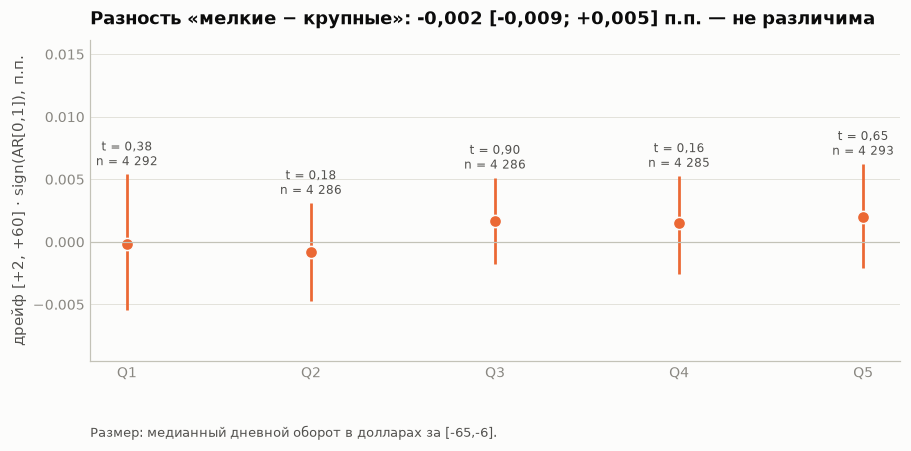

In [26]:
@S.show("h19_quintiles", title="H19: знаковый дрейф по квинтилям размера")
def _(q):
    q = q.sort_values("quintile")
    fig, ax = plt.subplots(figsize=(9.5, 3.8))
    x = np.arange(len(q))
    ax.vlines(x, q.lo, q.hi, color=COLORS["US"], lw=1.8); ax.plot(x, q.drift, "o", color=COLORS["US"], ms=8, markeredgecolor=COLORS["surface"])
    for xi, (_, r) in zip(x, q.iterrows()):
        ax.annotate(f"t = {fmt(r.t, 2)}\nn = {fmt_int(r.events)}", (xi, r.hi), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8, color=COLORS["ink2"])
    ax.axhline(0, color=COLORS["axis"], lw=0.8); ax.set_xticks(x); ax.set_xticklabels(q.label); ax.set_ylabel("дрейф [+2, +60] · sign(AR[0,1]), п.п.")
    # эффект здесь порядка 0,002 п.п.; поля в 0,3 п.п. схлопывали
    # все пять точек в ноль. Поля считаем от размаха самих данных.
    span = float(q.hi.max() - q.lo.min()) or 0.01
    ax.set_ylim(float(q.lo.min()) - span * 0.35, float(q.hi.max()) + span * 0.85)
    ax.set_title(f"Разность «мелкие − крупные»: {fmt_ci(q.diff_1_5.iloc[0], q.diff_lo.iloc[0], q.diff_hi.iloc[0], 3, plus=True)} п.п. — не различима")
    note(ax, f"Размер: {q.size_proxy.iloc[0]}.", xy=(0, -0.2))
    return fig

### 4.7 Раунд 2 на российском рынке (H14, H17, H18, H22, H23, H24)

Предрегистрация — в `docs/TASK13_round2.md`: у каждой гипотезы заранее записаны выборка, метрика,
тест, плацебо и критерии «подтверждена, если / опровергнута, если». Строки появляются здесь из того же
`hypotheses`, когда прогон завершён; до тех пор стоит «в работе».

In [27]:
S.show_table("hypotheses", title="Раунд 2, RU", query="market == 'RU' and id in ['H14','H17','H18','H22','H23','H24']",
             columns={"id": "id", "variant": "что проверялось", "metric": "метрика", "estimate": "эффект", "lo": "ДИ ниж.", "hi": "ДИ верх.", "t": "t", "n": "n", "verdict": "вердикт", "note": "примечание"})

id,что проверялось,метрика,эффект,ДИ ниж.,ДИ верх.,t,n,вердикт,примечание
H14,"раунд 2, вторая сессия",—,—,—,—,—,—,в работе,"строки появятся, когда закроется раунд 2 по России"
H17,"раунд 2, вторая сессия",—,—,—,—,—,—,в работе,"строки появятся, когда закроется раунд 2 по России"
H18,"раунд 2, вторая сессия",—,—,—,—,—,—,в работе,"строки появятся, когда закроется раунд 2 по России"
H22,"раунд 2, вторая сессия",—,—,—,—,—,—,в работе,"строки появятся, когда закроется раунд 2 по России"
H23,"раунд 2, вторая сессия",—,—,—,—,—,—,в работе,"строки появятся, когда закроется раунд 2 по России"
H24,"раунд 2, вторая сессия",—,—,—,—,—,—,в работе,"строки появятся, когда закроется раунд 2 по России"


<a id="5"></a>
## 5. ML-зонды

### 5.1 C1 — карта сюжетов на эмбеддингах

Эмбеддинги **bge-m3** (1024 измерения) → PCA(50) → **UMAP** → **HDBSCAN** (минимальный размер
кластера 400). Выборка — все документы RU яруса 100 плюс столько же US, пропорционально объёму года:
при естественной пропорции (документов США в 35 раз больше) Россия на карте была бы невидима.
Поэтому доля рынка в кластере читается как «чей это сюжет внутри сопоставимых выборок». Кластеры
найдены без разметки; реакция по кластерам — сырые |r[0,1]| и оборот к медиане, без беты — это
описание, а не оценка эффекта.

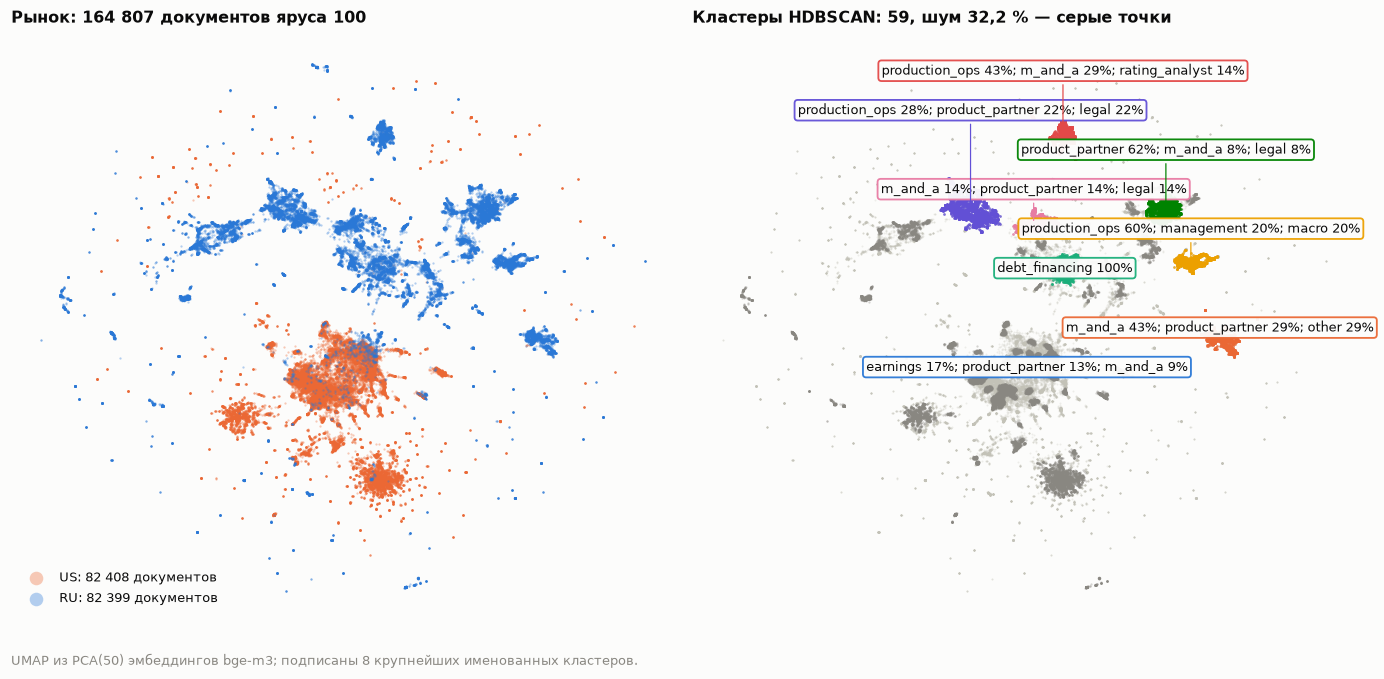

In [28]:
@S.show("c1_points", "c1_clusters", "c1_params", title="Карта сюжетов: рынок и кластеры")
def _(pts, cl, prm):
    # Часть кластеров без имени - иначе в подпись уходило слово nan.
    cl = cl.copy()
    cl["label"] = cl.label.fillna("").astype(str)
    cl.loc[cl.label.str.strip() == "", "label"] = "кластер " + cl.cluster.astype(str)
    n_full = pts.market.value_counts()
    pts = pts.sample(min(len(pts), 60_000), random_state=7) if len(pts) > 60_000 else pts
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
    ax = axes[0]
    for mk in ["US", "RU"]:
        d = pts[pts.market == mk]
        ax.scatter(d.x, d.y, s=2.2, c=market_color(mk), alpha=0.35, lw=0, label=f"{mk}: {fmt_int(n_full.get(mk, 0))} документов", rasterized=True)
    ax.set_title(f"Рынок: {fmt_int(prm['sample_n'])} документов яруса 100", fontsize=10.5)
    ax.legend(markerscale=6, loc="lower left", fontsize=8.5)
    ax = axes[1]
    noise = pts[pts.cluster == -1]
    ax.scatter(noise.x, noise.y, s=1.6, c=COLORS["axis"], alpha=0.25, lw=0, rasterized=True)
    clustered = pts[pts.cluster != -1]
    ax.scatter(clustered.x, clustered.y, s=2.2, c=COLORS["muted"], alpha=0.35, lw=0, rasterized=True)
    top = cl.sort_values("n", ascending=False)
    named = top[~top.label.str.startswith("кластер")].head(8) if (~top.label.str.startswith("кластер")).any() else top.head(8)
    # подписи: простое расталкивание по вертикали, чтобы рамки не ложились друг на друга
    span_y = (pts.y.max() - pts.y.min()) or 1.0; span_x = (pts.x.max() - pts.x.min()) or 1.0
    lab = named.sort_values("cy").copy(); lab["ly"] = lab.cy.astype(float)
    ly = lab.ly.to_list(); lx = lab.cx.to_list()
    for i in range(1, len(ly)):
        for j in range(i):
            if abs(lx[i] - lx[j]) < 0.42 * span_x and abs(ly[i] - ly[j]) < 0.075 * span_y:
                ly[i] = ly[j] + 0.075 * span_y
    lab["ly"] = ly
    for (_, r), c in zip(lab.iterrows(), CATEGORICAL):
        d = clustered[clustered.cluster == r.cluster]
        ax.scatter(d.x, d.y, s=3.2, c=c, alpha=0.75, lw=0, rasterized=True)
        ax.annotate(r.label, (r.cx, r.cy), xytext=(r.cx, r.ly), textcoords="data", fontsize=8.5, color=COLORS["ink"], ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.25", fc=COLORS["surface"], ec=c, lw=1.2, alpha=0.95),
                    arrowprops=dict(arrowstyle="-", color=c, lw=0.8) if abs(r.ly - r.cy) > 1e-9 else None)
    ax.set_title(f"Кластеры HDBSCAN: {fmt_int(prm['clusters'])}, шум {pct(prm['noise_share'], 1)} — серые точки", fontsize=10.5)
    for a in axes:
        a.set_xticks([]); a.set_yticks([]); a.grid(False); despine_all(a)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    # Подробности построения - под рисунком: в заголовках они наползали
    # друг на друга.
    fig.text(0.012, 0.015, f"UMAP из PCA(50) эмбеддингов {prm['embedding_model']}; подписаны 8 крупнейших именованных кластеров.", fontsize=8.5, color="#898781")
    return fig

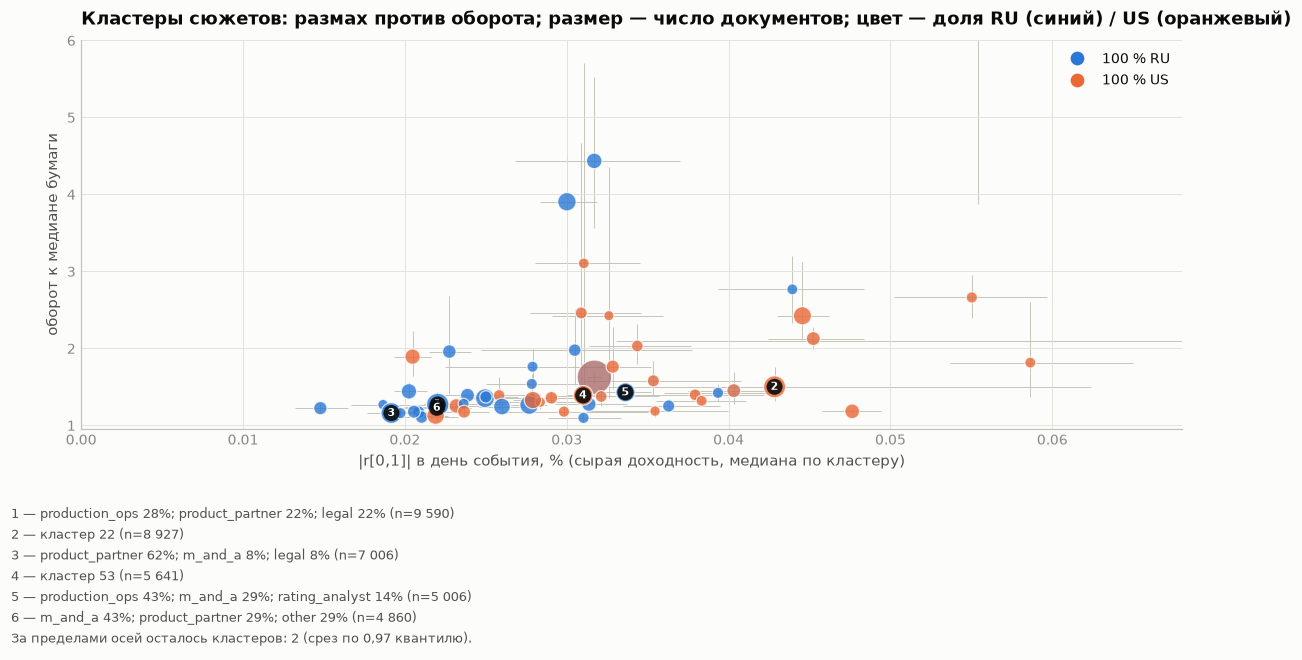

кластер,n,типичные заголовки (ближайшие к центроиду)
-1 · earnings 17%; product_partner 13%; m_and_a 9%,53 026,"nan Russia's Gazprom : Continues Shipping Gas To Europe Via Ukraine,…nan Plug Power-Aktie: Wunder! () | aktiencheck.denan Plug Power-Aktie: Das kommt nicht überraschend () | aktiencheck.denan Zillow : New Forecast Sees Sales Peak This Fall, Stay Above Pre-Pandemic Levels Through the Coming Year | MarketScreener"
0 · rating_analyst 75%; price_move 25%,614,nan Lukoil Aktie: Das dürfte so richtig spannend werden! () | aktiencheck.denan Lukoil Aktie: Was für ein Plan! () | aktiencheck.denan Lukoil Aktie: Hammer Entwicklung! () | aktiencheck.denan Lukoil Aktie: Das macht richtig Spaß! () | aktiencheck.de
1 · m_and_a 43%; product_partner 29%; other 29%,4 860,nan «Яндекс» объявил о возможном разделении бизнесаnan «Яндекс» объявил о возможном разделении бизнесаnan «Яндекс» определяется со сделкойnan «Яндекс» подтвердил планы по разделу компании
2 · nan,600,nan Polymetal Aktie: Anleger werden sich richtig freuen! () | aktiencheck.denan Polymetal Aktie: Hier wird jetzt richtig Fahrt aufgenommen! () | aktiencheck.denan Polymetal Aktie: Jetzt aber! () | aktiencheck.denan Polymetal-Anleger wird’s freuen! () | aktiencheck.de
3 · rating_analyst 50%; price_move 50%,570,"nan Yandex Aktie: Jetzt wird es spannend! () | aktiencheck.denan Yandex Aktie: Womit Sie rechnen sollten! () | aktiencheck.denan Yandex Aktie: Gut, wenn Sie noch investiert sind! () | aktiencheck.denan Yandex Aktie: Bloß nicht in Panik verfallen! () | aktiencheck.de"
4 · nan,848,nan Gazprom Aktie: Augen auf! () | aktiencheck.denan Gazprom Aktie: Augen auf! () | aktiencheck.denan Gazprom Aktie: Was ist jetzt zu tun! () | aktiencheck.denan Gazprom Aktie: Es gibt was neues! () | aktiencheck.de
5 · nan,585,nan Чистая прибыль «Газпрома» в 2022 году рухнулаnan Чистая прибыль «Газпрома» за первое полугодие составила 296 млрд рублейnan «Газпром» сообщил о падении чистой прибылиnan «Газпром» сообщил о падении чистой прибыли компании - Газета.Ru | Новости
6 · production_ops 43%; m_and_a 29%; rating_analyst 14%,5 006,"nan ""Аэрофлот"" уточнил, что сократит число внутренних рейсов с 4 апреля, а не с 6nan ""Аэрофлот"" с 6 апреля сокращает количество внутренних рейсовnan ""Аэрофлот"" организует рейсы в европейские города для возвращения российских пассажировnan «Аэрофлот» начал продавать организованные туры"
7 · product_partner 100%,1 435,nan «Газпром» пригрозил Молдавии прекращением поставок газаnan Молдавия назвала условия выплаты долга «Газпрому»nan «Газпром» продолжает поставлять газ в Молдавию - Газета.Ru | Новостиnan «Молдовагаз» получил от «Газпрома» уведомление о возможном прекращении поставок газа - Газета.Ru | Новости
8 · nan,726,nan First Week of October 17th Options Trading For EHang Holdingsnan Interesting CORT Put Options For January 2026nan First Week of YNDX October 15th Options Tradingnan September 27th Options Now Available For The Trade Desk (TTD)


In [29]:
@S.show("c1_clusters", title="Реакция рынка по кластерам")
def _(cl):
    fig, ax = plt.subplots(figsize=(11, 6.8))
    d = cl.copy()
    # У части кластеров имени нет - в подпись шло слово nan.
    d["label"] = d.label.fillna("").astype(str)
    d.loc[d.label.str.strip() == "", "label"] = "кластер " + d.cluster.astype(str)
    mix = np.array([np.array(mpl.colors.to_rgb(COLORS["RU"])) * s + np.array(mpl.colors.to_rgb(COLORS["US"])) * (1 - s) for s in d.share_ru.clip(0, 1)])
    ax.scatter(d.absr, d.turn, s=np.sqrt(d.n) * 2.2, c=mix, alpha=0.8, lw=0.8, edgecolors=COLORS["surface"])
    ax.errorbar(d.absr, d.turn, xerr=[d.absr - d.absr_lo, d.absr_hi - d.absr], yerr=[d.turn - d.turn_lo, d.turn_hi - d.turn], fmt="none", ecolor=COLORS["axis"], elinewidth=0.6, zorder=0)
    # Основная масса кластеров лежит в левом нижнем углу, одиночные выбросы
    # растягивали обе оси и сминали всё остальное в точку. Режем по 0,97
    # квантилю и говорим в подписи, сколько кластеров осталось за кадром.
    xhi = float(np.quantile(d.absr_hi, 0.97)) * 1.08
    yhi = float(np.quantile(d.turn_hi, 0.97)) * 1.08
    out = int(((d.absr > xhi) | (d.turn > yhi)).sum())
    ax.set_xlim(0, xhi); ax.set_ylim(max(0.0, float(d.turn_lo.min()) * 0.92), yhi)
    # Подписи шести крупнейших кластеров ложились друг на друга: все они
    # сидят в одной плотной области. Поэтому на точках — номера, а имена
    # списком под рисунком.
    lab = d[d.cluster >= 0].sort_values("n", ascending=False).head(6)
    lab = lab[(lab.absr <= xhi) & (lab.turn <= yhi)].reset_index(drop=True)
    lines = []
    for k, r in lab.iterrows():
        ax.annotate(str(k + 1), (r.absr, r.turn), ha="center", va="center",
                    fontsize=7.5, fontweight="bold", color="#ffffff", zorder=5,
                    bbox=dict(boxstyle="circle,pad=0.20", fc=COLORS["ink"], ec="none", alpha=0.9))
        name = r.label if len(r.label) <= 56 else r.label[:54] + "…"
        lines.append(f"{k + 1} — {name} (n={fmt_int(r.n)})")
    if out:
        lines.append(f"За пределами осей осталось кластеров: {out} (срез по 0,97 квантилю).")
    ax.set_xlabel("|r[0,1]| в день события, % (сырая доходность, медиана по кластеру)"); ax.set_ylabel("оборот к медиане бумаги")
    ax.set_title("Кластеры сюжетов: размах против оборота; размер — число документов; цвет — доля RU (синий) / US (оранжевый)")
    handles = [Line2D([], [], marker="o", ls="", color=COLORS["RU"], ms=8, label="100 % RU"), Line2D([], [], marker="o", ls="", color=COLORS["US"], ms=8, label="100 % US")]
    ax.legend(handles=handles, loc="upper right")
    fig.subplots_adjust(left=0.07, right=0.98, top=0.92, bottom=0.40)
    fig.text(0.012, 0.30, "\n".join(lines), fontsize=8.5, color=COLORS["ink2"], va="top", linespacing=1.6)
    ax.grid(True, axis="both")
    return fig

@S.show("c1_clusters", "c1_titles", title="Типичные заголовки кластеров")
def _(cl, tt):
    names = cl.set_index("cluster").label
    rows = []
    for c, g in tt.groupby("cluster"):
        rows.append({"кластер": f"{c} · {names.get(c, '')}", "n": fmt_int(cl.set_index('cluster').n.get(c, np.nan)),
                     "типичные заголовки (ближайшие к центроиду)": "<br>".join(f"<span style='color:#898781'>{d}</span> {t}" for d, t in zip(g.date.head(4), g.title.head(4)))})
    return pd.DataFrame(rows)

#### Сюжеты во времени

Кластеры — это и календарь: сезон отчётности виден по квартальному пульсу, санкционный сюжет —
по ступеням 2014 и 2022, решения ЦБ — по росту после 2022.

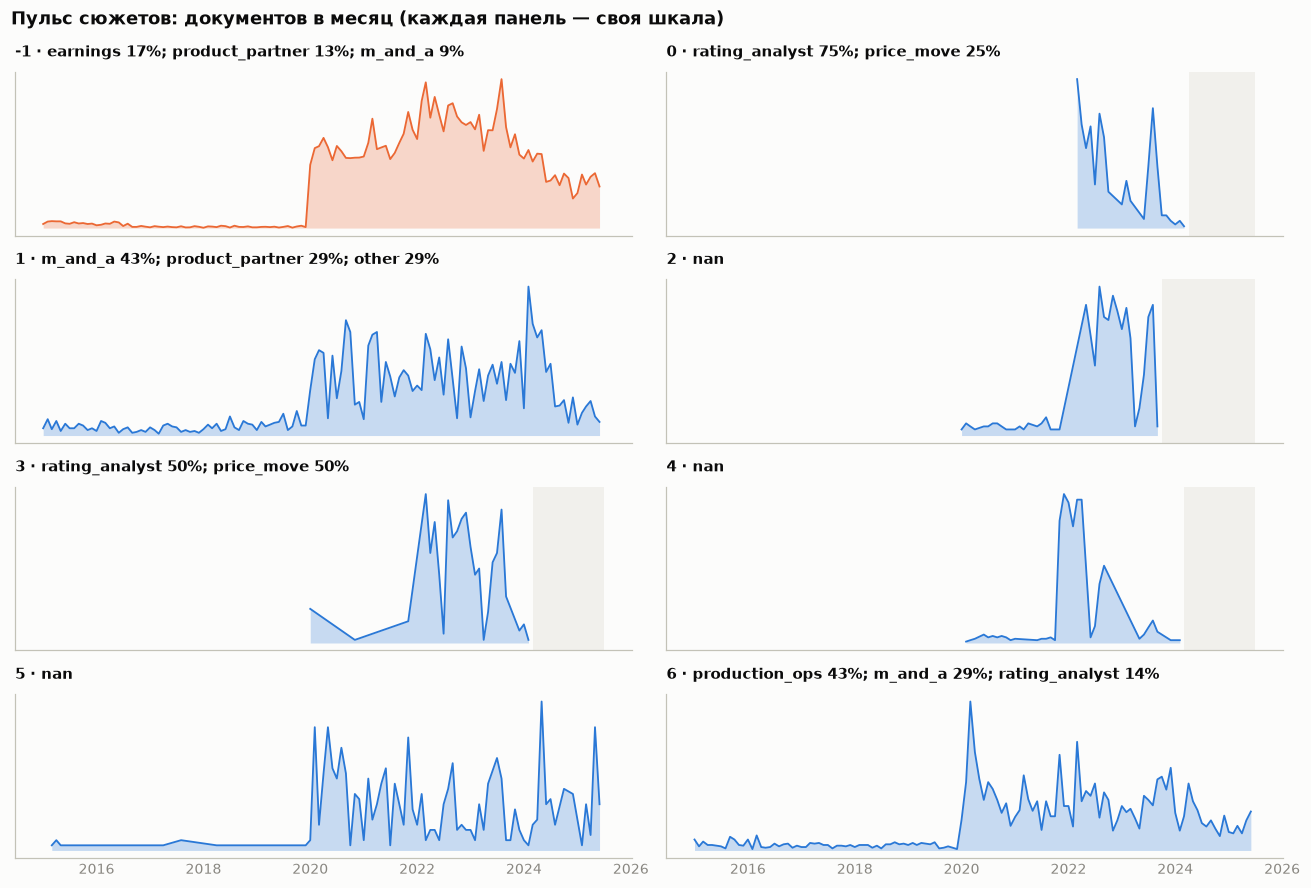

In [30]:
@S.show("c1_cluster_monthly", "c1_clusters", title="Документов в месяц по выделенным кластерам")
def _(cm, cl):
    names = cl.set_index("cluster").label
    cm["month"] = pd.PeriodIndex(cm["month"], freq="M").to_timestamp()
    cls = list(cm.cluster.unique())[:8]
    n = len(cls); ncol = 2; nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(12, 1.9 * nrow + 0.6), sharex=True)
    axes = np.array(axes).reshape(-1)
    for ax, c in zip(axes, cls):
        d = cm[cm.cluster == c].sort_values("month")
        col = COLORS["RU"] if cl.set_index("cluster").share_ru.get(c, 0.5) >= 0.5 else COLORS["US"]
        ax.fill_between(d.month, 0, d.docs, color=col, alpha=0.25, lw=0); ax.plot(d.month, d.docs, color=col, lw=1.2)
        ax.set_title(f"{c} · {names.get(c, '')}", fontsize=9.5, loc="left"); ax.set_yticks([]); ax.grid(False)
        ax.axvspan(pd.Timestamp("2025-07-01"), d.month.max() + pd.Timedelta(days=31), color=COLORS["band"], alpha=0.6, lw=0)
    for ax in axes[n:]: ax.set_axis_off()
    fig.suptitle("Пульс сюжетов: документов в месяц (каждая панель — своя шкала)", x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.tight_layout()
    return fig

### 5.2 C2 — вклад новостей сверх цен

Две модели LightGBM на одних событиях: **P** — только 8 ценовых признаков (окно кончается на баре
перед движением); **P+N** — те же 8 плюс эмбеддинг 1024 и тональность. Два горизонта: **день события**
(цель включает день события — слово «предсказывает» не употребляется) и **следующий день** (цель на день
i+1, новости только из известных к открытию). Плацебо перемешивает новостные признаки внутри бумаги.
Правило до прогона: «текст предсказывает» допустимо, только если прирост > 0, интервал не накрывает
ноль **и** плацебо-прирост меньше половины настоящего.

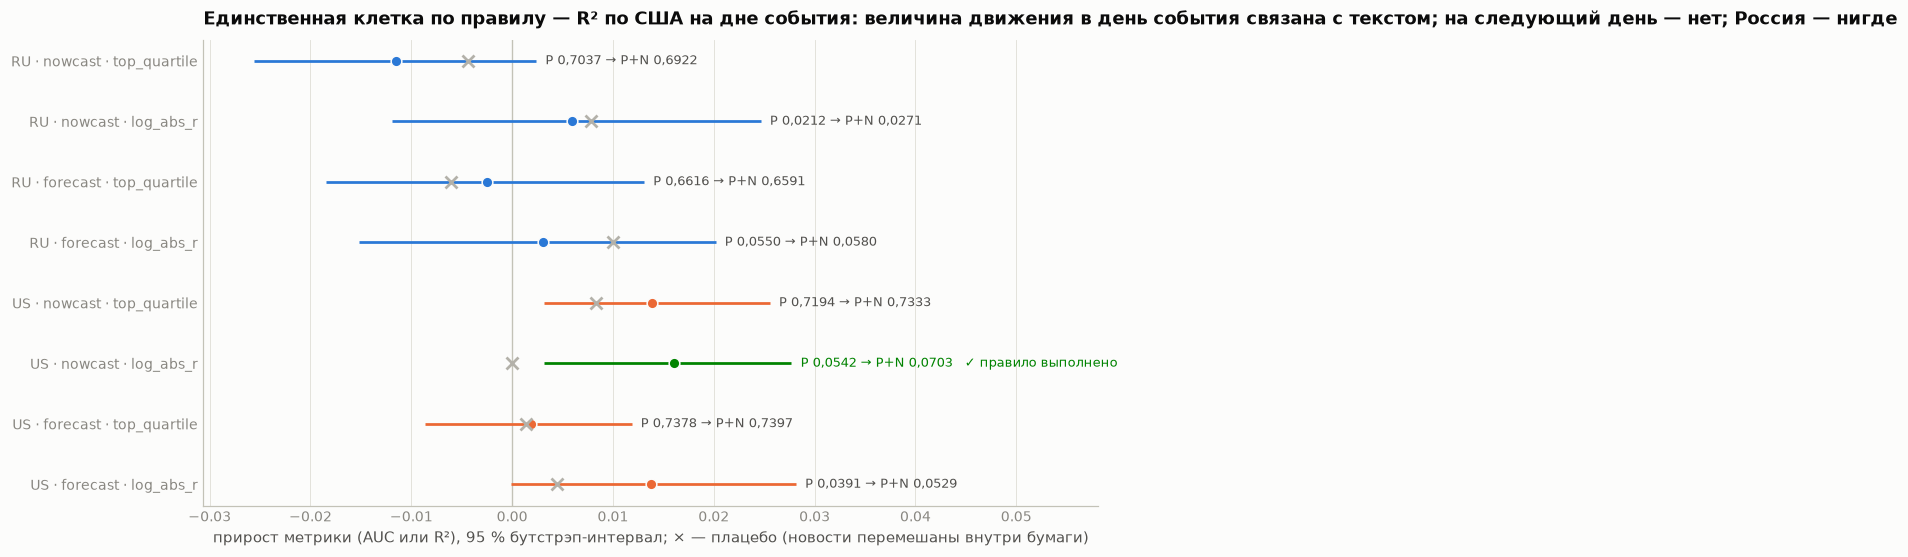

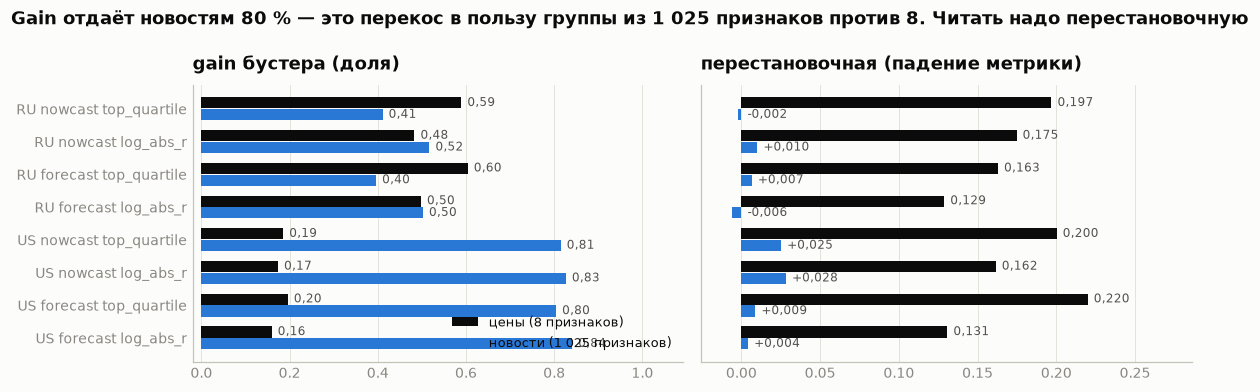

In [31]:
@S.show("c2_results", title="C2: прирост P+N над P")
def _(c2):
    c2["label"] = c2.market + " · " + c2.horizon + " · " + c2.task.replace({"R2": "R² log|r|"})
    fig, ax = plt.subplots(figsize=(10.5, 0.55 * len(c2) + 1.1))
    y = np.arange(len(c2))[::-1]
    for yi, (_, r) in zip(y, c2.iterrows()):
        c = COLORS["pos"] if r.passed else market_color(r.market)
        ax.hlines(yi, r.lo, r.hi, color=c, lw=1.8); ax.plot([r.gain], [yi], "o", color=c, ms=7, markeredgecolor=COLORS["surface"])
        ax.plot([r.placebo], [yi], "x", color=COLORS["placebo"], ms=8, mew=1.8)
        ax.annotate(f"P {fmt(r.p, 4)} → P+N {fmt(r.pn, 4)}" + ("   ✓ правило выполнено" if r.passed else ""), (max(r.hi, r.placebo), yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=COLORS["pos"] if r.passed else COLORS["ink2"])
    zero_line(ax); ax.set_yticks(y); ax.set_yticklabels(c2.label, fontsize=9); ax.grid(axis="x"); ax.grid(False, axis="y")
    ax.set_xlim(c2.lo.min() - 0.005, c2.hi.max() + 0.03)
    ax.set_xlabel("прирост метрики (AUC или R²), 95 % бутстрэп-интервал; × — плацебо (новости перемешаны внутри бумаги)")
    ax.set_title("Единственная клетка по правилу — R² по США на дне события: величина движения в день события связана с текстом; на следующий день — нет; Россия — нигде")
    return fig

@S.show("c2_importance", title="Важности: gain против перестановочной")
def _(imp):
    imp["label"] = imp.market + " " + imp.horizon + " " + imp.task.replace({"R2": "R²"})
    labs = list(dict.fromkeys(imp.label))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    for ax, meth, ttl in zip(axes, ["gain", "permutation"], ["gain бустера (доля)", "перестановочная (падение метрики)"]):
        d = imp[imp.method == meth].set_index("label").reindex(labs)
        y = np.arange(len(d))[::-1]
        ax.barh(y + 0.18, d.prices, height=0.34, color=COLORS["ink"], label="цены (8 признаков)")
        ax.barh(y - 0.18, d.news, height=0.34, color=COLORS["RU"], label="новости (1 025 признаков)")
        ax.set_yticks(y); ax.set_yticklabels(labs, fontsize=9); ax.set_title(ttl); ax.grid(axis="x"); ax.grid(False, axis="y")
        for yi, (p, n) in zip(y, zip(d.prices, d.news)):
            ax.annotate(fmt(p, 2 if meth == "gain" else 3), (p, yi + 0.18), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=COLORS["ink2"])
            ax.annotate(fmt(n, 2 if meth == "gain" else 3, plus=(meth != "gain")), (max(n, 0), yi - 0.18), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=COLORS["ink2"])
        ax.set_xlim(min(0, d[["prices", "news"]].min().min()) - 0.02, d[["prices", "news"]].max().max() * 1.3)
    axes[0].legend(loc="lower right", fontsize=8.5)
    fig.suptitle("Gain отдаёт новостям 80 % — это перекос в пользу группы из 1 025 признаков против 8. Читать надо перестановочную", x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.tight_layout()
    return fig

### 5.3 C3 — типы событий по слабым меткам 8-K

Новость верхнего яруса про ту же компанию в пределах ±1 дня от подачи 8-K получает код item этой
подачи. Метка слабая по построению, поэтому macro-F1 читается как «насколько текст новости предсказуем
типом корпоративного раскрытия», а не как качество разметки.

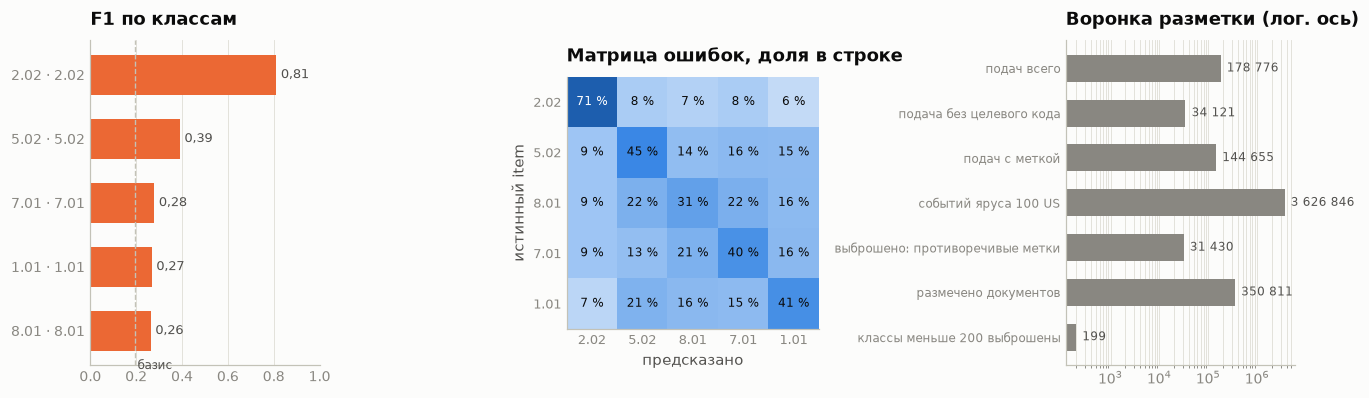

In [32]:
@S.show("c3_summary", "c3_per_class", "c3_confusion", "c3_funnel", title="C3: качество по классам и матрица ошибок")
def _(sm, pc, cf, fn):
    display(stat_tiles([(fmt(sm["macro_f1"], 3), "macro-F1 на отложенных", f"с {sm['split_date']}, n = {fmt_int(sm['n_test'])}"),
                        (fmt(sm["baseline_majority"], 3), "базис: класс большинства", ""), (fmt(sm["baseline_stratified"], 3), "базис: случайный по долям", ""),
                        (fmt_int(sm["n_train"]), "документов в обучении", sm.get("model", ""))]))
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1, 1.1, 1]})
    ax = axes[0]
    pc = pc.sort_values("f1", ascending=True)
    bars = ax.barh([f"{i} · {l}" for i, l in zip(pc["item"], pc.label)], pc.f1, color=COLORS["US"], height=0.62); label_bars(ax, bars, fmt_fn=lambda v: fmt(v, 2), horizontal=True)
    ax.axvline(sm["baseline_stratified"], color=COLORS["axis"], lw=0.9, ls="--"); ax.text(sm["baseline_stratified"] + 0.01, -0.6, "базис", fontsize=8, color=COLORS["ink2"])
    ax.set_xlim(0, 1); ax.set_title("F1 по классам"); ax.grid(axis="x"); ax.grid(False, axis="y")
    ax = axes[1]
    items = list(pc.sort_values("support", ascending=False)["item"])
    m = cf.pivot_table(index="true", columns="pred", values="count", aggfunc="sum").reindex(index=items, columns=items).fillna(0)
    rs = (m.T / m.sum(axis=1)).T.values
    ax.imshow(rs, cmap=mpl.colors.LinearSegmentedColormap.from_list("b", [COLORS["surface"]] + SEQ_BLUE[2:]), vmin=0, vmax=1)
    for i in range(len(items)):
        for j in range(len(items)):
            ax.text(j, i, pct(rs[i, j], 0), ha="center", va="center", fontsize=8, color="#ffffff" if rs[i, j] > 0.5 else COLORS["ink"])
    ax.set_xticks(range(len(items))); ax.set_xticklabels(items, fontsize=8.5); ax.set_yticks(range(len(items))); ax.set_yticklabels(items, fontsize=8.5)
    ax.set_xlabel("предсказано"); ax.set_ylabel("истинный item"); ax.set_title("Матрица ошибок, доля в строке"); ax.grid(False)
    ax = axes[2]
    fn = fn.copy(); fn["count_m"] = fn["count"]
    y = np.arange(len(fn))[::-1]
    ax.barh(y, fn.count_m, color=COLORS["muted"], height=0.6); ax.set_xscale("log")
    for yi, (_, r) in zip(y, fn.iterrows()):
        ax.annotate(fmt_int(r["count"]), (r.count_m, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=COLORS["ink2"])
    ax.set_yticks(y); ax.set_yticklabels(fn["step"], fontsize=8); ax.set_title("Воронка разметки (лог. ось)"); ax.grid(axis="x", which="both"); ax.grid(False, axis="y")
    fig.tight_layout()
    return fig

### 5.4 Крупным планом: одна бумага

Всё, что выше, — усреднение по тысячам бумаг. Здесь те же слои показаны на одной бумаге (по
умолчанию SBER): цена и события на ней, тональность во времени, к каким сюжетам карты относятся её
новости, реакция вокруг её событий против плацебо, и ближайшие соседи по эмбеддингу для трёх
заголовков — так видно, что именно сближает документы в пространстве bge-m3.

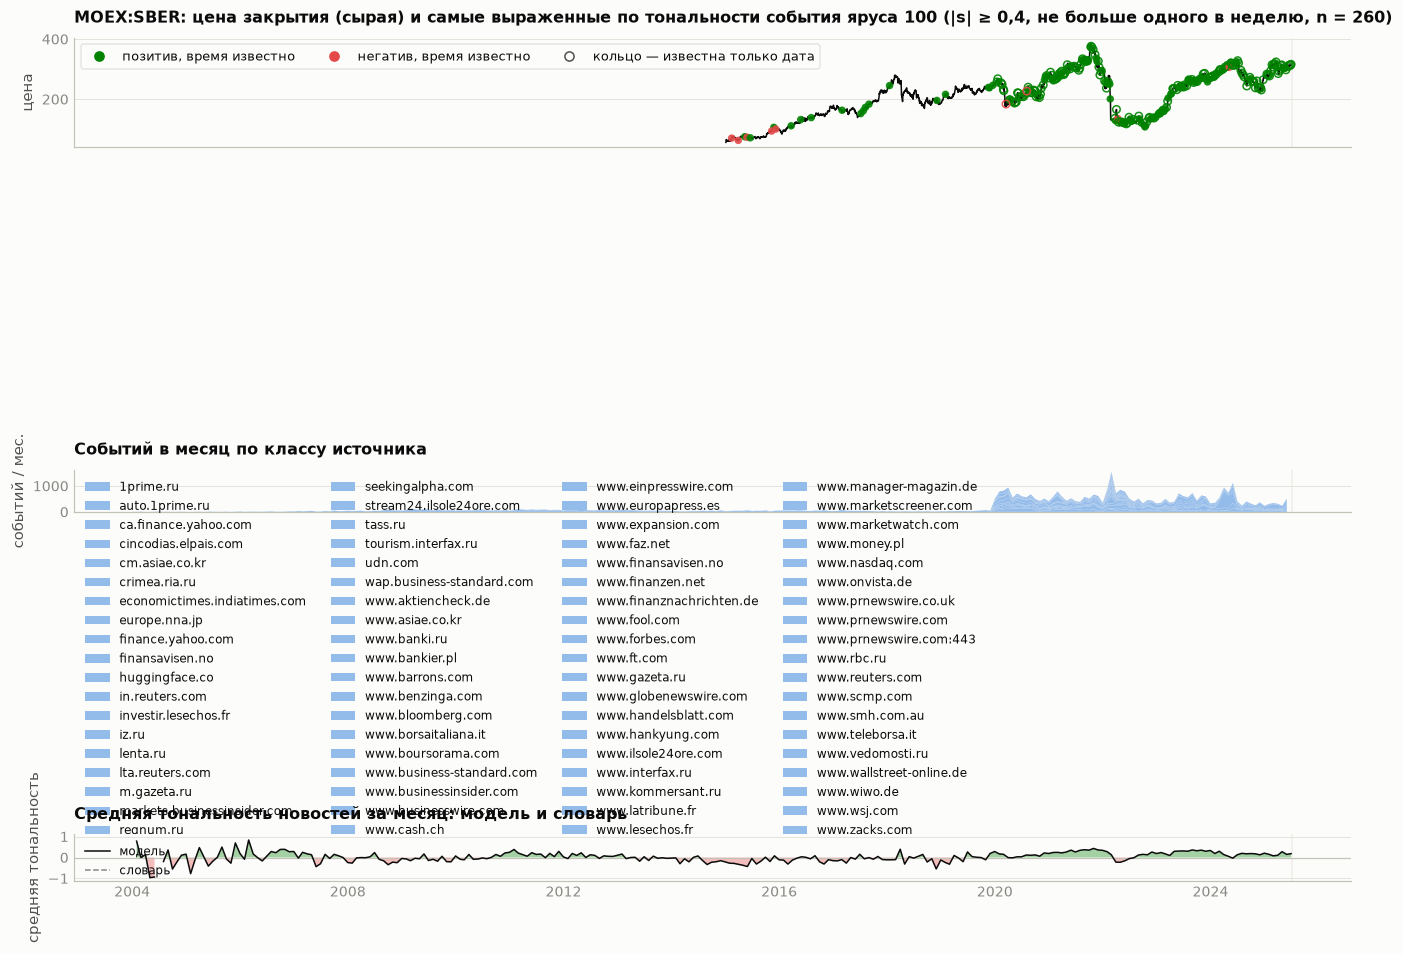

In [33]:
@S.show("case_prices", "case_events", title="Цена и события одной бумаги")
def _(px, ev):
    tk = px.ticker.iloc[0]
    px["date"] = pd.to_datetime(px.date); ev["date"] = pd.to_datetime(ev.date)
    ev100 = ev[ev.tier >= 100]
    fig, axes = plt.subplots(3, 1, figsize=(12.5, 8.4), sharex=True, gridspec_kw={"height_ratios": [2.6, 1, 1.1]})
    ax = axes[0]
    ax.plot(px.date, px.close, color=COLORS["ink"], lw=1.0)
    ev_px = ev100.merge(px[["date", "close"]], on="date", how="inner")
    big = ev_px[ev_px.sent_model.abs() >= 0.4].copy()
    big["abs_s"] = big.sent_model.abs(); big["wk"] = big.date.dt.to_period("W")
    big = big.sort_values("abs_s", ascending=False).groupby("wk", sort=False).head(1).head(260)  # не больше одного маркера в неделю
    col = np.where(big.sent_model > 0, COLORS["pos"], COLORS["neg"])
    known = big.time_known.astype(bool).to_numpy()
    ax.scatter(big.date[known], big.close[known], s=24, c=col[known], lw=0, alpha=0.9, zorder=3)
    ax.scatter(big.date[~known], big.close[~known], s=24, facecolors="none", edgecolors=col[~known], lw=1.0, alpha=0.9, zorder=3)
    ax.set_title(f"{tk}: цена закрытия (сырая) и самые выраженные по тональности события яруса 100 (|s| ≥ 0,4, не больше одного в неделю, n = {fmt_int(len(big))})", fontsize=10.5)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=COLORS["pos"], label="позитив, время известно"), Line2D([], [], marker="o", ls="", color=COLORS["neg"], label="негатив, время известно"),
                       Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor=COLORS["ink2"], label="кольцо — известна только дата")],
              loc="upper left", bbox_to_anchor=(0, 1.0), fontsize=8.5, ncol=3, frameon=True, facecolor=COLORS["surface"], edgecolor=COLORS["grid"])
    ax.set_ylabel("цена")
    ax = axes[1]
    m = ev.groupby([ev.date.dt.to_period("M").dt.to_timestamp(), "source_class"]).size().unstack(fill_value=0)
    shades = {"пресса": 0.0, "раскрытия": 0.4, "агрегаторы": 0.7, "прочее": 0.85}
    cols = [mpl.colors.to_hex(np.array(mpl.colors.to_rgb(COLORS["RU"])) * (1 - shades.get(c, 0.5)) + np.array([1, 1, 1]) * shades.get(c, 0.5)) for c in m.columns]
    ax.stackplot(m.index, m.T.values, colors=cols, labels=m.columns, lw=0); ax.legend(ncol=4, fontsize=8, loc="upper left"); ax.set_ylabel("событий / мес.")
    ax.set_title("Событий в месяц по классу источника", fontsize=10.5)
    ax = axes[2]
    try:
        s = ev.set_index("date")[["sent_model", "sent_dict"]].resample("ME").mean()
    except ValueError:  # pandas < 2.2
        s = ev.set_index("date")[["sent_model", "sent_dict"]].resample("M").mean()
    ax.axhline(0, color=COLORS["axis"], lw=0.8)
    ax.fill_between(s.index, 0, s.sent_model, where=s.sent_model >= 0, color=COLORS["pos"], alpha=0.35, lw=0, interpolate=True)
    ax.fill_between(s.index, 0, s.sent_model, where=s.sent_model < 0, color=COLORS["neg"], alpha=0.35, lw=0, interpolate=True)
    ax.plot(s.index, s.sent_model, color=COLORS["ink"], lw=1.0, label="модель"); ax.plot(s.index, s.sent_dict, color=COLORS["muted"], lw=1.0, ls="--", label="словарь")
    lim = max(0.3, float(np.nanmax(np.abs(s.to_numpy()))) * 1.15); ax.set_ylim(-lim, lim); ax.set_ylabel("средняя тональность"); ax.set_title("Средняя тональность новостей за месяц: модель и словарь", fontsize=10.5); ax.legend(fontsize=8, loc="upper left")
    for a in axes: a.axvspan(pd.Timestamp("2025-07-01"), px.date.max() + pd.Timedelta(days=15), color=COLORS["band"], alpha=0.6, lw=0)
    fig.tight_layout()
    return fig

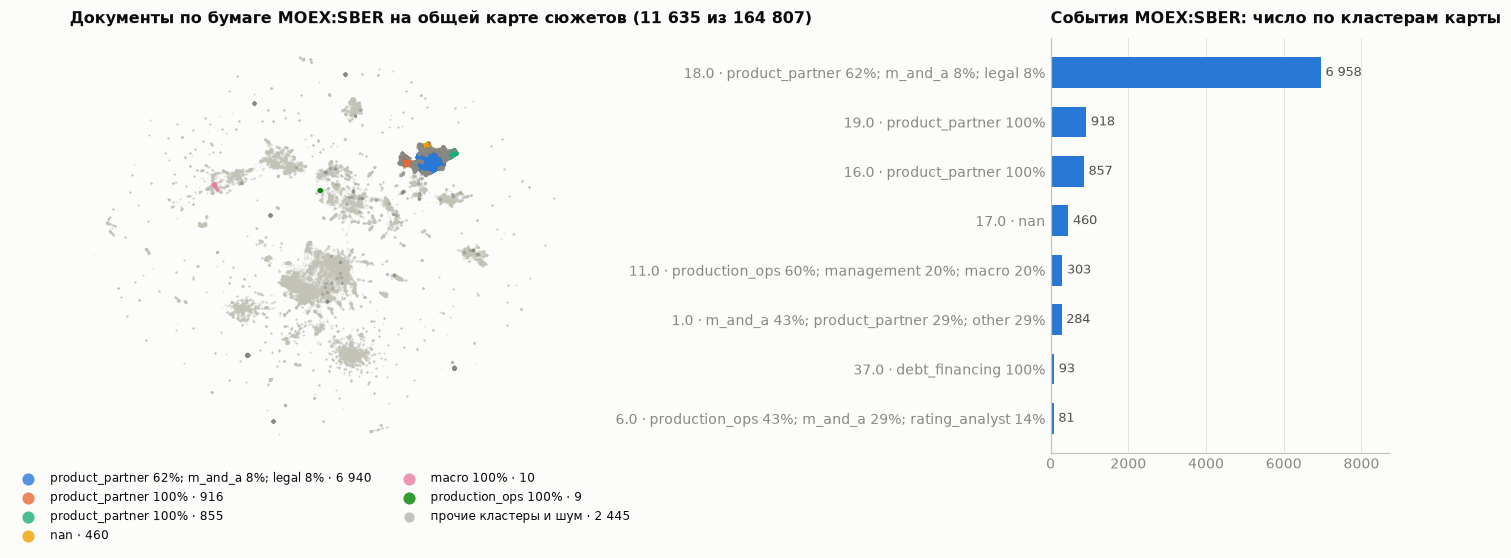

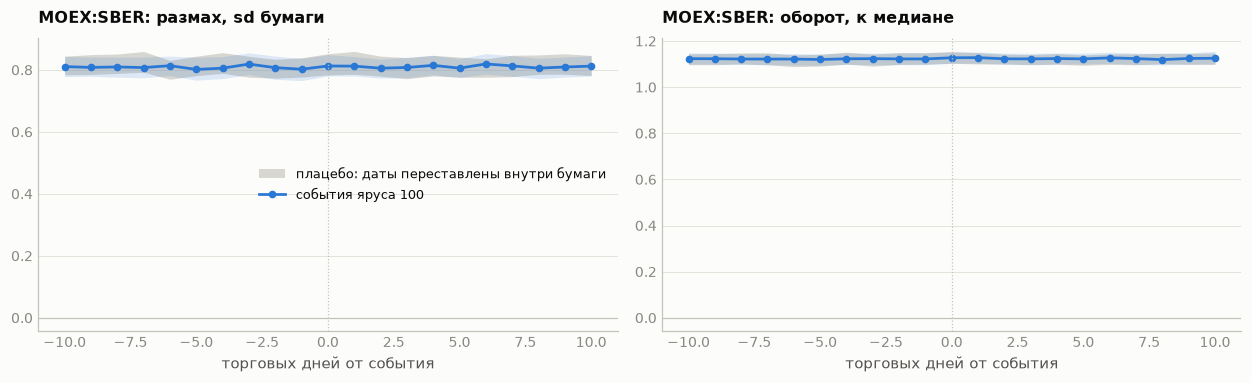

запрос,пять ближайших документов (косинус)
Сбербанк не решился выплатить акционерам высокие дивиденды 2010-06-03,"2011-03-20 · lenta · MOEX:SBER Сбербанк потратит на дивиденды акционерам более 20 миллиардов рублей 0,8772020-08-21 · ccnews · MOEX:SBER Сбербанк собирается направить на дивиденды более 400 млрд рублей 0,8682016-05-26 · lenta · MOEX:SBER Сбербанк раздаст 20 процентов прибыли акционерам 0,8662020-08-21 · ccnews · MOEX:SBER Набсовет Сбербанка предлагает направить на дивиденды за 2019 год 422,4 млрд руб. 0,8452020-08-21 · ccnews · MOEX:SBER Сбербанк направит на дивиденды 422,5 млрд рублей 0,842"
Греф вернет Сбербанк в Крым после смягчения санкций 2016-05-26,"2015-05-28 · lenta · MOEX:SBER Сбербанк отказался работать в Крыму 0,8462024-01-18 · ccnews · MOEX:SBER Сбер намерен удвоить свою долю в Крыму в 2024 году 0,7872024-08-13 · ccnews · MOEX:SBER «Сбер» запланировал занять 25% на рынке Крыма к концу года 0,7742023-12-06 · ccnews · MOEX:SBER Сбербанк прокомментировал возможность новых приобретений за рубежом 0,7702024-08-13 · ccnews · MOEX:SBER Сбербанк к концу года планирует занять 20-25% банковского рынка Крыма 0,769"
Сбербанк пожаловался в Кремль на законопроект о платежных терминалах 2009-04-08,"2014-01-23 · lenta · MOEX:SBER Глава Сбербанка вступился за онлайн-платежи 0,8122020-01-21 · ccnews · MOEX:SBER Сбербанк направил в ЦБ предложения по улучшению информационной безопасности СБП 0,7142020-01-21 · ccnews · MOEX:SBER Сбербанк направил в ЦБ предложения по улучшению информационной безопасности СБП 0,7112021-08-26 · ccnews · MOEX:SBER Сбербанк предложит решения по механизму возврата списанных соцвыплат в счет долгов 0,7002020-02-11 · ccnews · MOEX:SBER Сбербанк намерен подключиться к системе быстрых платежей к концу марта 0,698"


In [34]:
@S.show("case_events", "c1_points", "c1_clusters", title="К каким сюжетам карты относятся новости бумаги")
def _(ev, pts, cl):
    tk = ev.ticker.iloc[0]
    names = cl.set_index("cluster").label
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
    ax = axes[0]
    bg = pts.sample(min(len(pts), 40_000), random_state=3) if len(pts) > 40_000 else pts
    ax.scatter(bg.x, bg.y, s=1.5, c=COLORS["axis"], alpha=0.3, lw=0, rasterized=True)
    mine = pts[pts.ticker == tk]
    if len(mine):
        top = mine[mine.cluster != -1].cluster.value_counts().head(6)
        for (c, n), col in zip(top.items(), CATEGORICAL):
            d = mine[mine.cluster == c]
            ax.scatter(d.x, d.y, s=7, c=col, alpha=0.8, lw=0, label=f"{names.get(c, c)} · {fmt_int(n)}", rasterized=True)
        rest = mine[~mine.cluster.isin(top.index)]
        ax.scatter(rest.x, rest.y, s=5, c=COLORS["muted"], alpha=0.5, lw=0, label=f"прочие кластеры и шум · {fmt_int(len(rest))}", rasterized=True)
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), fontsize=8, markerscale=3, ncol=2)
    ax.set_title(f"Документы по бумаге {tk} на общей карте сюжетов ({fmt_int(len(mine))} из {fmt_int(len(pts))})", fontsize=10.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); despine_all(ax)
    ax = axes[1]
    cc = ev[ev.cluster != -1].cluster.value_counts().head(8)
    lab = [f"{c} · {names.get(c, '')}" for c in cc.index][::-1]
    bars = ax.barh(lab, cc.values[::-1], color=COLORS["RU"], height=0.62); label_bars(ax, bars, fmt_fn=fmt_int, horizontal=True)
    ax.set_title(f"События {tk}: число по кластерам карты", fontsize=10.5); ax.grid(axis="x"); ax.grid(False, axis="y"); ax.set_xlim(0, cc.max() * 1.25)
    fig.tight_layout()
    return fig

@S.show("case_reaction", title="Реакция вокруг событий одной бумаги против плацебо")
def _(cr):
    tk = cr.ticker.iloc[0]
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
    for ax, (col, lo, hi, ttl) in zip(axes, [("absr_n", "absr_lo", "absr_hi", "размах, sd бумаги"), ("turn_r", "turn_lo", "turn_hi", "оборот, к медиане")]):
        pl = cr[cr.subsample == "плацебо"].sort_values("k"); evd = cr[cr.subsample == "события"].sort_values("k")
        ax.fill_between(pl.k, pl[lo], pl[hi], color=COLORS["placebo"], alpha=0.5, lw=0, label="плацебо: даты переставлены внутри бумаги")
        ax.fill_between(evd.k, evd[lo], evd[hi], color=COLORS["RU"], alpha=0.15, lw=0); ax.plot(evd.k, evd[col], "-o", color=COLORS["RU"], ms=4, label="события яруса 100")
        ax.axhline(0, color=COLORS["axis"], lw=0.8); ax.axvline(0, color=COLORS["axis"], lw=0.8, ls=":"); ax.set_title(f"{tk}: {ttl}", fontsize=10.5); ax.set_xlabel("торговых дней от события")
    axes[0].legend(fontsize=8.5)
    fig.tight_layout()
    return fig

@S.show("case_neighbors", title="Ближайшие соседи по эмбеддингу")
def _(nb):
    rows = []
    for q, g in nb.groupby(["query_title", "query_date"], sort=False):
        rows.append({"запрос": f"<b>{q[0]}</b> <span style='color:#898781'>{q[1]}</span>",
                     "пять ближайших документов (косинус)": "<br>".join(f"<span style='color:#898781'>{d} · {s} · {t}</span> {ti} <span style='color:#2a78d6'>{fmt(c, 3)}</span>"
                                                                       for d, s, t, ti, c in zip(g.nb_date, g.nb_source, g.nb_ticker, g.nb_title, g.cos))})
    return pd.DataFrame(rows)

<a id="6"></a>
## 6. Контроль против самообмана

Отдельный слой работы, объясняющий, почему числам можно верить. Реестр проверок хранит каждую
посчитанную строку с хешем кода, временем, хостом и видом; аннулирование — только ссылкой на `id`,
ничего не стирается.

контроль,как устроен,где применён
плацебо,даты событий переставлены внутри бумаги,"H1, H2-H4, H13, H14, H19, C2, глава 06"
сдвиг сигнала,внимание дня t от событий t−2,"H1, диагностики H1b"
подпериоды,"P1 ≤2019, P2 2020-21, P3 2022, P4 ≥2023","главы 05, 06, диагностики H1b"
ярусы как контроль,эффект обязан расти с ярусом,H13
разрез по известности времени,реакция против ассоциации,глава 06.7
разрез по классу источника,пресса против раскрытий EDGAR,диагностики H1b
порог t ≥ 3,"Харви-Лю-Чжу вместо 1,96",все гипотезы
поправка Холма,внутри семейства гипотезы,реестр
реестр проверок,"хеш кода, время, хост, вид строки; аннулирование по id",весь проект
сдутый Шарп,"поправка на число испытаний, асимметрию и хвосты","controls.py, H9"


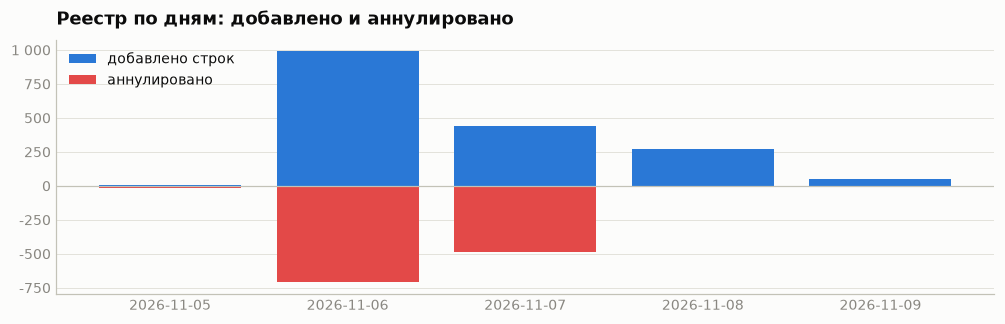

In [35]:
S.show_table("controls", title="Контроли", columns={"control": "контроль", "how": "как устроен", "where": "где применён"})

@S.show("registry_stats", "registry_timeline", title="Реестр проверок")
def _(rs, rt):
    display(stat_tiles([(fmt_int(rs["rows"]), "строк в реестре", f"{rs['first_date']} → {rs['last_date']}"), (fmt_int(rs["live"]), "действующих", "live()"),
                        (fmt_int(rs["voided"]), "аннулировано", "void(voided_id), со ссылкой на причину"), (fmt_int(len(rs.get("hosts", []))), "хостов", ", ".join(rs.get("hosts", [])))]))
    rt["date"] = pd.to_datetime(rt.date)
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.bar(rt.date, rt.added, color=COLORS["RU"], width=0.8, label="добавлено строк")
    ax.bar(rt.date, -rt.voided, color=COLORS["neg"], width=0.8, label="аннулировано")
    ax.axhline(0, color=COLORS["axis"], lw=0.8); ax.legend(loc="upper left"); ax.set_title("Реестр по дням: добавлено и аннулировано")
    ru_axis(ax, "y", 0)
    return fig

<a id="7"></a>
## 7. Чего не измерено

Статус «не измерено» — а не прочерк: для каждого пункта названа причина.

In [36]:
S.show_table("not_measured", title="Не измерено", columns={"item": "пункт", "why": "почему"})

пункт,почему
"глава 05, пункты 5, 6, 8, 9, 10","микроструктура, кросс-секция, режимы, фьючерсы, скачки - не считались"
H12 (эмбеддинги сверх тональности и типа),не запускался: в реестре 0 строк
набор C в C2 (только новости),не прогонялся
знаковые цели в C2,считались только беззнаковые
purged walk-forward по фолдам в C2,одно разбиение по времени
"SHAP-взаимодействия, MDI/MDA/SFI, adversarial validation",не делались
сравнение тональностей словарь/модель/LLM,не делалось
внутридневной знак реакции в главе 06,"93,9 % минутных отметок ccnews - полночь UTC"
латентность публикации,"first_seen_at = published_at посекундно у 99,93 %"
капитализация США,"в проекте нет; собрано число акций, пересчёт возможен"


<a id="8"></a>
## 8. Что получилось: семь утверждений

In [37]:
@S.show("statements", title="Семь утверждений")
def _(st):
    tiles = [(s["hero"]["value"], s["hero"]["label"], f"утверждение {s['n']}") for s in st if s.get("hero")]
    display(stat_tiles(tiles, cols=4))
    body = "\n\n".join(f"**{s['n']}. {s['title']}.** {s['text']}" for s in st)
    return Markdown(body)

**1. Новости видны в данных — но только при правильном сопоставлении.** Размах движения в день с событием выше на 10 % (RU) и 23 % (US) к уровню контрольного дня той же бумаги в том же месяце. Сырое сравнение по обороту России даёт противоположный знак: −0,615 против +0,410 сопоставленного.

**2. Это совпадение, а не доказанная реакция.** У 97 % событий США и 84 % России известна только дата. Там, где время известно, превышение сохраняется (US размах 0,187 [0,154; 0,219]), но подвыборка смещена по источникам.

**3. Новости улучшают прогноз волатильности.** Единственный результат, прошедший все три диагностики: плацебо исчезло (t = 0,65), «несвежие» новости дают в 18 раз меньше, раскрытия EDGAR с точным временем дают больше прессы.

**4. Текст связан с величиной движения в день события — но не предсказывает следующий.** Прирост R² +0,0160 [+0,0031; +0,0277] при плацебо 0,0000 на nowcast; на прогнозе t+1 интервал накрывает ноль. По России нет нигде.

**5. Знаковой реакции на тональность не найдено.** Асимметрия негатив−позитив +3,87 п.п. [−11,78; 21,59] у RU и +0,34 [−1,29; 1,02] у US. Исключение — неликвидная терция России: −0,541 п.п. [−1,15; −0,073].

**6. Среди раскрытий сильнее всех результаты за период.** 8-K item 2.02 даёт 4,801 п.п. |AR[0,1]| против 1,78–2,45 у остальных классов; все разности далеко от нуля на 519 204 наблюдениях.

**7. Реакция быстрая, но до открытия, а не в первый час торгов.** За час проходит 26,4 % хода и 14,1 % объёма, за два — 49,3 % хода. У внесессионных подач ночной разрыв объясняет 83,4 % движения.

**8. Рынок устроен по классике — кроме минуток.** Тяжёлые хвосты (Хилл 2,0–3,3: четвёртого момента не существует), отсутствие линейной автокорреляции, кластеризация волатильности, долгая память (Хёрст 0,81–0,95 при контроле 0,44–0,52), отрицательный рычаг. На минутках автокорреляция велика, и её знак задаёт ликвидность, а не страна: это свойство измерения.

---
### Воспроизводимость

* Артефакты: `mea export-report` → `data/cache/report/` (контракт — `notebooks/CONTRACT.md`); тот же
  набор отдаёт сервер по `GET /report/artifacts/<name>.<ext>`.
* Бэкенд: `MEA_REPORT_BACKEND=local|api|demo`; `MEA_REPORT_DIR`, `MEA_REPORT_API`.
* HTML одним файлом: `jupyter nbconvert --to html --execute --no-input notebooks/EDA_report.ipynb
  --output EDA_report.html` (без `--no-input`, если нужен код).
* Проверка без Jupyter: `python notebooks/run_check.py --strict`.

In [38]:
S.summary()